# 3_data-exploration

## 11.3.26 | ordinate the data

In [1]:
# Load packages
suppressPackageStartupMessages({
    library(phyloseq)
    library(tidyverse)
    library(data.table)
    library(microbiome)
})
    
options(repr.plot.width=15, repr.plot.height=8)

In [2]:
# Read in relative abundance phyloseq object
ps_rel <- readRDS("/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/ps-objects/ps-dada2-rel.rds")

In [3]:
# Add label to negative and positive controls in the tissue column
sample_data(ps_rel)$Tissue[grepl("negative", sample_names(ps_rel))] <- "Negative_control"
sample_data(ps_rel)$Tissue[grepl("Positive", sample_names(ps_rel))] <- "Positive_control"

### All ASVs

In [13]:
# Compute distance matrix
dist_bray <- phyloseq::distance(ps_rel, method = "bray")

In [15]:
# Ordinate using PCoA
ord_bray.pcoa <- ordinate(ps_rel, method = "PCoA", distance = dist_bray)

# Variance explained by each axis
ord_bray.pcoa$values$Relative_eig[1:5] %>% round(3)

[1] 0.145 0.094 0.063 0.049 0.037

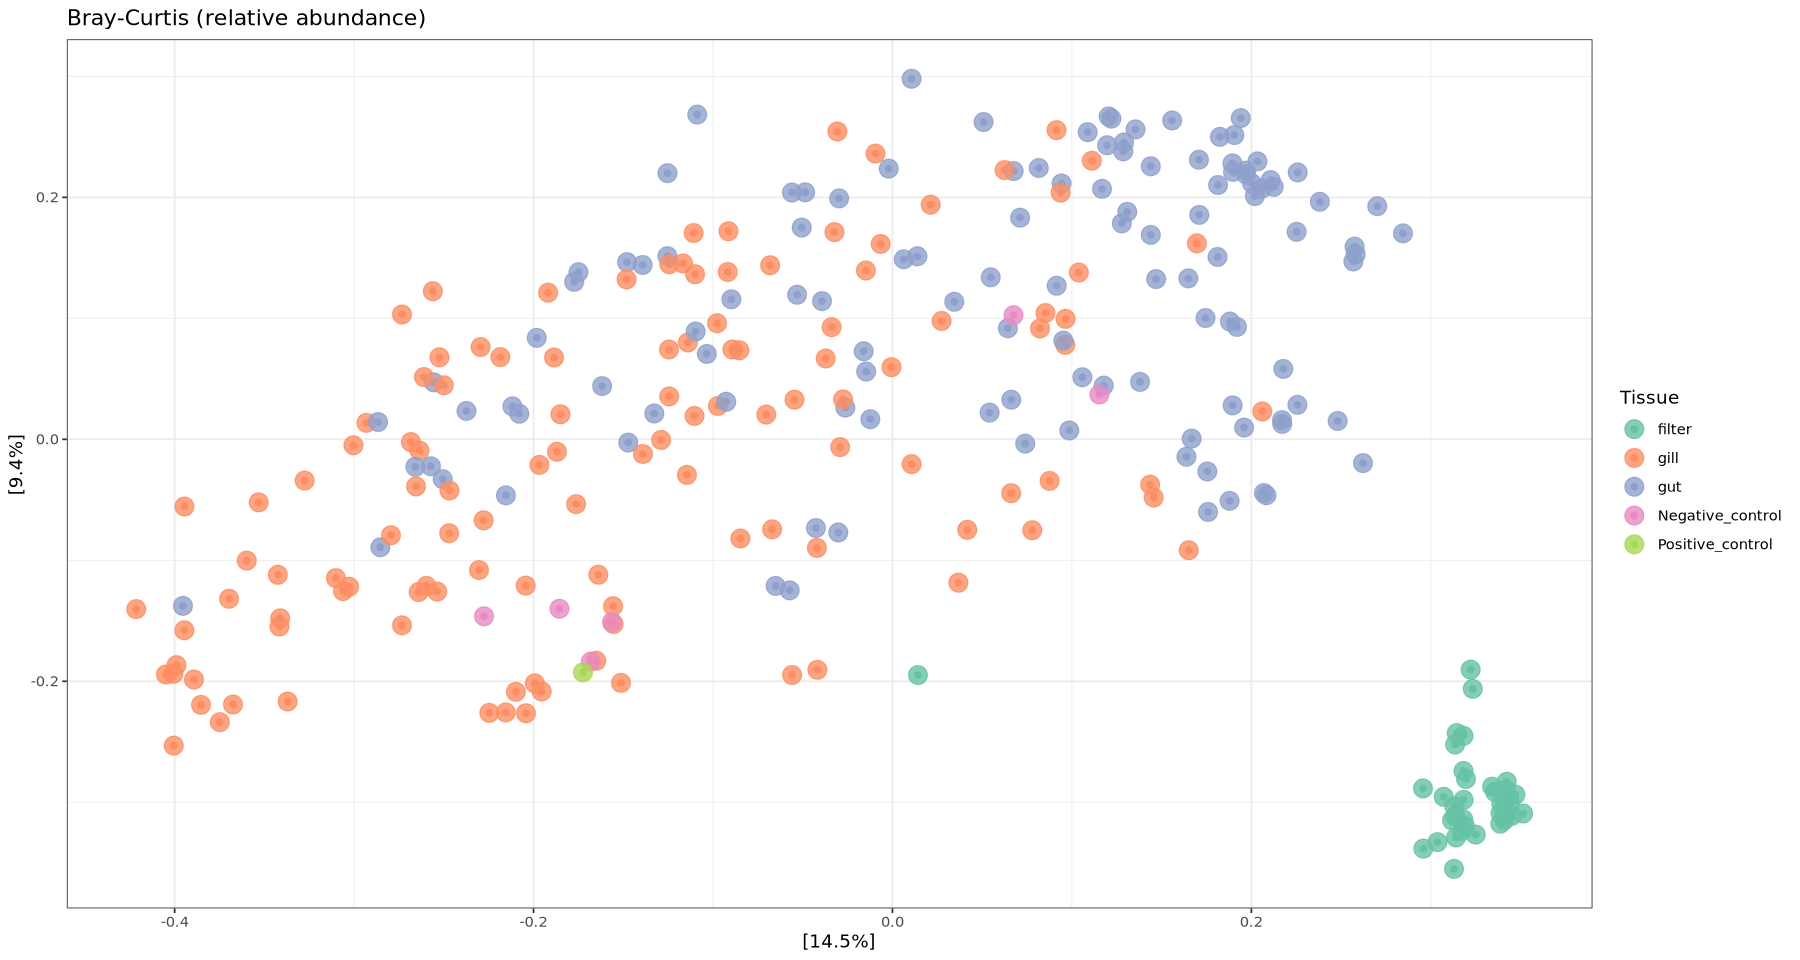

In [17]:
# Visualize PCoA
p_bray.pcoa <- plot_ordination(ps_rel, ord_bray.pcoa, color = "Tissue") +
    geom_point(size = 5, alpha = 0.8) +
    scale_color_brewer(palette = "Set2") +
    labs(title = "Bray-Curtis (relative abundance)") +
    theme_bw() 

p_bray.pcoa

Negative controls cluster within tissue samples - likely some kind of contamination

In [8]:
# Ordinate using nMDS
ord_bray.nmds <- ordinate(ps_rel, method = "NMDS", distance = dist_bray)

Run 0 stress 0.1521457 
Run 1 stress 0.1545346 
Run 2 stress 0.1526187 
... Procrustes: rmse 0.02081203  max resid 0.1094799 
Run 3 stress 0.1546047 
Run 4 stress 0.1539031 
Run 5 stress 0.1557027 
Run 6 stress 0.1530063 
Run 7 stress 0.1562006 
Run 8 stress 0.1539657 
Run 9 stress 0.1536811 
Run 10 stress 0.1538967 
Run 11 stress 0.15411 
Run 12 stress 0.1560485 
Run 13 stress 0.1553669 
Run 14 stress 0.1558238 
Run 15 stress 0.1541674 
Run 16 stress 0.1528103 
Run 17 stress 0.1550904 
Run 18 stress 0.1538822 
Run 19 stress 0.1529157 
Run 20 stress 0.1553366 
*** Best solution was not repeated -- monoMDS stopping criteria:
    18: no. of iterations >= maxit
     2: stress ratio > sratmax


Can try to increase maximum iterations and/or try more random starts to find a stable solution to represent the data.

In [13]:
# nMDS stress value (< 0.2 okay)
ord_bray.nmds$stress

[1] 0.1521457

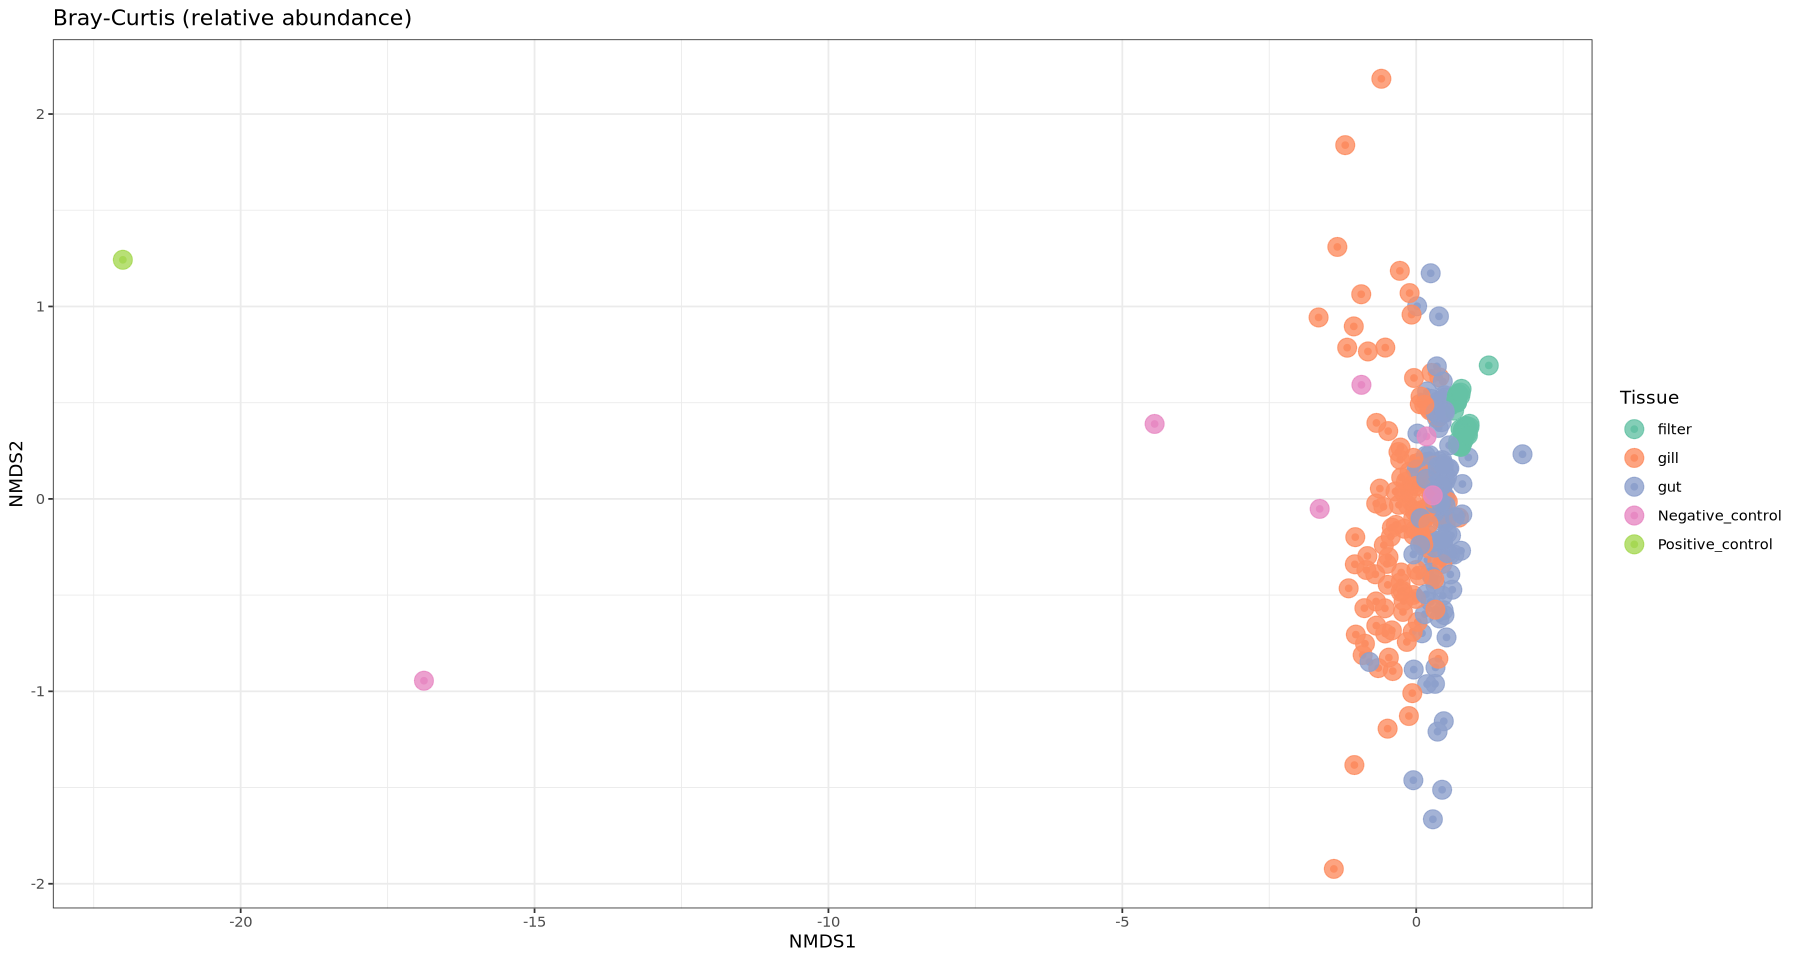

In [12]:
# Visualize nMDS
p_bray.nmds <- plot_ordination(ps_rel, ord_bray.nmds, type = "samples", color = "Tissue") +
    geom_point(size = 5, alpha = 0.8) +
    scale_color_brewer(palette = "Set2") +
    labs(title = "Bray-Curtis (relative abundance)") +
    theme_bw()
p_bray.nmds

Interesting that in a ranked sense, the positive control is so different - will remove controls.

### Samples only (no controls)

In [9]:
# Remove negatives
ps <- subset_samples(ps_rel, !Tissue %in% c("Negative_control", "Positive_control"))

# Remove taxa that are no longer present after subsetting
ps <- prune_taxa(taxa_sums(ps) > 0, ps)
ps

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 118935 taxa and 274 samples ]
sample_data() Sample Data:       [ 274 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 118935 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 118935 reference sequences ]

In [10]:
# Compute distance matrix
dist_bray <- phyloseq::distance(ps, method = "bray")

In [11]:
# Ordinate using PCoA
ord_bray.pcoa <- ordinate(ps, method = "PCoA", distance = dist_bray)

# Variance explained by each axis
ord_bray.pcoa$values$Relative_eig[1:5] %>% round(3)

[1] 0.149 0.097 0.065 0.050 0.038

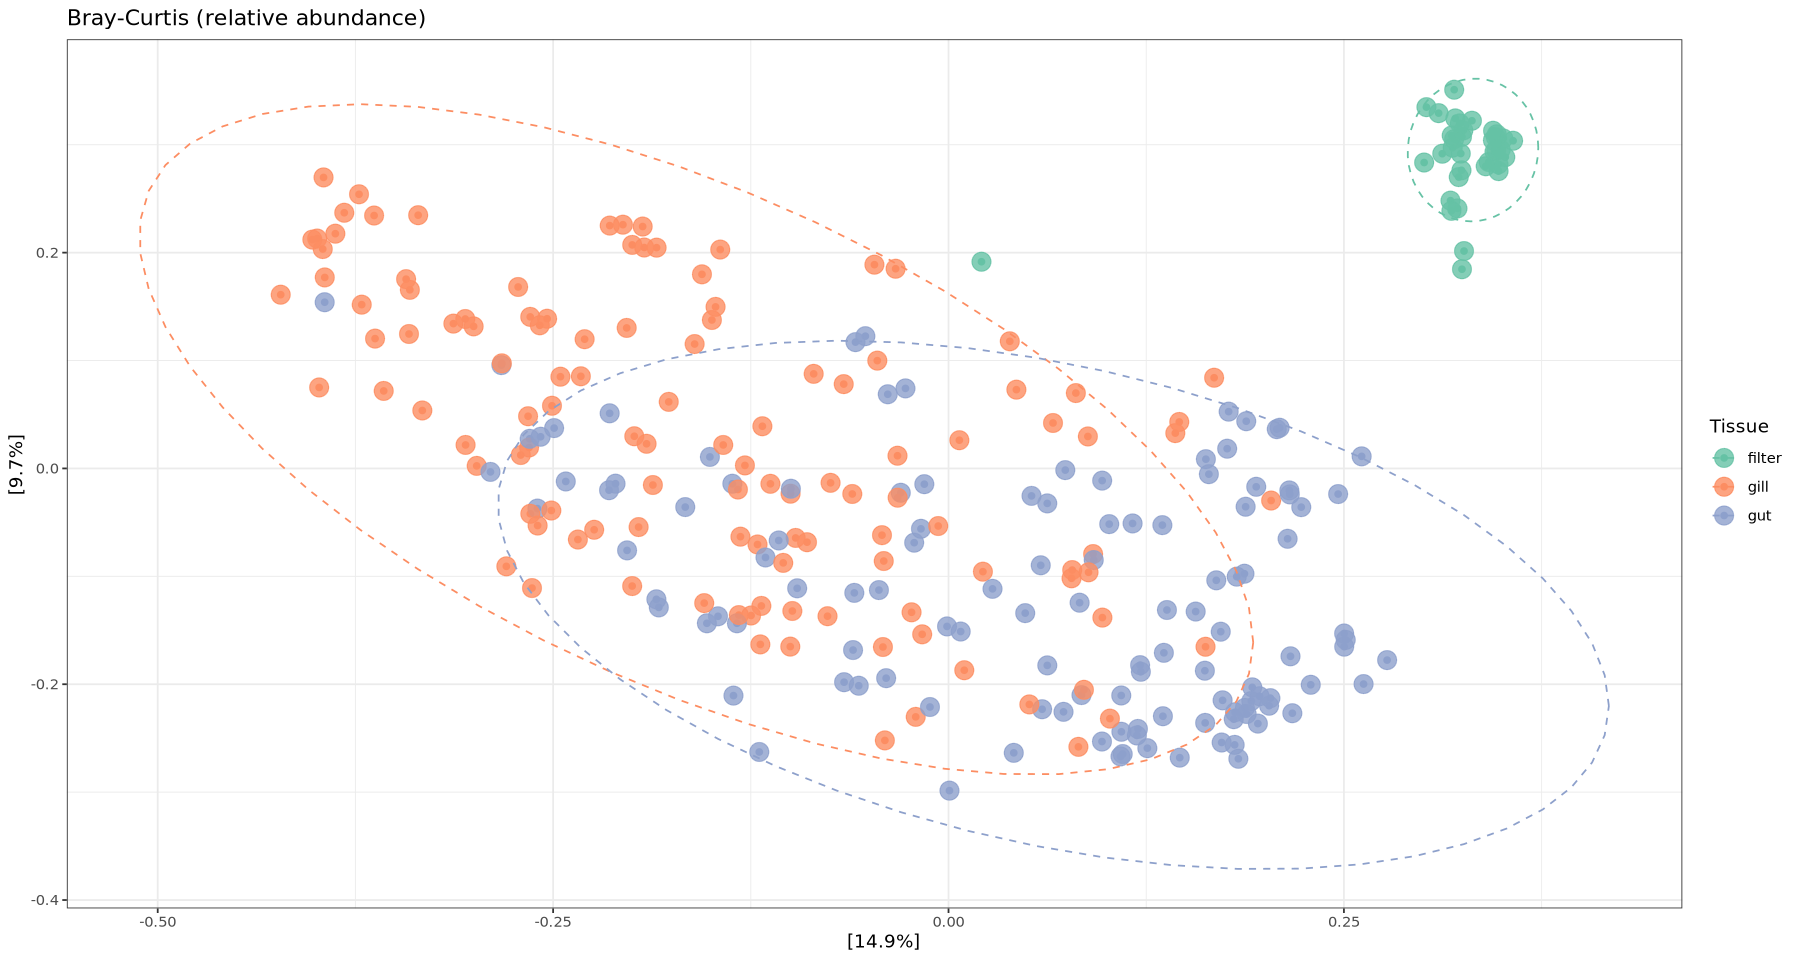

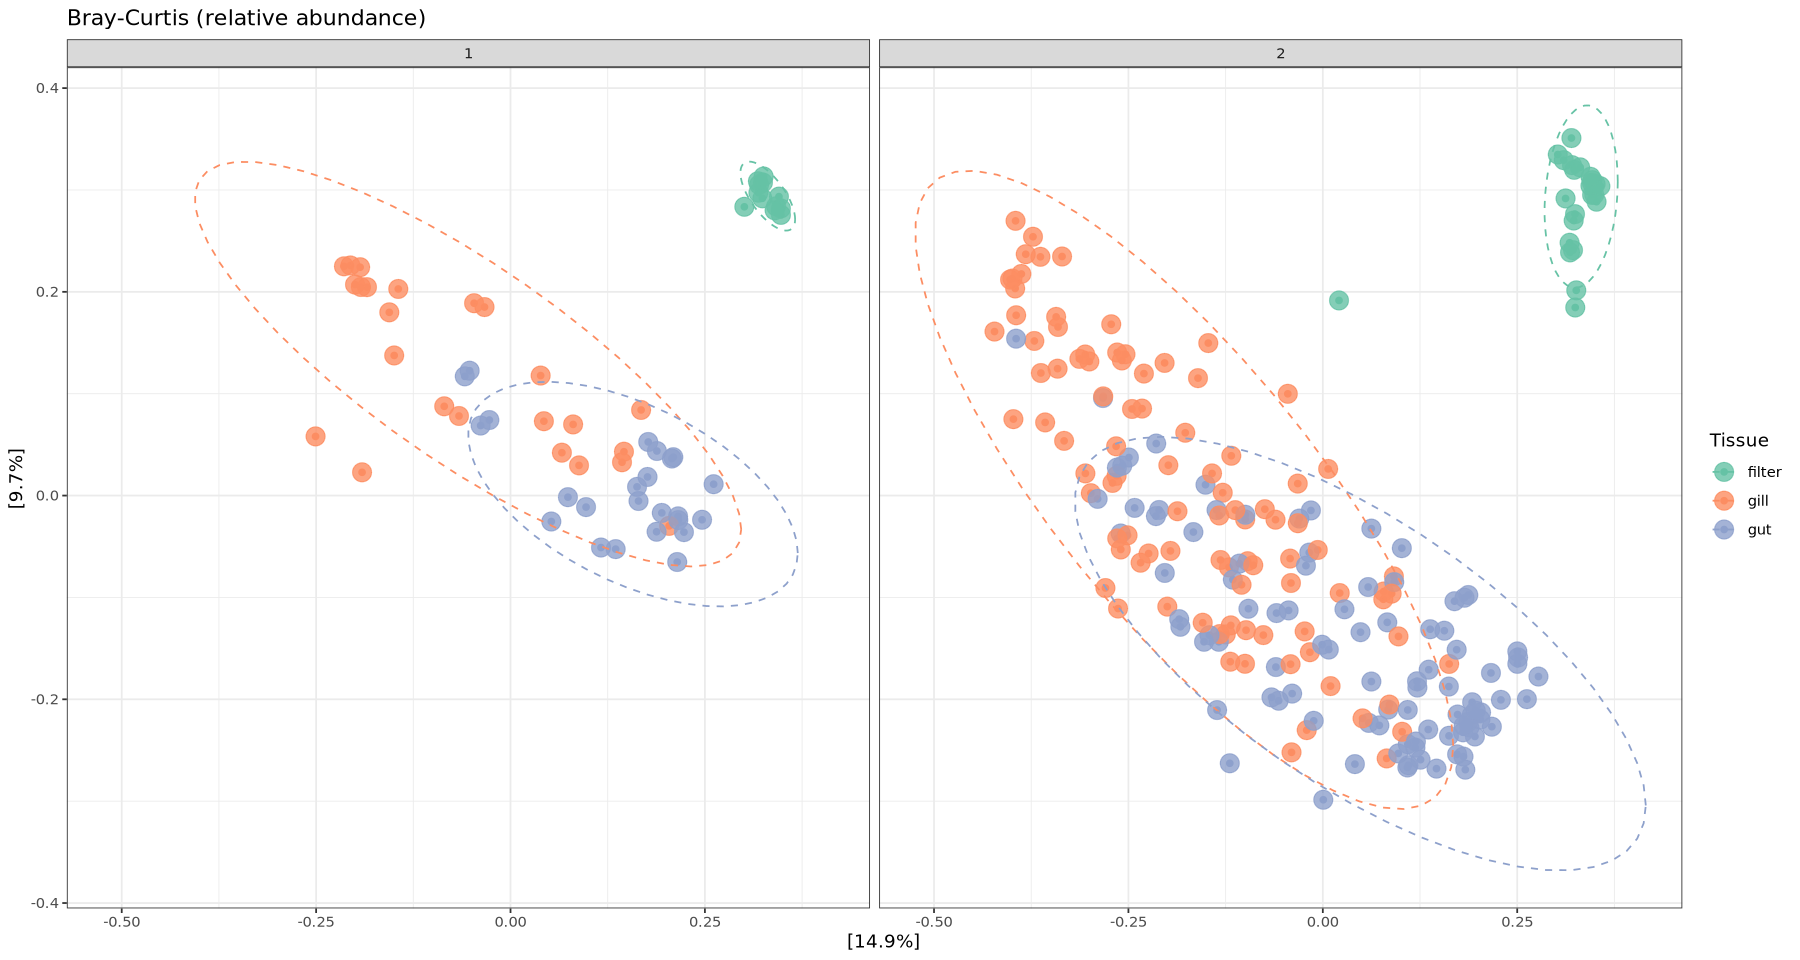

In [12]:
# Visualize PCoA
p_bray.pcoa <- plot_ordination(ps, ord_bray.pcoa, color = "Tissue") +
    geom_point(size = 5, alpha = 0.8) +
    scale_color_brewer(palette = "Set2") +
    labs(title = "Bray-Curtis (relative abundance)") +
    theme_bw() +
    stat_ellipse(aes(group = Tissue), level = 0.95, linetype = 2)

# Facet by phase
p_bray.pcoa_phase <- plot_ordination(ps, ord_bray.pcoa, type = "samples", color = "Tissue") +
    geom_point(size = 5, alpha = 0.8) +
    scale_color_brewer(palette = "Set2") +
    labs(title = "Bray-Curtis (relative abundance)") +
    facet_grid(. ~ Phase) +
    theme_bw() +
    stat_ellipse(aes(group = Tissue), level = 0.95, linetype = 2)

p_bray.pcoa
p_bray.pcoa_phase

In [23]:
# Ordinate using nMDS
ord_bray.nmds <- ordinate(ps, method = "NMDS", distance = dist_bray)

Run 0 stress 0.1970746 
Run 1 stress 0.2156498 
Run 2 stress 0.2154543 
Run 3 stress 0.2212068 
Run 4 stress 0.214455 
Run 5 stress 0.2129523 
Run 6 stress 0.2066746 
Run 7 stress 0.2243531 
Run 8 stress 0.2057145 
Run 9 stress 0.2115614 
Run 10 stress 0.2036896 
Run 11 stress 0.2189092 
Run 12 stress 0.2124705 
Run 13 stress 0.2064371 
Run 14 stress 0.2148564 
Run 15 stress 0.2220246 
Run 16 stress 0.2186218 
Run 17 stress 0.2107 
Run 18 stress 0.216946 
Run 19 stress 0.2140069 
Run 20 stress 0.2051328 
*** Best solution was not repeated -- monoMDS stopping criteria:
     5: no. of iterations >= maxit
    13: stress ratio > sratmax
     2: scale factor of the gradient < sfgrmin


In [24]:
# nMDS stress value (< 0.2 okay)
ord_bray.nmds$stress

[1] 0.1970746

This stress value is alarmingly close to 0.2 meaning the visualization is going to be largely contorted. 

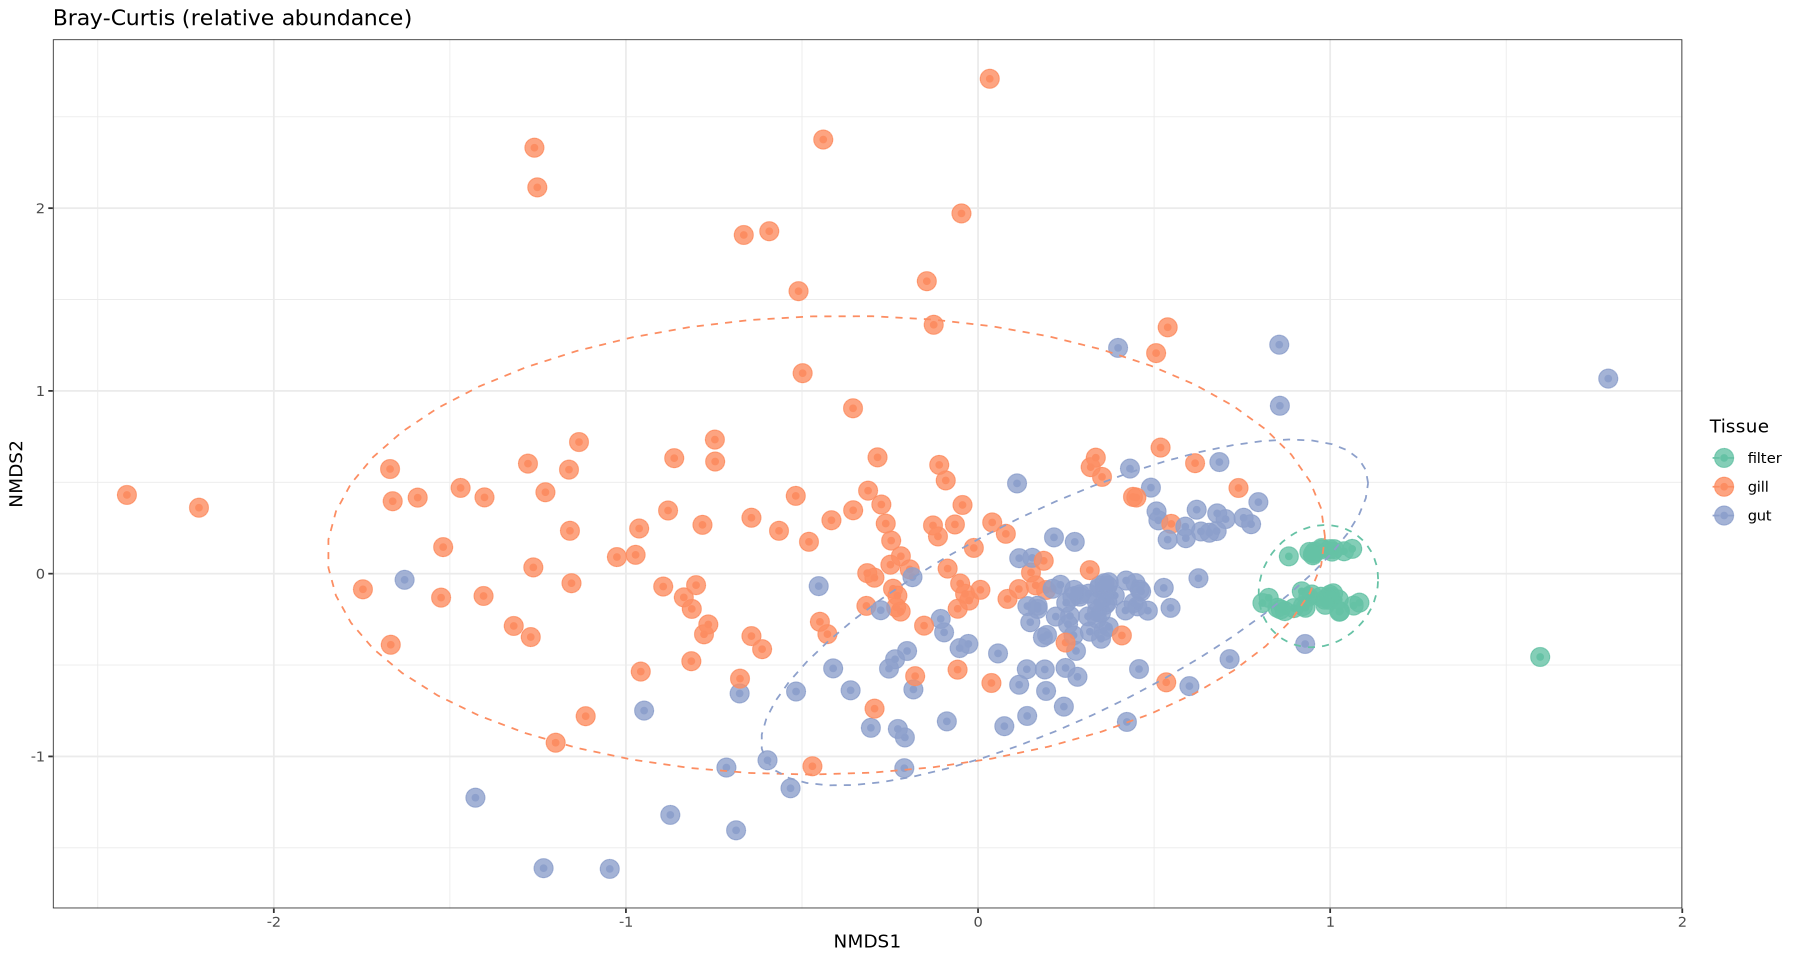

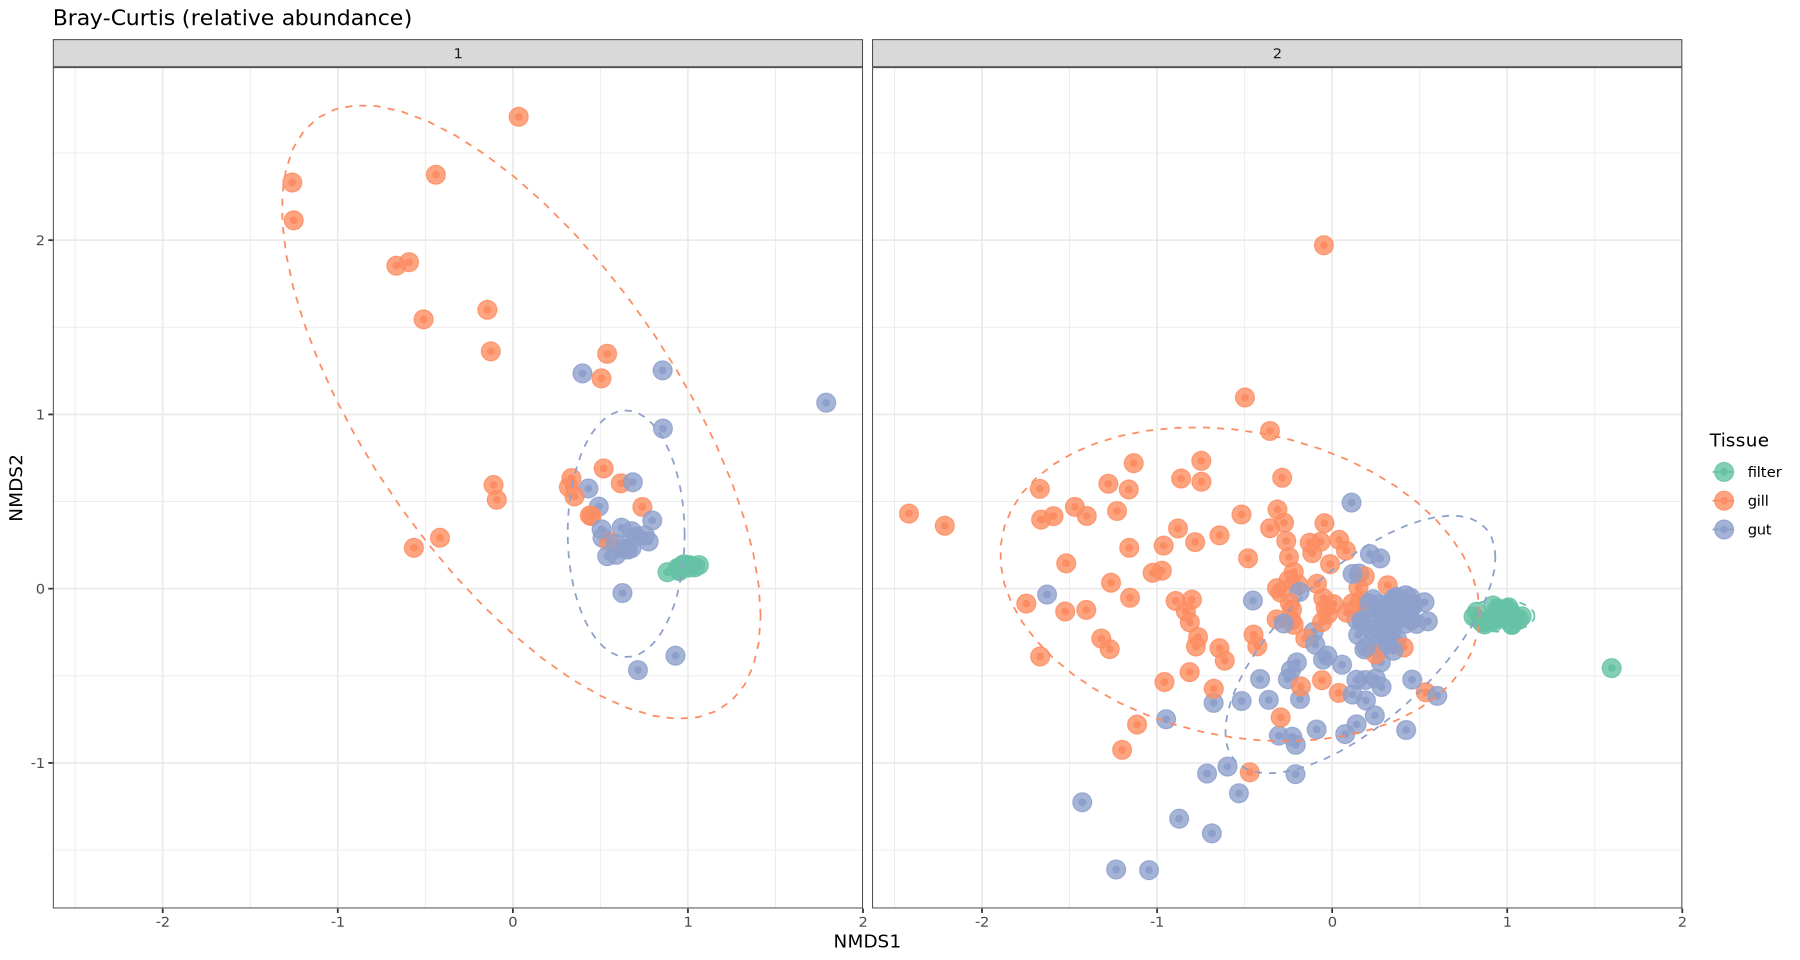

In [56]:
# Visualize nMDS
p_bray.nmds <- plot_ordination(ps, ord_bray.nmds, type = "samples", color = "Tissue") +
    geom_point(size = 5, alpha = 0.8) +
    scale_color_brewer(palette = "Set2") +
    labs(title = "Bray-Curtis (relative abundance)") +
    theme_bw() +
    stat_ellipse(aes(group = Tissue), level = 0.95, linetype = 2)

# Facet by phase
p_bray.nmds_phase <- plot_ordination(ps, ord_bray.nmds, type = "samples", color = "Tissue") +
    geom_point(size = 5, alpha = 0.8) +
    scale_color_brewer(palette = "Set2") +
    labs(title = "Bray-Curtis (relative abundance)") +
    facet_grid(. ~ Phase) +
    theme_bw() +
    stat_ellipse(aes(group = Tissue), level = 0.95, linetype = 2)

p_bray.nmds
p_bray.nmds_phase

Taking these results with a grain of salt given the stress value, the nMDS shows even more distinction between gill and gut microbial abundances. Still interested in how the "compositionally aware" CLR transformation would make these same data look. 

In [26]:
# Save phyloseq object
saveRDS(ps, "/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/ps-objects/ps-dada2-rel-samples.rds")

#### CLR transformation

Bray-Curtis measures the differences in proportional abundance which can be confounded by uneven sequencing depth. Centered log-ratio transformation accounts for this relativity by transforming the data to act like ordinary (Euclidean) numbers.

In [34]:
# Read in filtered but raw read count phyloseq object
ps_filt <- readRDS("/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/ps-objects/ps-dada2-filt.rds")

In [38]:
# Centered log-ratio transformation
ps_clr <- microbiome::transform(ps_filt, "clr")

# Inspect: CLR values are real numbers, positive and negative, centered around zero per sample
clr_values <- microbiome::abundances(ps_clr)
summary(as.vector(clr_values))

    Min.  1st Qu.   Median     Mean  3rd Qu.     Max. 
-0.12904 -0.04670 -0.02992  0.00000 -0.01940 14.46578 

In [43]:
# Add label to negative and positive controls in the tissue column
sample_data(ps_clr)$Tissue[grepl("negative", sample_names(ps_clr))] <- "Negative_control"
sample_data(ps_clr)$Tissue[grepl("Positive", sample_names(ps_clr))] <- "Positive_control"

# Remove negatives
ps_clr <- subset_samples(ps_clr, !Tissue %in% c("Negative_control", "Positive_control"))

# Remove taxa that are no longer present after subsetting
ps_clr <- prune_taxa(taxa_sums(ps_clr) > 0, ps_clr)
ps_clr

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 10606 taxa and 274 samples ]
sample_data() Sample Data:       [ 274 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 10606 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 10606 reference sequences ]

In [44]:
# CLR-transformed OTU matrix: samples x taxa
# microbiome::abundances() always returns taxa as rows; transpose for dist()
clr_matrix <- t(microbiome::abundances(ps_clr))
dist_aitchison <- dist(clr_matrix, method = "euclidean")

In [48]:
# Compute distance matrix
ord_aitch <- ordinate(ps_clr, method = "PCoA", distance = dist_aitchison)

# Variance explained by each axis
ord_aitch$values$Relative_eig[1:5] %>% round(3)

[1] 0.099 0.060 0.046 0.038 0.027

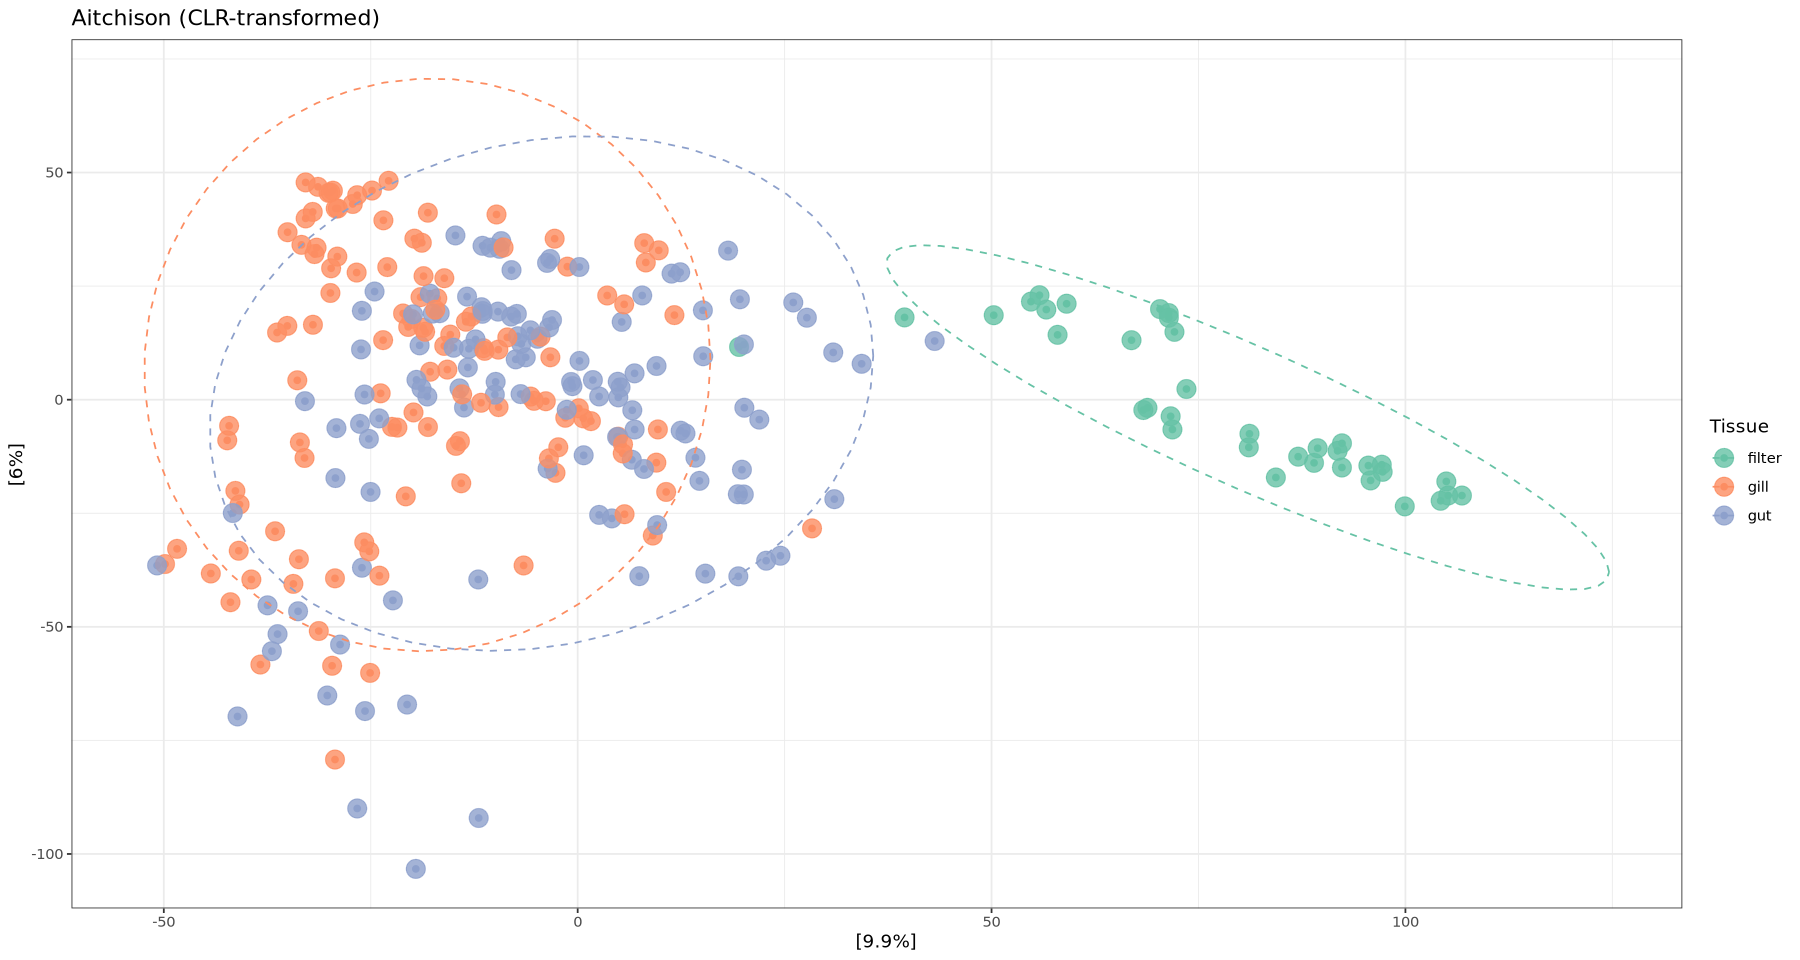

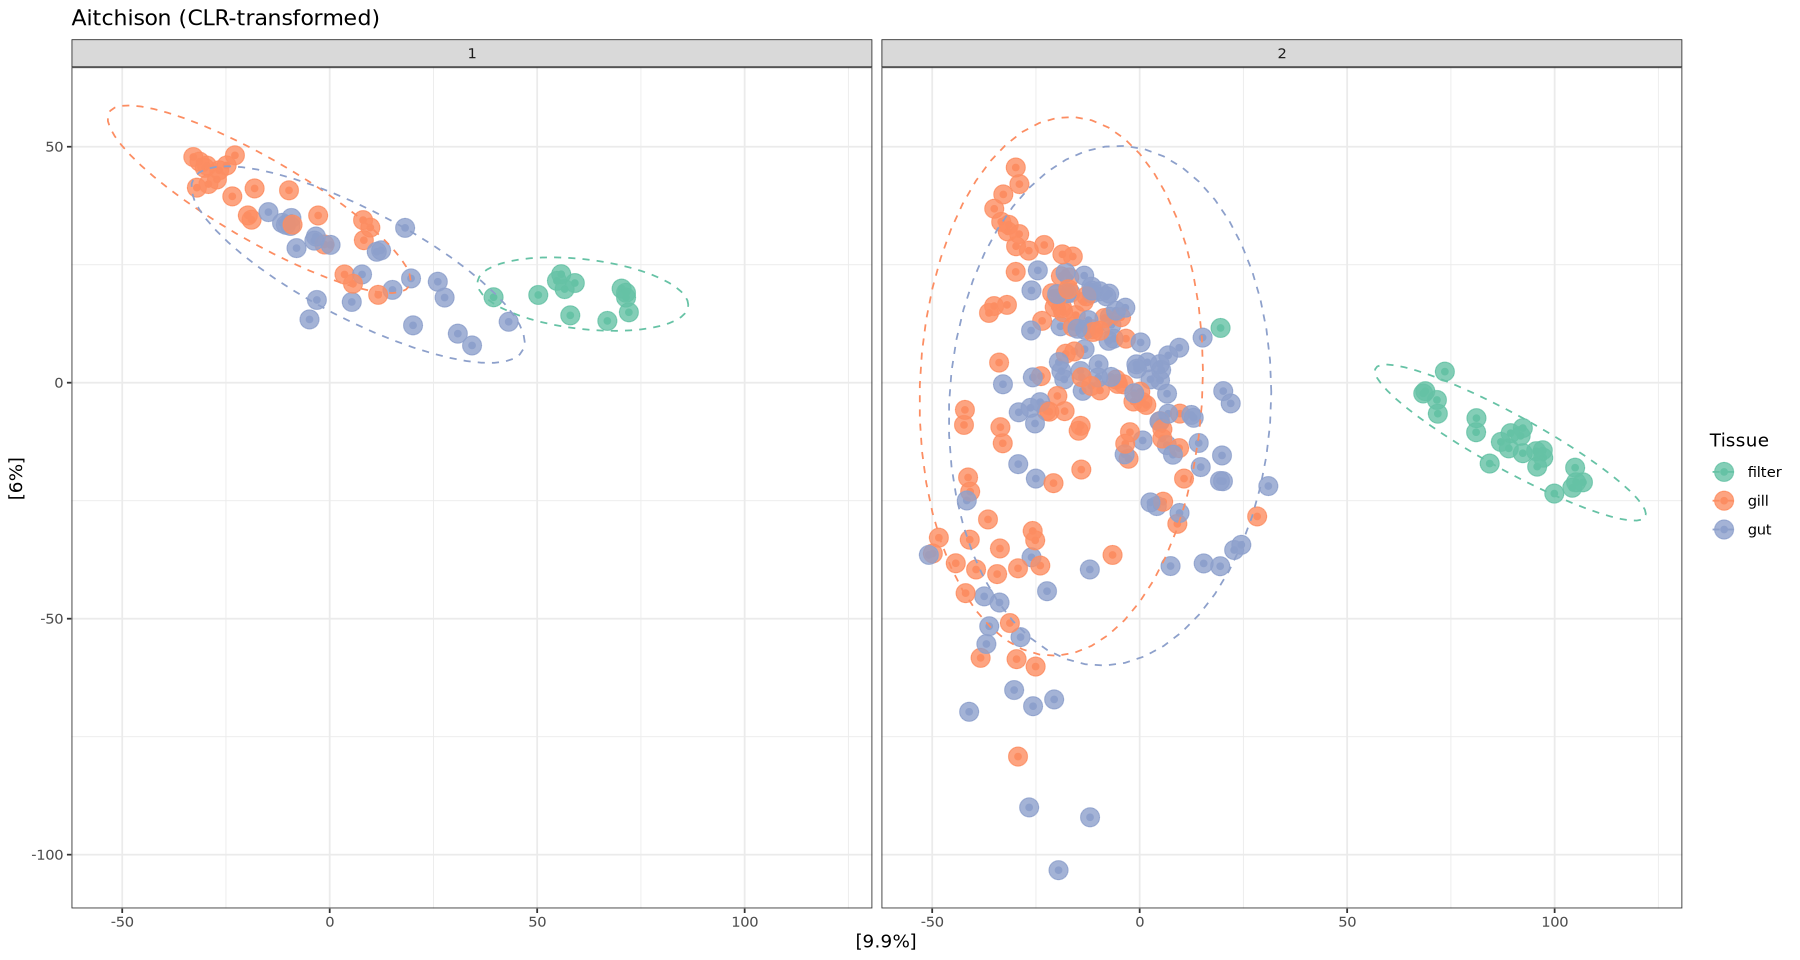

In [54]:
# Visualize PCoA
p_aitch <- plot_ordination(ps_clr, ord_aitch, color = "Tissue") +
    geom_point(size = 5, alpha = 0.8) +
    scale_color_brewer(palette = "Set2") +
    labs(title = "Aitchison (CLR-transformed)") +
    theme_bw()+
    stat_ellipse(aes(group = Tissue), level = 0.95, linetype = 2)

# Facet by phase
p_aitch_phase <- plot_ordination(ps_clr, ord_aitch, color = "Tissue") +
    geom_point(size = 5, alpha = 0.8) +
    scale_color_brewer(palette = "Set2") +
    labs(title = "Aitchison (CLR-transformed)") +
    facet_grid(. ~ Phase) +
    theme_bw()+
    stat_ellipse(aes(group = Tissue), level = 0.95, linetype = 2)

p_aitch
p_aitch_phase

Compositionally it looks like gill and gut largely overlap - need to think if I trust this transformation more given that the nMDS was unable to find a stable solution.

In [60]:
# Save phyloseq object
saveRDS(ps_clr, "/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/ps-objects/ps-dada2-clr-samples.rds")

### Bacteria only (no controls)

If interested in only bacteria, may be good to first subset taxa and then calculate relative abundances.

In [18]:
# Keep only bacteria
ps_bacteria <- subset_taxa(ps, Kingdom == "Bacteria")

# Remove taxa that were associated with the removed domains
ps_bacteria <- prune_taxa(taxa_sums(ps) > 0, ps)

# Compare phyloseq objects
ps
ps_bacteria

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 118935 taxa and 274 samples ]
sample_data() Sample Data:       [ 274 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 118935 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 118935 reference sequences ]

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 118935 taxa and 274 samples ]
sample_data() Sample Data:       [ 274 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 118935 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 118935 reference sequences ]

In [19]:
# Compute distance matrix
dist_bray <- phyloseq::distance(ps_bacteria, method = "bray")

In [20]:
# Ordinate using PCoA
ord_bray <- ordinate(ps_bacteria, method = "PCoA", distance = dist_bray)

# Variance explained by each axis
ord_bray$values$Relative_eig[1:5] %>% round(3)

[1] 0.149 0.097 0.065 0.050 0.038

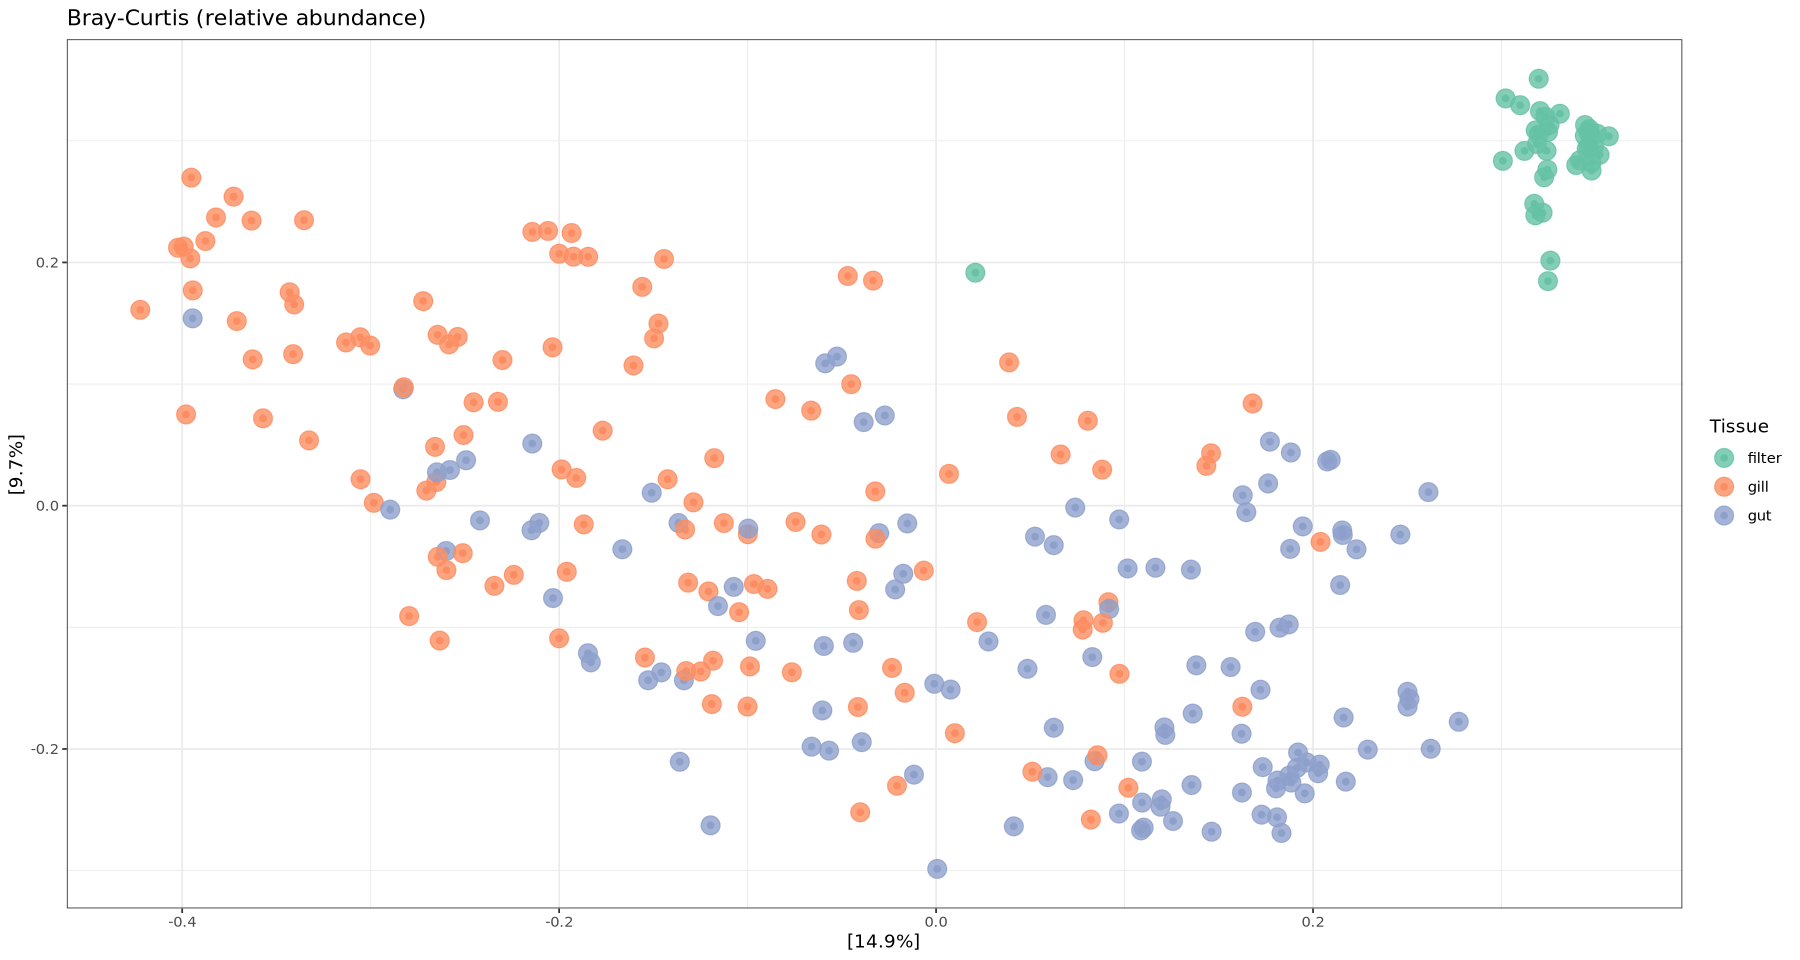

In [21]:
# Visualize PCoA
p_bray_bacteria <- plot_ordination(ps_bacteria, ord_bray, color = "Tissue") +
    geom_point(size = 5, alpha = 0.8) +
    scale_color_brewer(palette = "Set2") +
    labs(title = "Bray-Curtis (relative abundance)") +
    theme_bw()

p_bray_bacteria

Not a noticable difference in the amount of clustering when only including bacterial ASVs.

In [95]:
# Save phyloseq object
saveRDS(ps_bacteria, "/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/ps-objects/ps-dada2-rel-bacteria.rds")

## 11.4.26 | composition plots

In [1]:
# Load packages
suppressPackageStartupMessages({
    library(phyloseq)
    library(tidyverse)
    library(data.table)
    library(microbiome)
    library(Polychrome)
})
    
options(repr.plot.width=15, repr.plot.height=8)

In [27]:
# Read phyloseq object - relative abundance of just bacteria
ps_bacteria <- readRDS("/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/ps-objects/ps-dada2-rel-bacteria.rds")

### Class-level visualizations

In [3]:
# Aggregate ASVs to the class level
ps_class <- aggregate_taxa(ps_bacteria, level = "Class")
ps_class

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 151 taxa and 281 samples ]
sample_data() Sample Data:       [ 281 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 151 taxa by 4 taxonomic ranks ]

In [4]:
# Group less rare classes as 'other'
ps_class_top <- aggregate_rare(ps_class,level = "Class",
  detection = 0.01,   # >1% relative abundance
  prevalence = 0.10   # in at least 10% of samples
)

ntaxa(ps_class_top)
taxa_names(ps_class_top)

[1] 22

[1] "Acidimicrobiia"      "Actinobacteria"      "Alphaproteobacteria"
 [4] "Anaerolineae"        "Bacilli"             "Bacteroidia"        
 [7] "Campylobacteria"     "Clostridia"          "Cyanobacteriia"     
[10] "Desulfobacteria"     "Desulfobulbia"       "Fusobacteriia"      
[13] "Gammaproteobacteria" "Nitrospiria"         "OM190"              
[16] "Omnitrophia"         "Other"               "Phycisphaerae"      
[19] "Planctomycetes"      "Spirochaetia"        "Thermoleophilia"    
[22] "Verrucomicrobiia"

In [5]:
# Create data frame from phyloseq object
class_df <- psmelt(ps_class_top)
head(class_df)

,OTU,Sample,Abundance,Year,Combined_treat,Phase_1_treat,Phase_1_rep,Phase_2_treat,Phase_2_rep,Tag,⋯,Index_date,Index_volume,Clean_date,Clean_date_2,Gel_extraction,Final_concentration,X25ng,Notes,Class,unique
,<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>,<int>,<chr>,<int>,<chr>,⋯,<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>
3378,Gammaproteobacteria,2024_Warm03_Null_G21_gut,0.8713915,2024,WNA,Warm,3,NA,NA,G21,⋯,2026-06-26,2,6/30/26,7/1/26,NA,4.48,5.58,,Gammaproteobacteria,Gammaproteobacteria
3239,Fusobacteriia,2024_Warm01_Null_G02_gill,0.8255290,2024,WNA,Warm,1,NA,NA,G02,⋯,2026-07-06,1,7/6/26,NA,7/7/26,2.66,9.40,,Fusobacteriia,Fusobacteriia
4467,Omnitrophia,2024_Hyp05_Both03_B34_gill,0.7687334,2024,HB,Hyp,5,Both,3,B34,⋯,2026-07-06,1,7/6/26,NA,7/7/26,4.02,6.22,,Omnitrophia,Omnitrophia
3402,Gammaproteobacteria,2024_Cont03_Null_W21_gut,0.7453591,2024,CNA,Cont,3,NA,NA,W21,⋯,2026-06-26,2,6/30/26,7/1/26,NA,4.20,5.95,,Gammaproteobacteria,Gammaproteobacteria
4319,Omnitrophia,2024_Hyp01_Both06_B61_gill,0.7303138,2024,HB,Hyp,1,Both,6,B61,⋯,2026-07-31,2,8/4/26,NA,NA,1.36,18.38,,Omnitrophia,Omnitrophia
4437,Omnitrophia,2024_Hyp02_Warm02_B16_gill,0.7192946,2024,HW,Hyp,2,Warm,2,B16,⋯,2026-07-31,2,8/4/26,NA,NA,1.34,18.66,,Omnitrophia,Omnitrophia


In [6]:
# Order class so that "Other" will sit at the bottom of each bar in the plot
class_levels <- c("Other", setdiff(unique(class_df$OTU), "Other"))
class_df <- class_df %>%
  mutate(OTU = factor(OTU, levels = class_levels)) 

In [7]:
# Set up color palette
colors <- rev(kelly.colors(n = 22))
names(colors) <- levels(class_df$OTU)
colors["Other"] <- "grey70"
options(repr.plot.width=20, repr.plot.height=8)

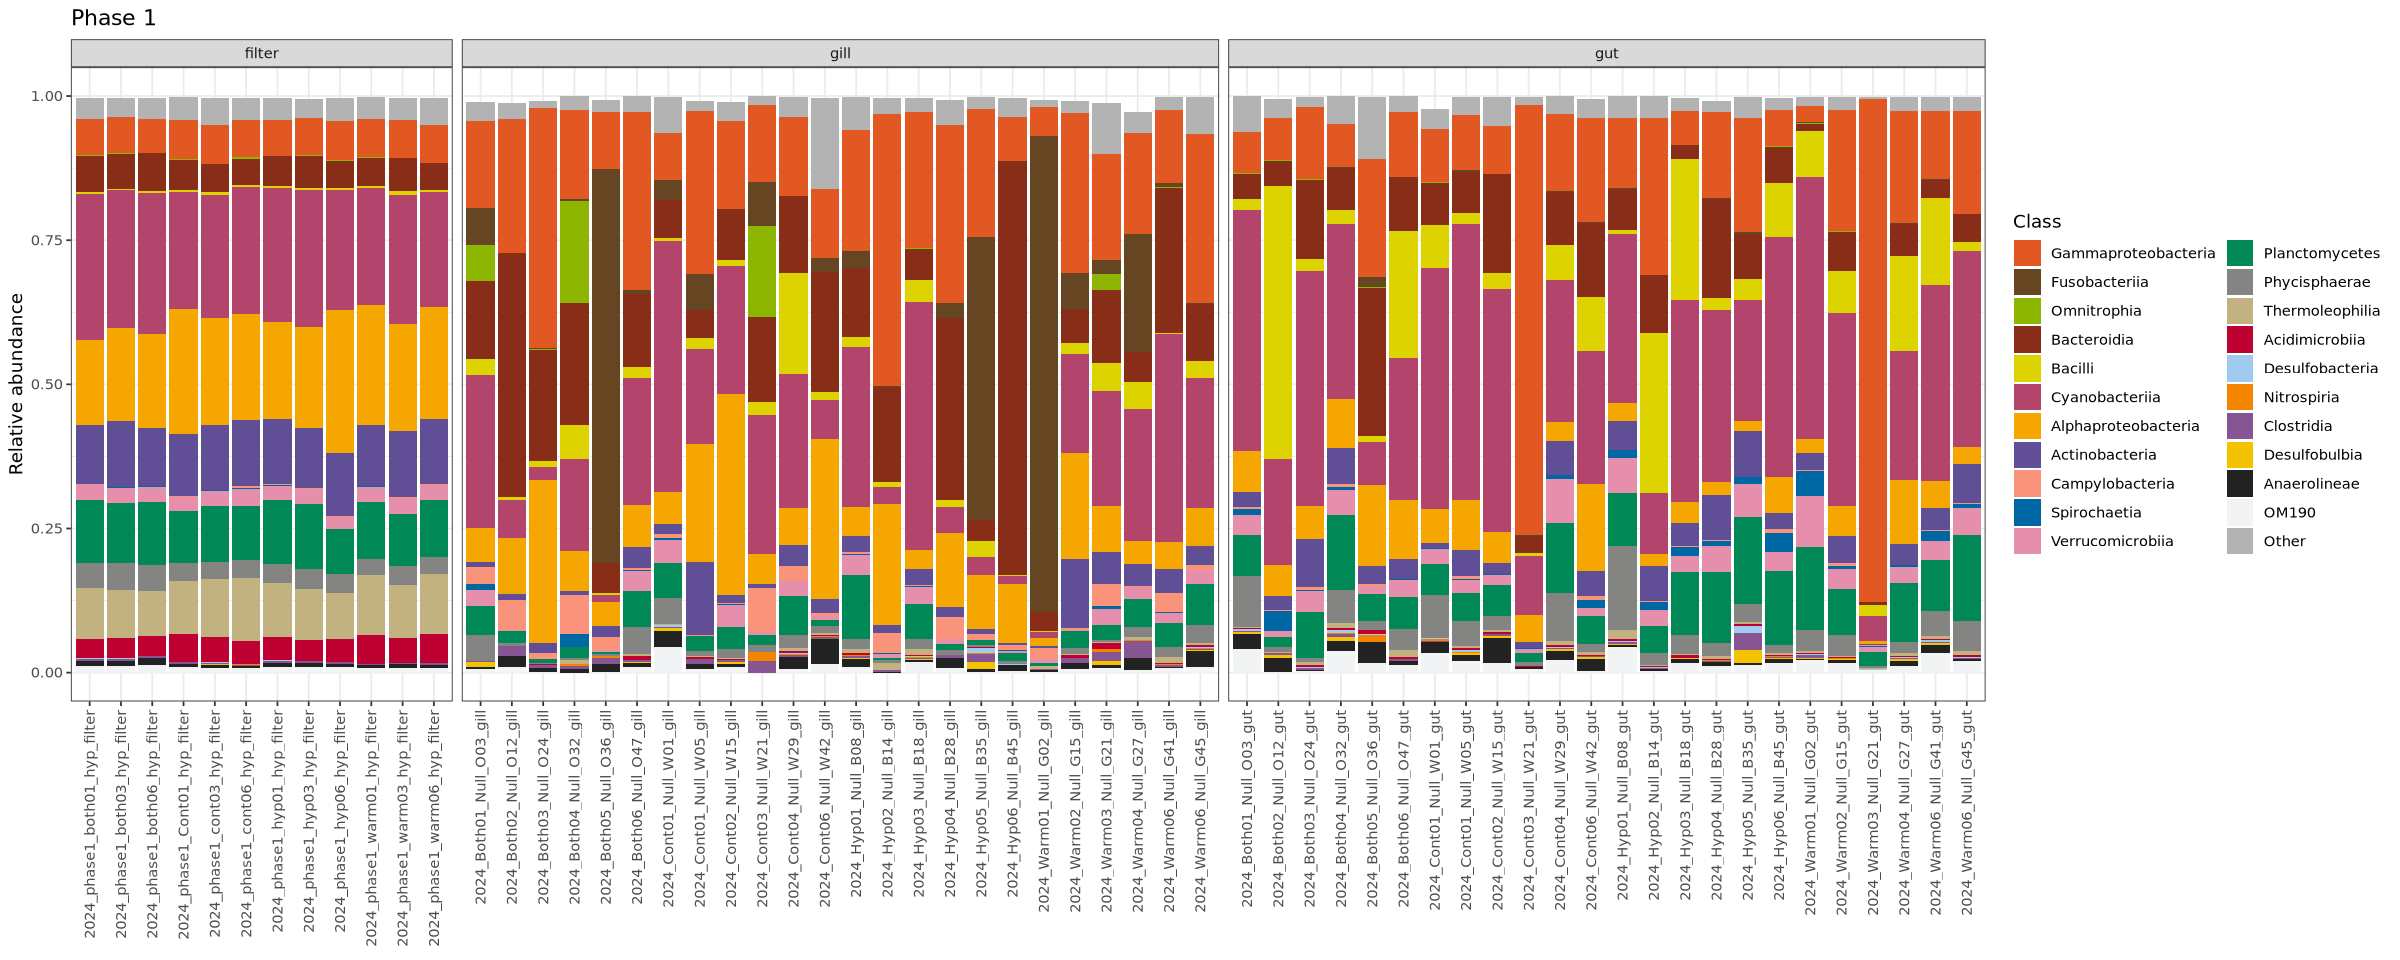

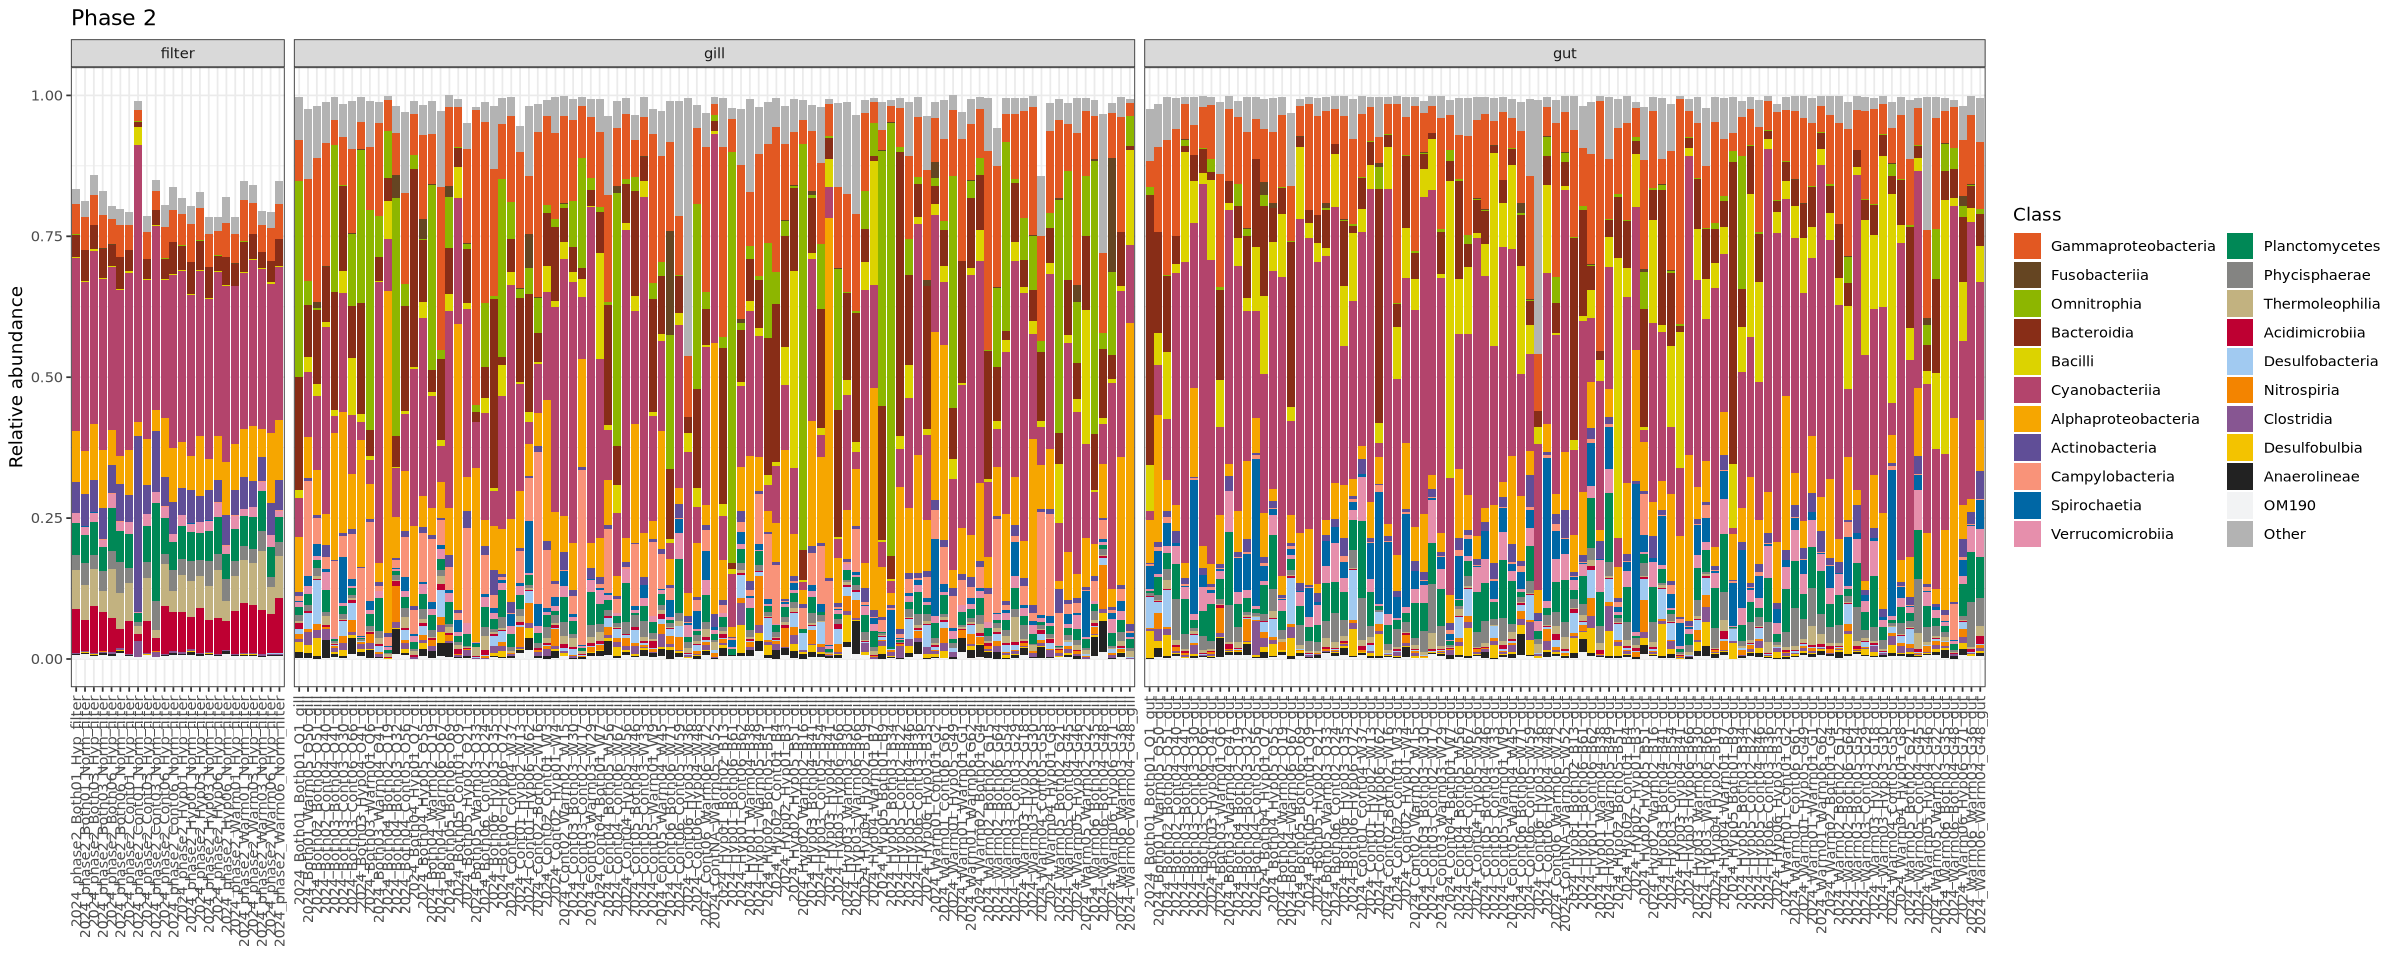

In [8]:
# Plot phase 1 samples bar plot
p_comp_p1 <- class_df %>% filter(Phase == 1) %>% 
  ggplot(aes(x = Sample, y = Abundance, fill = OTU)) +
  geom_col() +
  scale_fill_manual(values = colors, breaks = c(setdiff(levels(class_df$OTU), "Other"), "Other")) +
  labs(x = NULL, y = "Relative abundance", fill = "Class", title="Phase 1") +
  facet_grid(. ~ Tissue, scales = "free_x", space = "free_x") +
  theme_bw() +
  theme(axis.text.x = element_text(angle = 90, hjust = 1, vjust = 0.5), legend.position = "right")  

# Plot phase 2 samples bar plot
p_comp_p2 <- class_df %>% filter(Phase == 2) %>% 
  ggplot(aes(x = Sample, y = Abundance, fill = OTU)) +
  geom_col() +
  scale_fill_manual(values = colors, breaks = c(setdiff(levels(class_df$OTU), "Other"), "Other")) +
  facet_grid(. ~ Tissue, scales = "free_x", space = "free_x") +
  labs(x = NULL, y = "Relative abundance", fill = "Class", title="Phase 2") +
  theme_bw() +
  theme(axis.text.x = element_text(angle = 90, hjust = 1, vjust = 0.5), legend.position = "right")

p_comp_p1
p_comp_p2

Relative abundances don't sum to 1 since there was filtering I performed after calculating relative abundance (ps_rel -> ps_bacteria). Other observations:
- Filters are all pretty similar to each other, with apparently larger percentages of non-bacteria taxa (i.e. archaea)
- More spirochaetia in gut, also relatively more cyanobacteria in gut which is abundant in the filters (especially in phase 2)

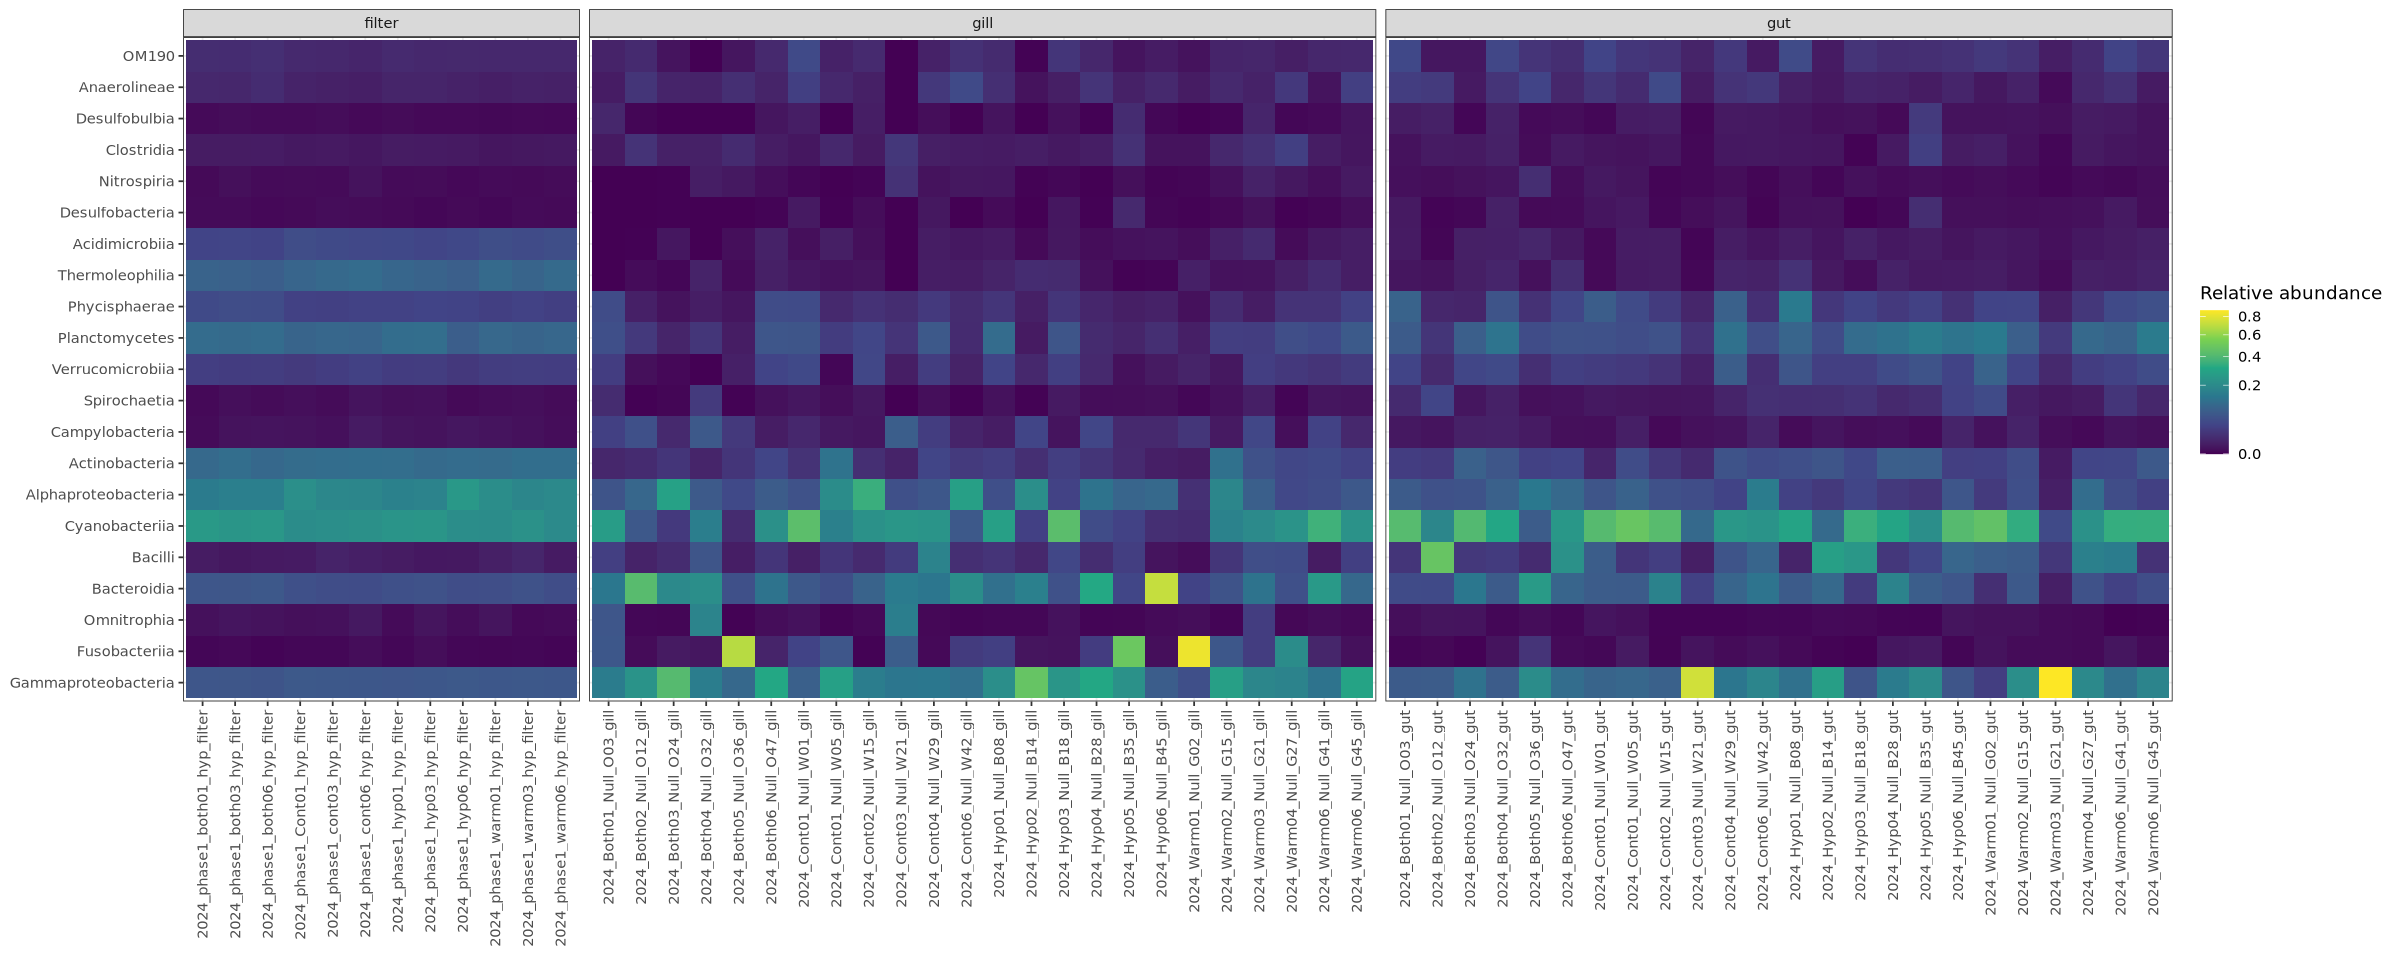

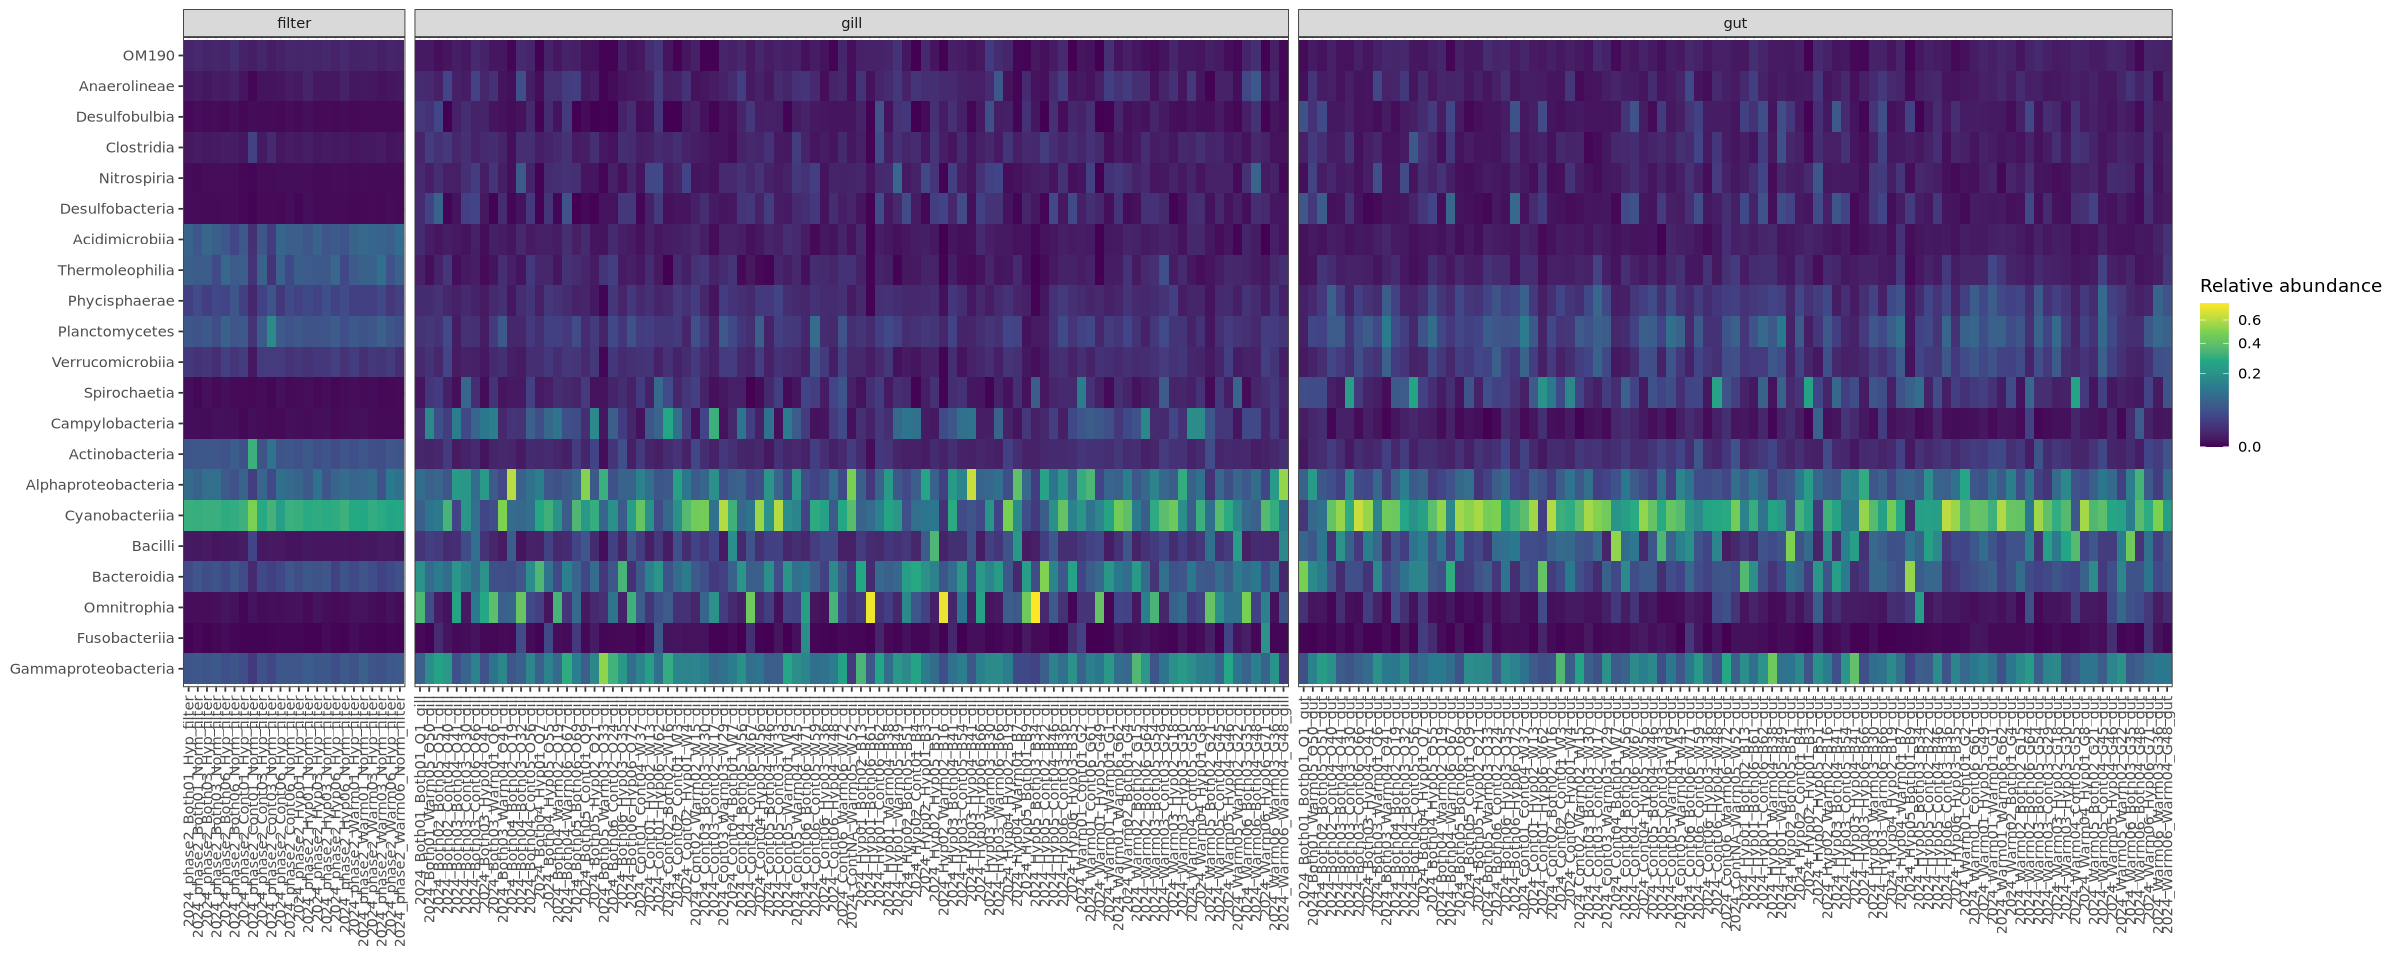

In [9]:
# Plot phase 1 samples heat map
p_heat_p1 <- class_df %>% filter(Phase == 1 & OTU != "Other") %>% 
  ggplot(aes(x = Sample, y = OTU, fill = Abundance)) +
  geom_tile() +
  facet_grid(~ Tissue, scales = "free_x", space = "free_x") +
  scale_fill_viridis_c(trans = "sqrt", name = "Relative abundance") +
  labs(x = NULL, y = NULL) +
  theme_bw() +
  theme(axis.text.x = element_text(angle = 90, hjust = 1, vjust = 0.5))

# Plot phase 2 samples heat map
p_heat_p2 <- class_df %>% filter(Phase == 2 & OTU != "Other") %>% 
  ggplot(aes(x = Sample, y = OTU, fill = Abundance)) +
  geom_tile() +
  facet_grid(~ Tissue, scales = "free_x", space = "free_x") +
  scale_fill_viridis_c(trans = "sqrt", name = "Relative abundance") +
  labs(x = NULL, y = NULL) +
  theme_bw() +
  theme(axis.text.x = element_text(angle = 90, hjust = 1, vjust = 0.5))

p_heat_p1
p_heat_p2

Interesting to see broad class-level abundance patterns carry over from phase 1 to phase 2, but defintely some differences too:
- Gills increase in camplyobacteria and omnitrophia
- Gills decrease in fusobacteria
- Gut increase in spirochaetia

### Order-level visualizations

In [10]:
# Aggregate ASVs to the order level
ps_order <- aggregate_taxa(ps_bacteria, level = "Order")
ps_order

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 366 taxa and 281 samples ]
sample_data() Sample Data:       [ 281 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 366 taxa by 5 taxonomic ranks ]

In [11]:
# Group less rare orders as "other"
ps_order_top <- aggregate_rare(ps_order,level = "Order",
  detection = 0.01,   # >1% relative abundance
  prevalence = 0.10   # in at least 10% of samples
)

ntaxa(ps_order_top)
taxa_names(ps_order_top)

[1] 33

[1] "Ardenticatenales"    "Bacteroidales"       "Burkholderiales"    
 [4] "Campylobacterales"   "Chitinophagales"     "Chloroplast"        
 [7] "Chthoniobacterales"  "Cytophagales"        "Desulfobacterales"  
[10] "Desulfobulbales"     "Enterobacterales"    "Flavobacteriales"   
[13] "Fusobacteriales"     "Hyphomicrobiales"    "Isosphaerales"      
[16] "Kordiimonadales"     "Micrococcales"       "Microtrichales"     
[19] "Mycobacteriales"     "Mycoplasmatales"     "Nitrospirales"      
[22] "Other"               "Pelagibacterales"    "PeM15"              
[25] "Phycisphaerales"     "Pirellulales"        "Pseudomonadales"    
[28] "Rhodobacterales"     "Solirubrobacterales" "Sphingomonadales"   
[31] "Spirochaetales"      "Synechococcales"     "Unknown"

In [12]:
# Create data frame from phyloseq object
order_df <- psmelt(ps_order_top)
head(order_df)

,OTU,Sample,Abundance,Year,Combined_treat,Phase_1_treat,Phase_1_rep,Phase_2_treat,Phase_2_rep,Tag,⋯,Index_date,Index_volume,Clean_date,Clean_date_2,Gel_extraction,Final_concentration,X25ng,Notes,Order,unique
,<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>,<int>,<chr>,<int>,<chr>,⋯,<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>
2953,Enterobacterales,2024_Warm03_Null_G21_gut,0.8679170,2024,WNA,Warm,3,NA,NA,G21,⋯,2026-06-26,2,6/30/26,7/1/26,NA,4.48,5.58,,Enterobacterales,Enterobacterales
3385,Fusobacteriales,2024_Warm01_Null_G02_gill,0.8255290,2024,WNA,Warm,1,NA,NA,G02,⋯,2026-07-06,1,7/6/26,NA,7/7/26,2.66,9.40,,Fusobacteriales,Fusobacteriales
9154,Unknown,2024_Hyp05_Both03_B34_gill,0.8068940,2024,HB,Hyp,5,Both,3,B34,⋯,2026-07-06,1,7/6/26,NA,7/7/26,4.02,6.22,,Unknown,Unknown
9159,Unknown,2024_Hyp01_Both06_B61_gill,0.7428309,2024,HB,Hyp,1,Both,6,B61,⋯,2026-07-31,2,8/4/26,NA,NA,1.36,18.38,,Unknown,Unknown
9091,Unknown,2024_Hyp02_Warm02_B16_gill,0.7336638,2024,HW,Hyp,2,Warm,2,B16,⋯,2026-07-31,2,8/4/26,NA,NA,1.34,18.66,,Unknown,Unknown
9270,Unknown,2024_Both04_Both02_O19_gill,0.6912435,2024,BB,Both,4,Both,2,O19,⋯,2026-07-03,2,7/3/26,NA,NA,14.70,1.70,,Unknown,Unknown


In [13]:
# Order order so that "Other" will sit at the bottom of each bar in the plot
order_levels <- c("Other", setdiff(unique(order_df$OTU), "Other"))
order_df <- order_df %>%
  mutate(OTU = factor(OTU, levels = order_levels)) 

In [14]:
# Set up color palette
colors <- rev(palette36.colors(n = 36))
names(colors) <- levels(order_df$OTU)
colors["Other"] <- "grey70"
options(repr.plot.width=20, repr.plot.height=8)

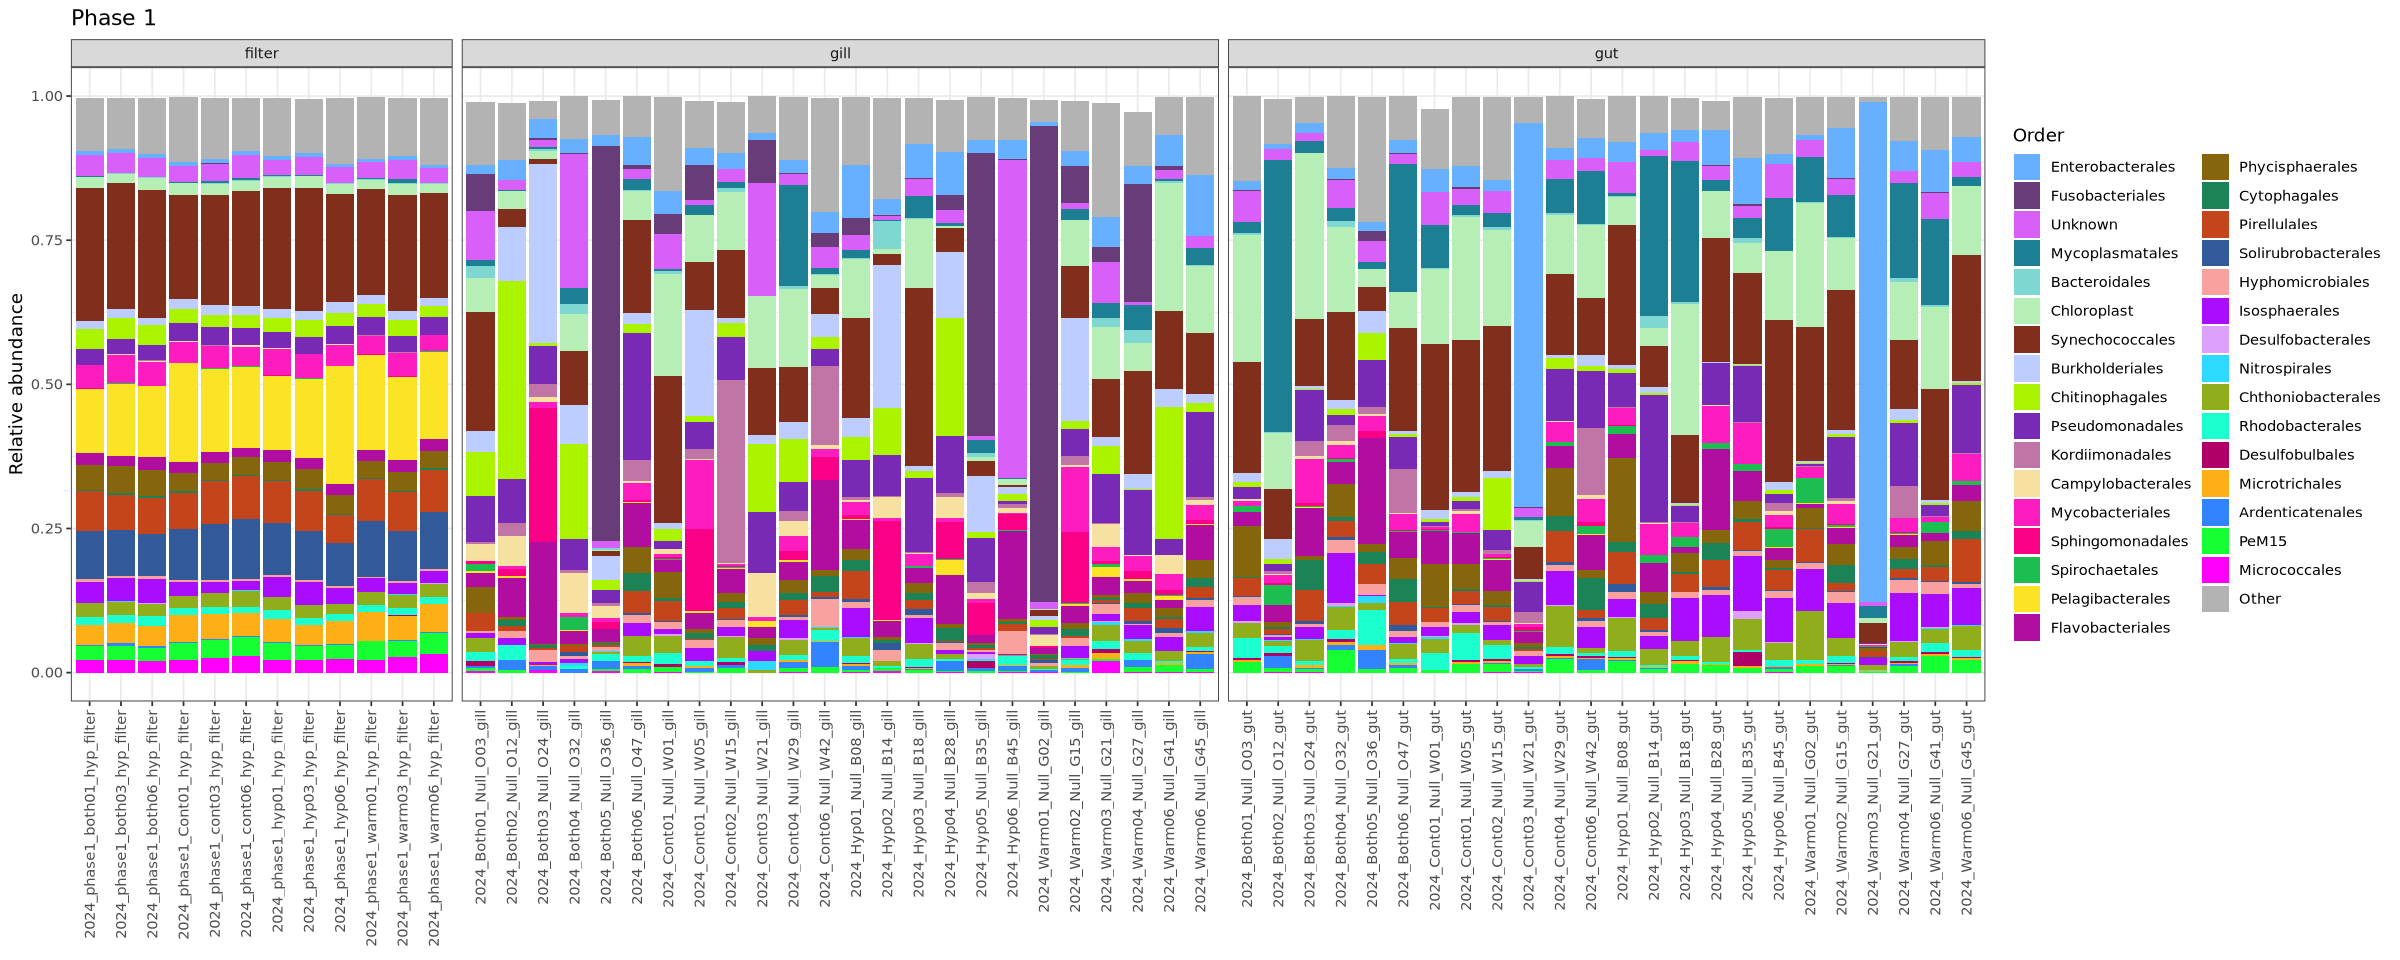

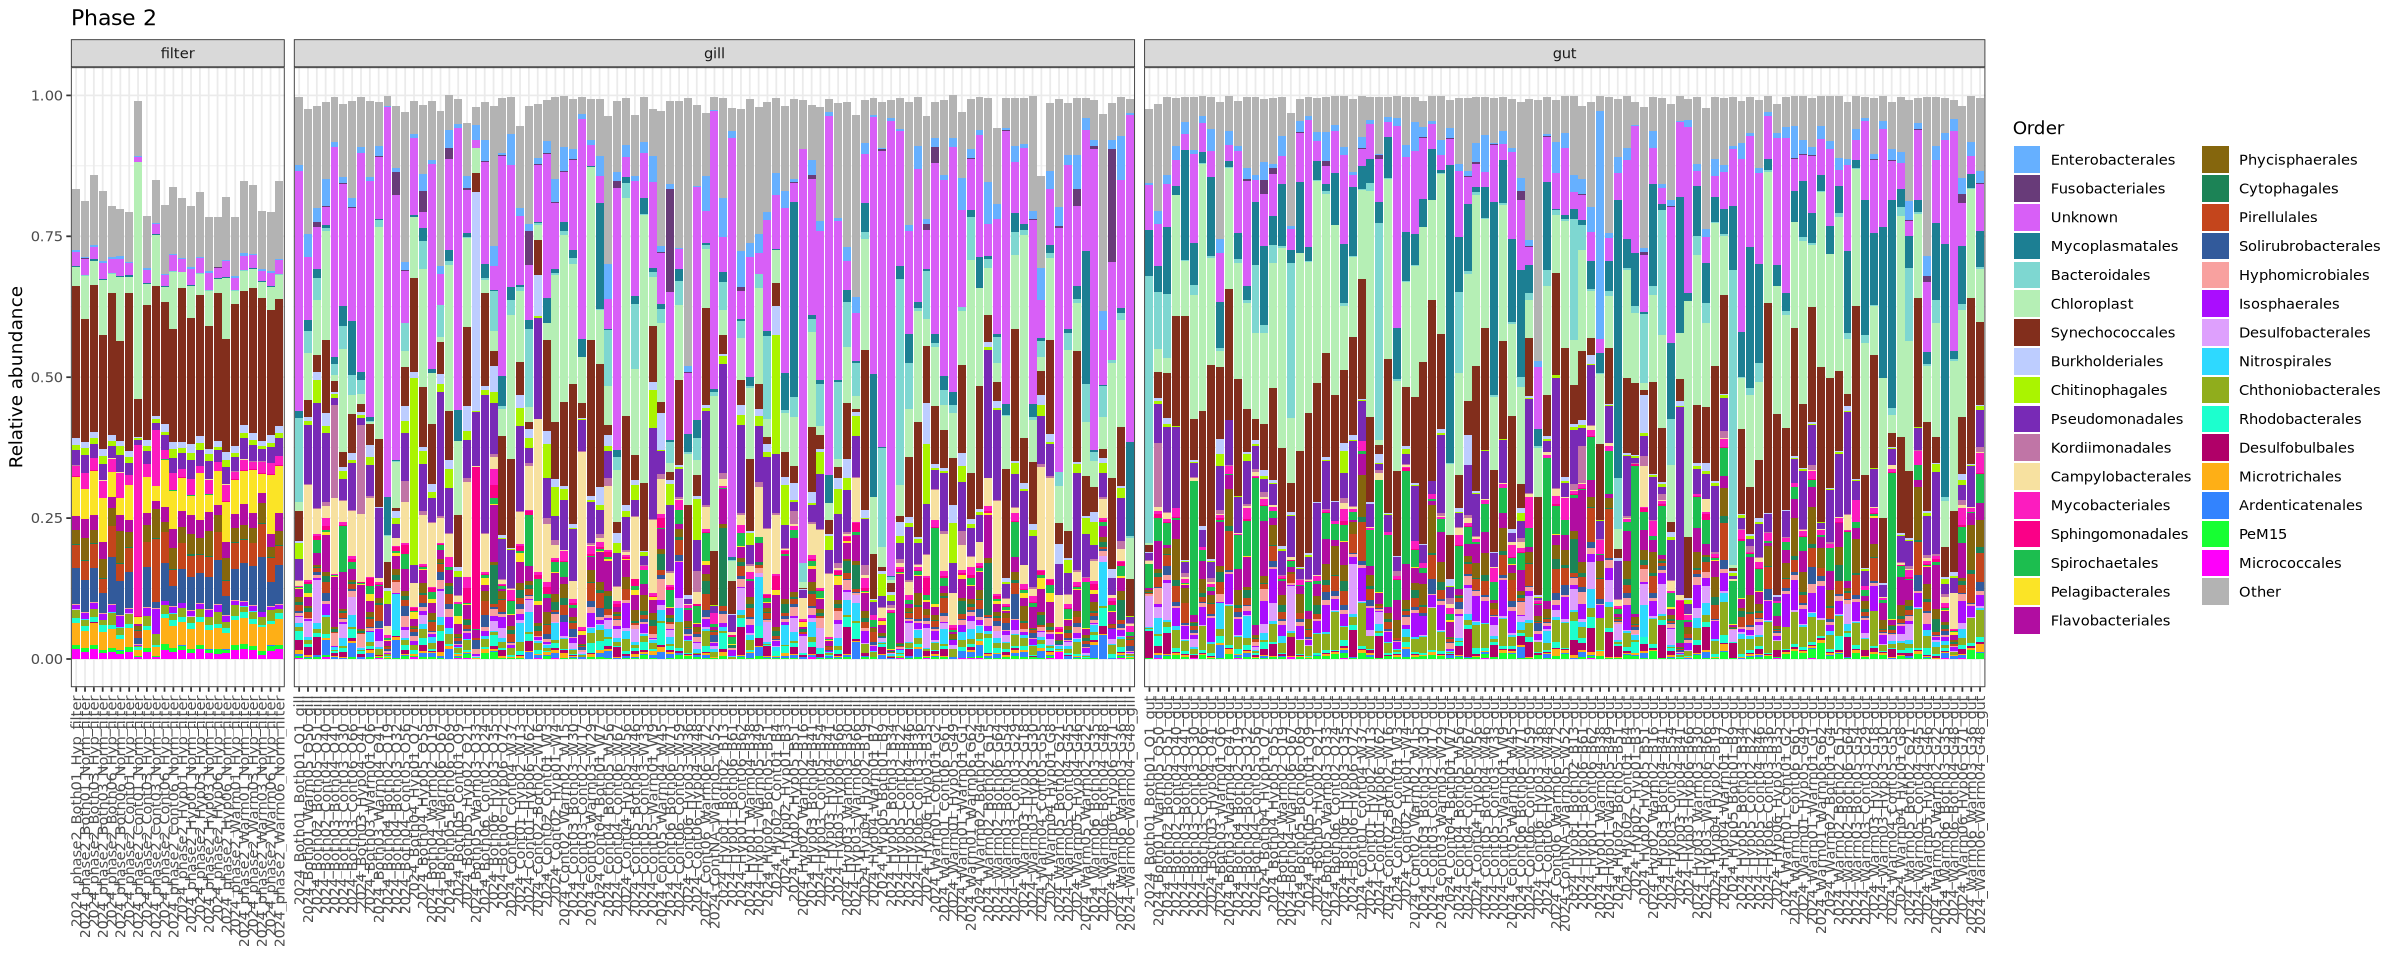

In [15]:
# Plot phase 1 samples bar plot
p_comp_p1 <- order_df %>% filter(Phase == 1) %>% 
  ggplot(aes(x = Sample, y = Abundance, fill = OTU)) +
  geom_col() +
  scale_fill_manual(values = colors, breaks = c(setdiff(levels(order_df$OTU), "Other"), "Other")) +
  labs(x = NULL, y = "Relative abundance", fill = "Order", title="Phase 1") +
  facet_grid(. ~ Tissue, scales = "free_x", space = "free_x") +
  theme_bw() +
  theme(axis.text.x = element_text(angle = 90, hjust = 1, vjust = 0.5), legend.position = "right")

# Plot phase 2 samples bar plot
p_comp_p2 <- order_df %>% filter(Phase == 2) %>% 
  ggplot(aes(x = Sample, y = Abundance, fill = OTU)) +
  geom_col() +
  scale_fill_manual(values = colors, breaks = c(setdiff(levels(order_df$OTU), "Other"), "Other")) +
  labs(x = NULL, y = "Relative abundance", fill = "Order", title="Phase 2") +
  facet_grid(. ~ Tissue, scales = "free_x", space = "free_x") +
  theme_bw() +
  theme(axis.text.x = element_text(angle = 90, hjust = 1, vjust = 0.5), legend.position = "right")

p_comp_p1
p_comp_p2

Unknown samples are those that could not be identified down to the order level. Very busy, not the most informative, but some rough observations:
- Filters are all still very similar in composition
- More chloroplast in gut compared to gill, and more than what was captured on the filter

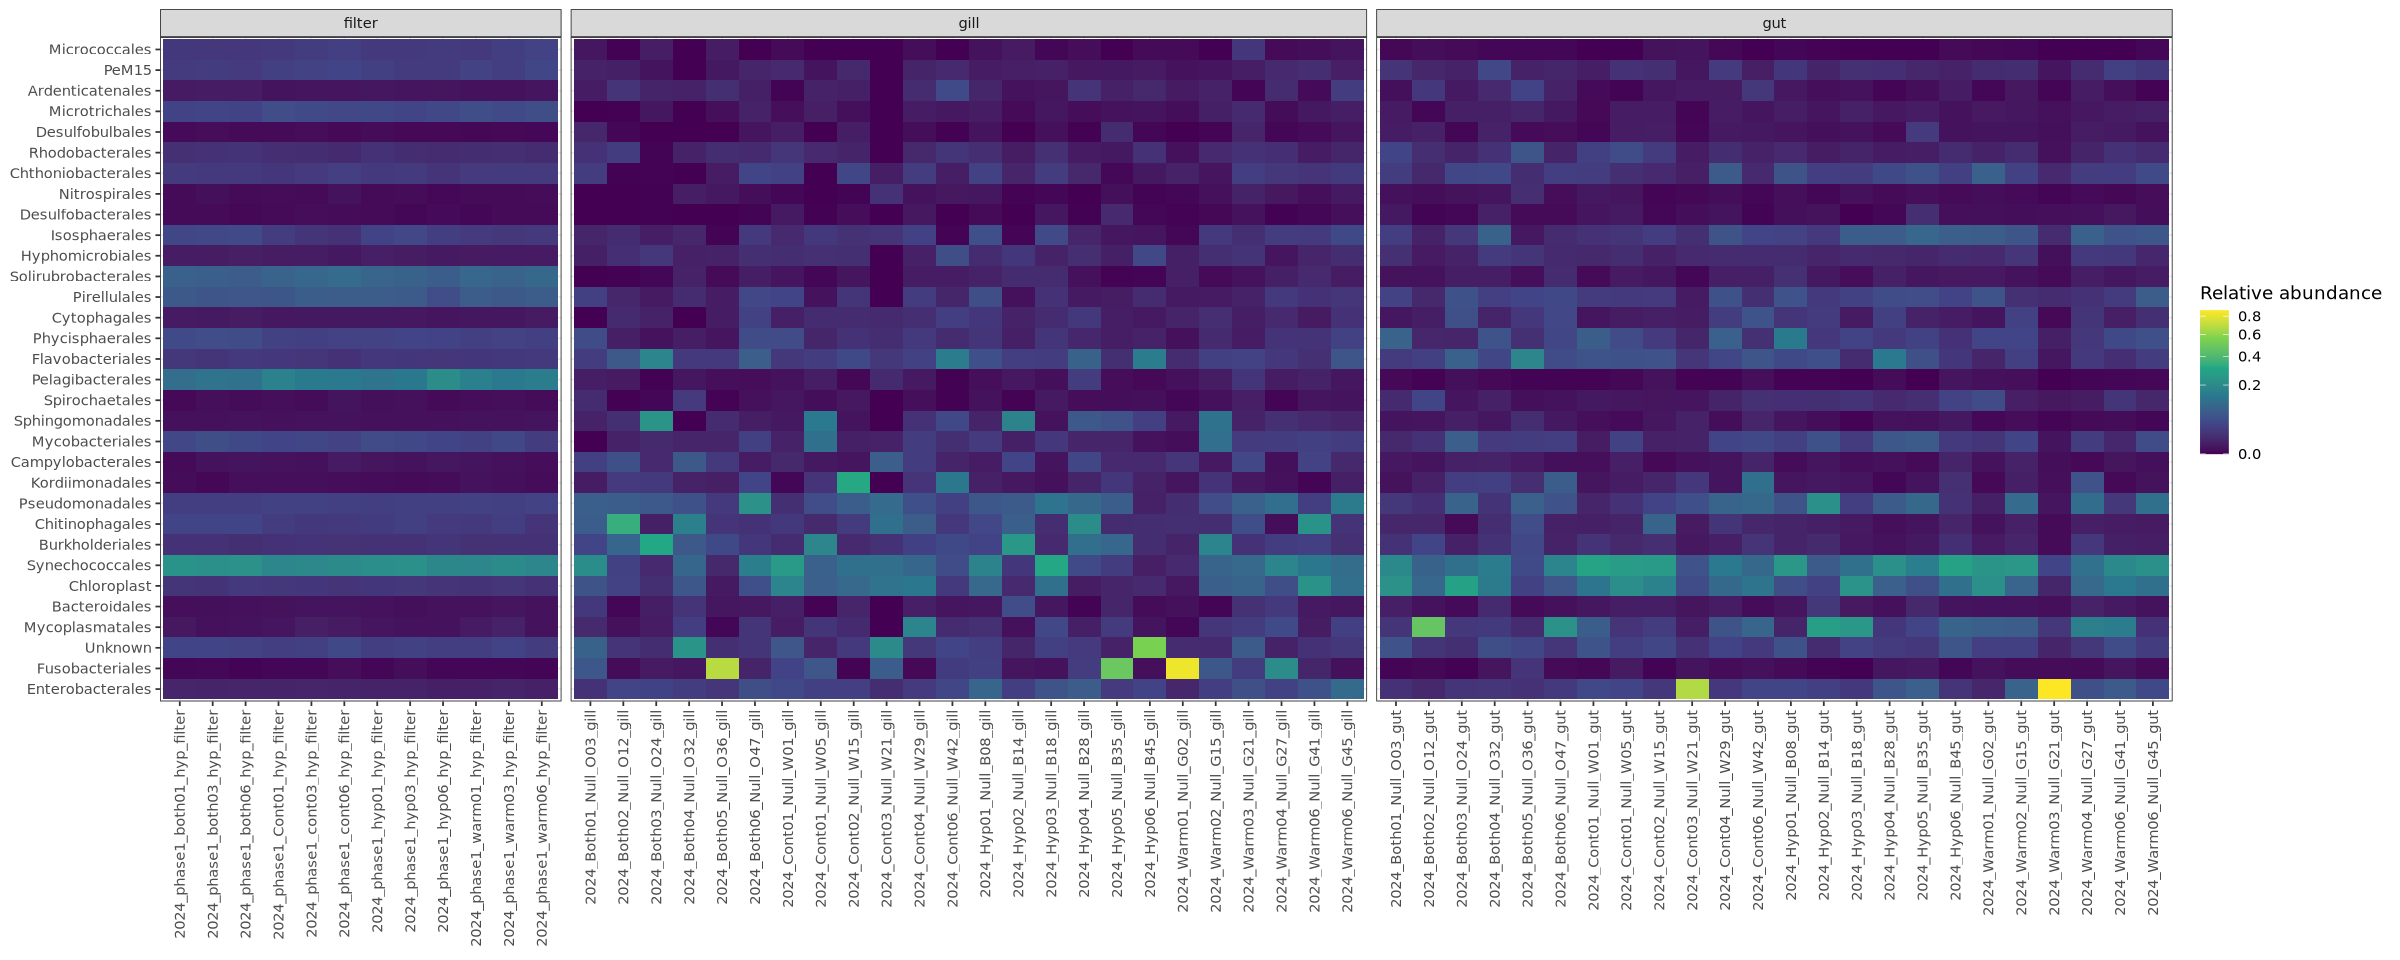

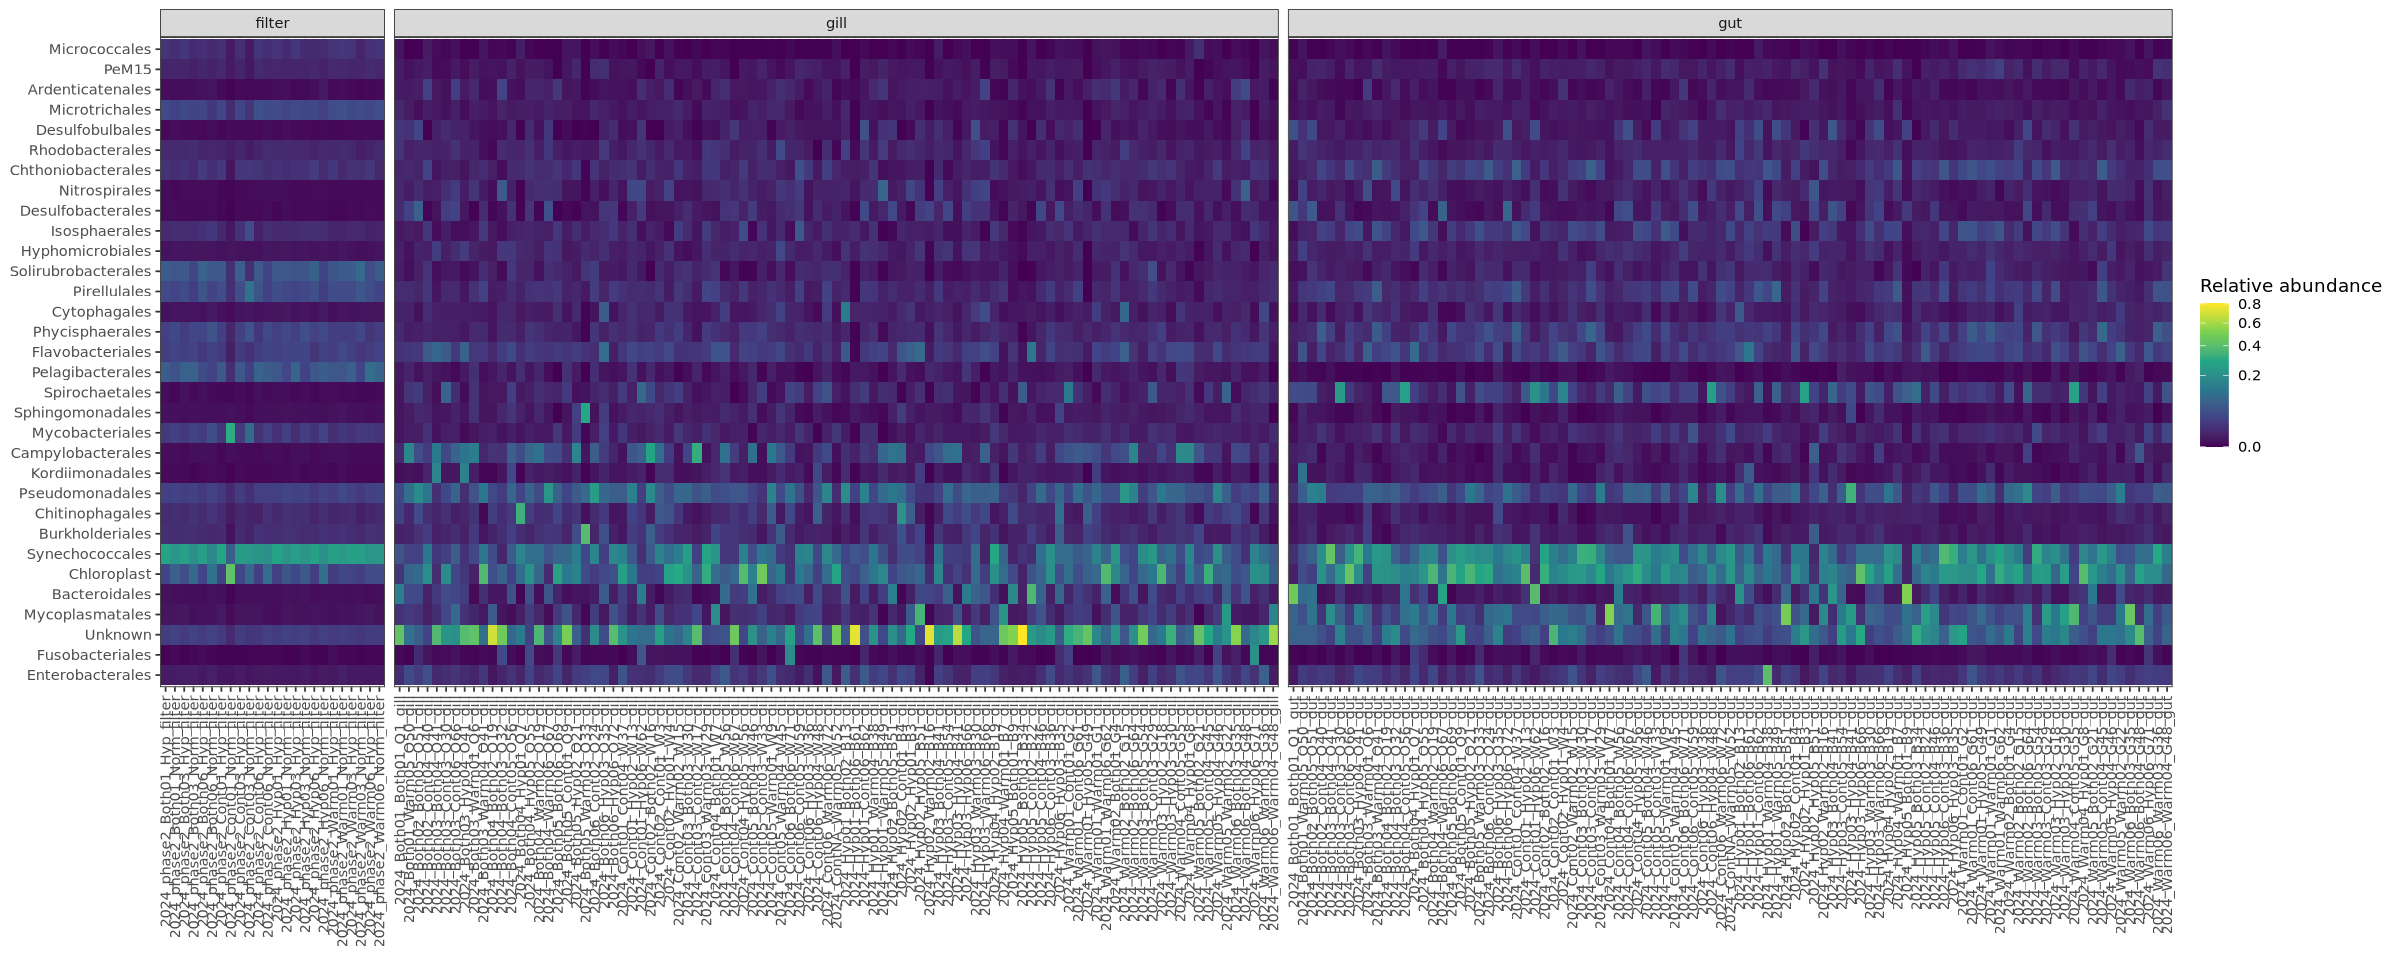

In [16]:
# Plot phase 1 samples heat map
p_heat_p1 <- order_df %>% filter(Phase == 1 & OTU != "Other") %>% 
  ggplot(aes(x = Sample, y = OTU, fill = Abundance)) +
  geom_tile() +
  facet_grid(~ Tissue, scales = "free_x", space = "free_x") +
  scale_fill_viridis_c(trans = "sqrt", name = "Relative abundance") +
  labs(x = NULL, y = NULL) +
  theme_bw() +
  theme(axis.text.x = element_text(angle = 90, hjust = 1, vjust = 0.5))

# Plot phase 2 samples heat map
p_heat_p2 <- order_df %>% filter(Phase == 2 & OTU != "Other") %>% 
  ggplot(aes(x = Sample, y = OTU, fill = Abundance)) +
  geom_tile() +
  facet_grid(~ Tissue, scales = "free_x", space = "free_x") +
  scale_fill_viridis_c(trans = "sqrt", name = "Relative abundance") +
  labs(x = NULL, y = NULL) +
  theme_bw() +
  theme(axis.text.x = element_text(angle = 90, hjust = 1, vjust = 0.5))

p_heat_p1
p_heat_p2

- Lots of "unknown" esspecially in the gill samples
- Pelagilbacterales relatively more abundant in filter but notably not present in gut
- See mycoplasmatales in gut and not filter, similar to Pimentel et al findings

### Family-level visualizations

In [17]:
# Aggregate ASVs to the order level
ps_family <- aggregate_taxa(ps_bacteria, level = "Family")
ps_family

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 538 taxa and 281 samples ]
sample_data() Sample Data:       [ 281 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 538 taxa by 6 taxonomic ranks ]

In [18]:
# Group less rare orders as "other"
ps_family_top <- aggregate_rare(ps_family,level = "Family",
  detection = 0.01,   # >1% relative abundance
  prevalence = 0.10   # in at least 10% of samples
)

ntaxa(ps_family_top)
taxa_names(ps_family_top)

[1] 31

[1] "67-14"                "Ardenticatenaceae"    "Cellvibrionaceae"    
 [4] "Chthoniobacteraceae"  "Clade I"              "Cyanobiaceae"        
 [7] "Desulfobacteraceae"   "Desulfocapsaceae"     "Endozoicomonadaceae" 
[10] "Flavobacteriaceae"    "Fusobacteriaceae"     "Helicobacteraceae"   
[13] "Ilumatobacteraceae"   "Isosphaeraceae"       "Marinifilaceae"      
[16] "Microbacteriaceae"    "Mycobacteriaceae"     "Mycoplasmataceae"    
[19] "Nitrospiraceae"       "Oleiphilaceae"        "Other"               
[22] "Paracoccaceae"        "Phycisphaeraceae"     "Pirellulaceae"       
[25] "Pseudomonadaceae"     "Saccharospirillaceae" "Saprospiraceae"      
[28] "Sphingomonadaceae"    "Spirochaetaceae"      "Unknown"             
[31] "Vibrionaceae"

In [19]:
# Create data frame from phyloseq object
family_df <- psmelt(ps_family_top)
head(family_df)

,OTU,Sample,Abundance,Year,Combined_treat,Phase_1_treat,Phase_1_rep,Phase_2_treat,Phase_2_rep,Tag,⋯,Index_date,Index_volume,Clean_date,Clean_date_2,Gel_extraction,Final_concentration,X25ng,Notes,Family,unique
,<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>,<int>,<chr>,<int>,<chr>,⋯,<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>
5871,Other,Positive_control_NA,0.9513735,Positive,NANA,NA,NA,NA,NA,NA,⋯,2026-07-31,2,NA,NA,8/4/26,5.50,4.55,,Other,Other
8515,Vibrionaceae,2024_Warm03_Null_G21_gut,0.8670422,2024,WNA,Warm,3,NA,NA,G21,⋯,2026-06-26,2,6/30/26,7/1/26,NA,4.48,5.58,,Vibrionaceae,Vibrionaceae
2888,Fusobacteriaceae,2024_Warm01_Null_G02_gill,0.8255290,2024,WNA,Warm,1,NA,NA,G02,⋯,2026-07-06,1,7/6/26,NA,7/7/26,2.66,9.40,,Fusobacteriaceae,Fusobacteriaceae
8332,Unknown,2024_Hyp05_Both03_B34_gill,0.8245956,2024,HB,Hyp,5,Both,3,B34,⋯,2026-07-06,1,7/6/26,NA,7/7/26,4.02,6.22,,Unknown,Unknown
8303,Unknown,2024_Hyp01_Both06_B61_gill,0.7936276,2024,HB,Hyp,1,Both,6,B61,⋯,2026-07-31,2,8/4/26,NA,NA,1.36,18.38,,Unknown,Unknown
8179,Unknown,2024_ContNA_Warm05_W52_gill,0.7787391,2024,NAW,NA,NA,Warm,5,W52,⋯,2026-07-03,2,7/3/26,NA,NA,6.37,3.93,Diluted final sample 1:3,Unknown,Unknown


In [20]:
# Order families so that "Other" sits at the bottom of each bar
family_levels <- c("Other", setdiff(unique(family_df$OTU), "Other"))
family_df <- family_df %>%
  mutate(OTU = factor(OTU, levels = family_levels)) 

In [21]:
# Set up color palette
colors <- rev(glasbey.colors(n = 32))
names(colors) <- levels(family_df$OTU)
colors["Other"] <- "grey70"
options(repr.plot.width=20, repr.plot.height=8)

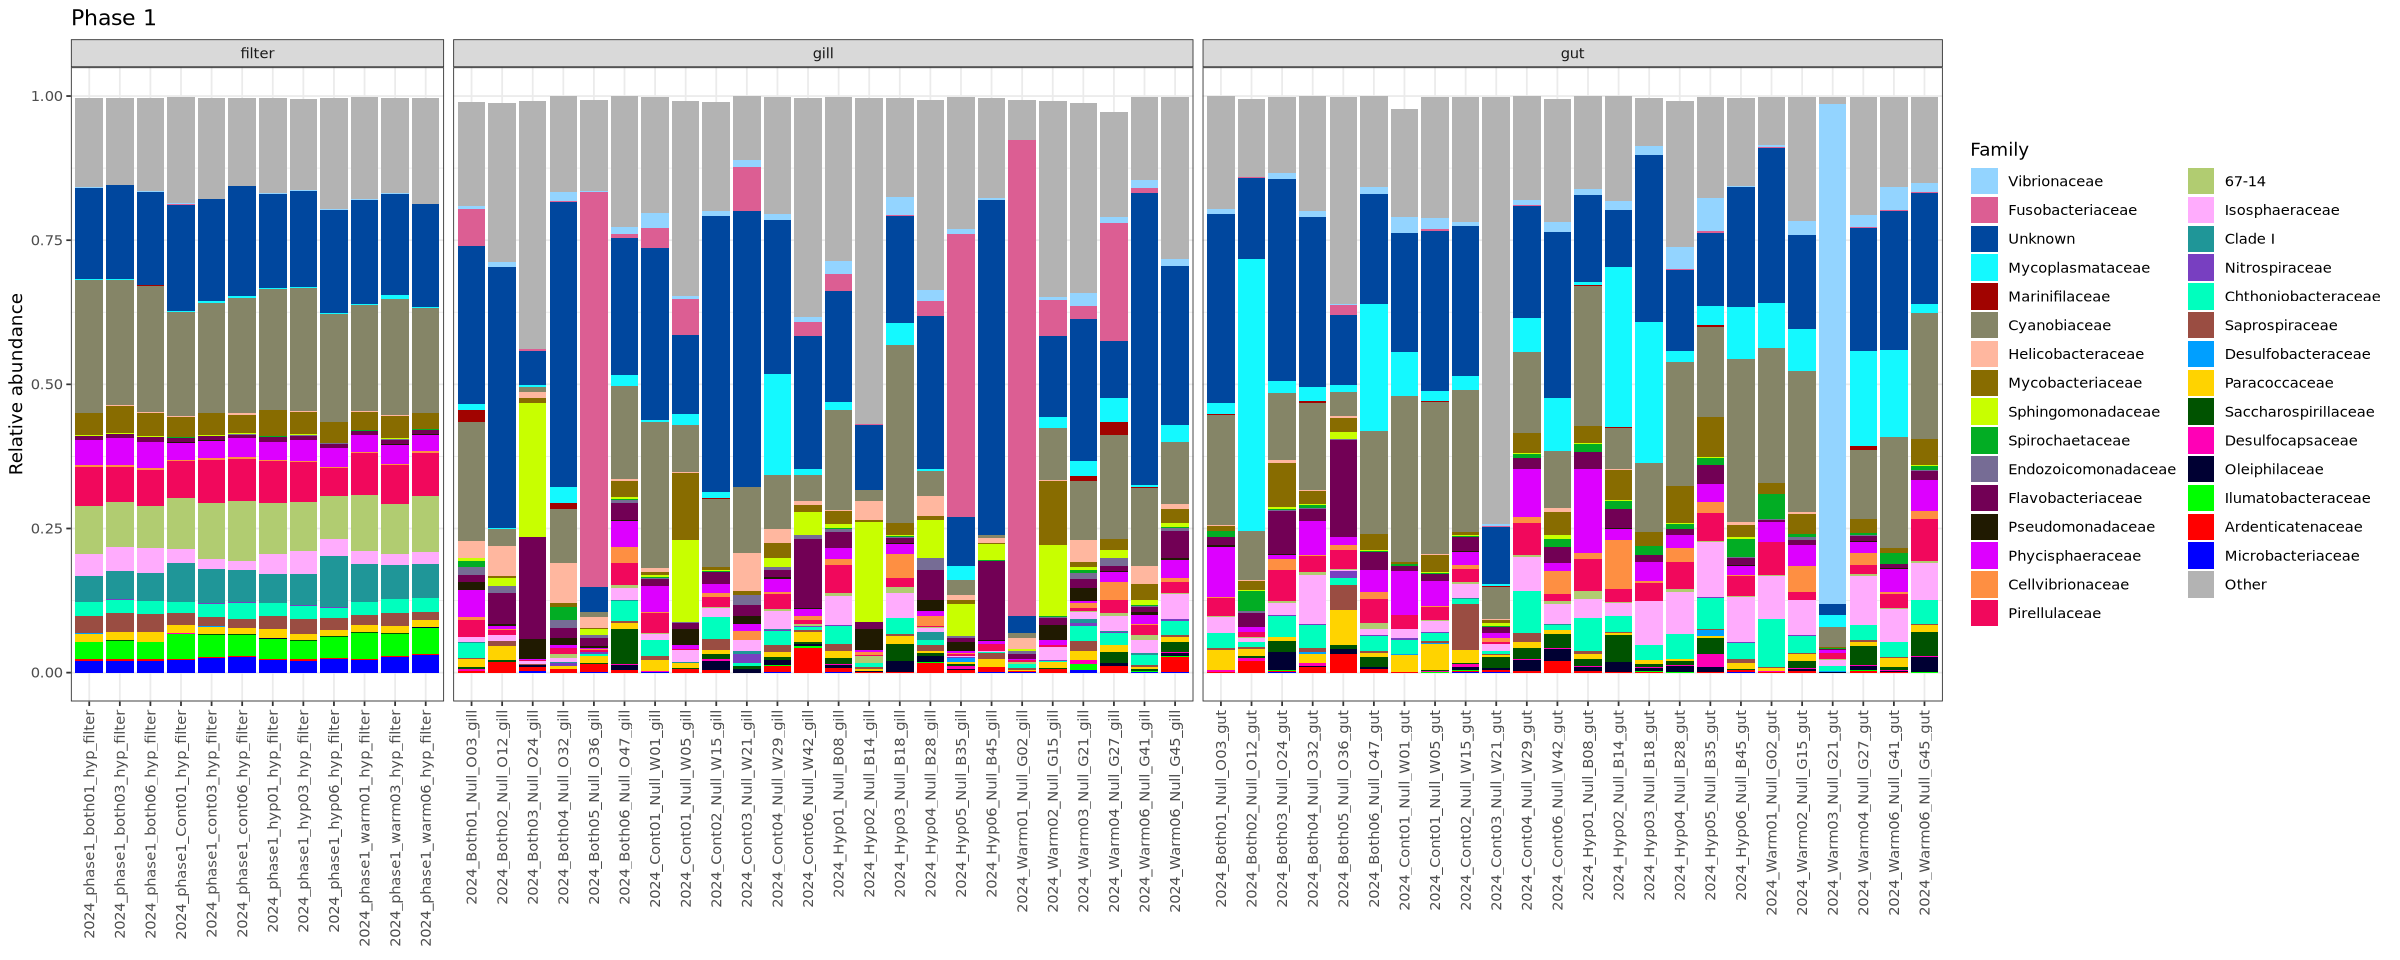

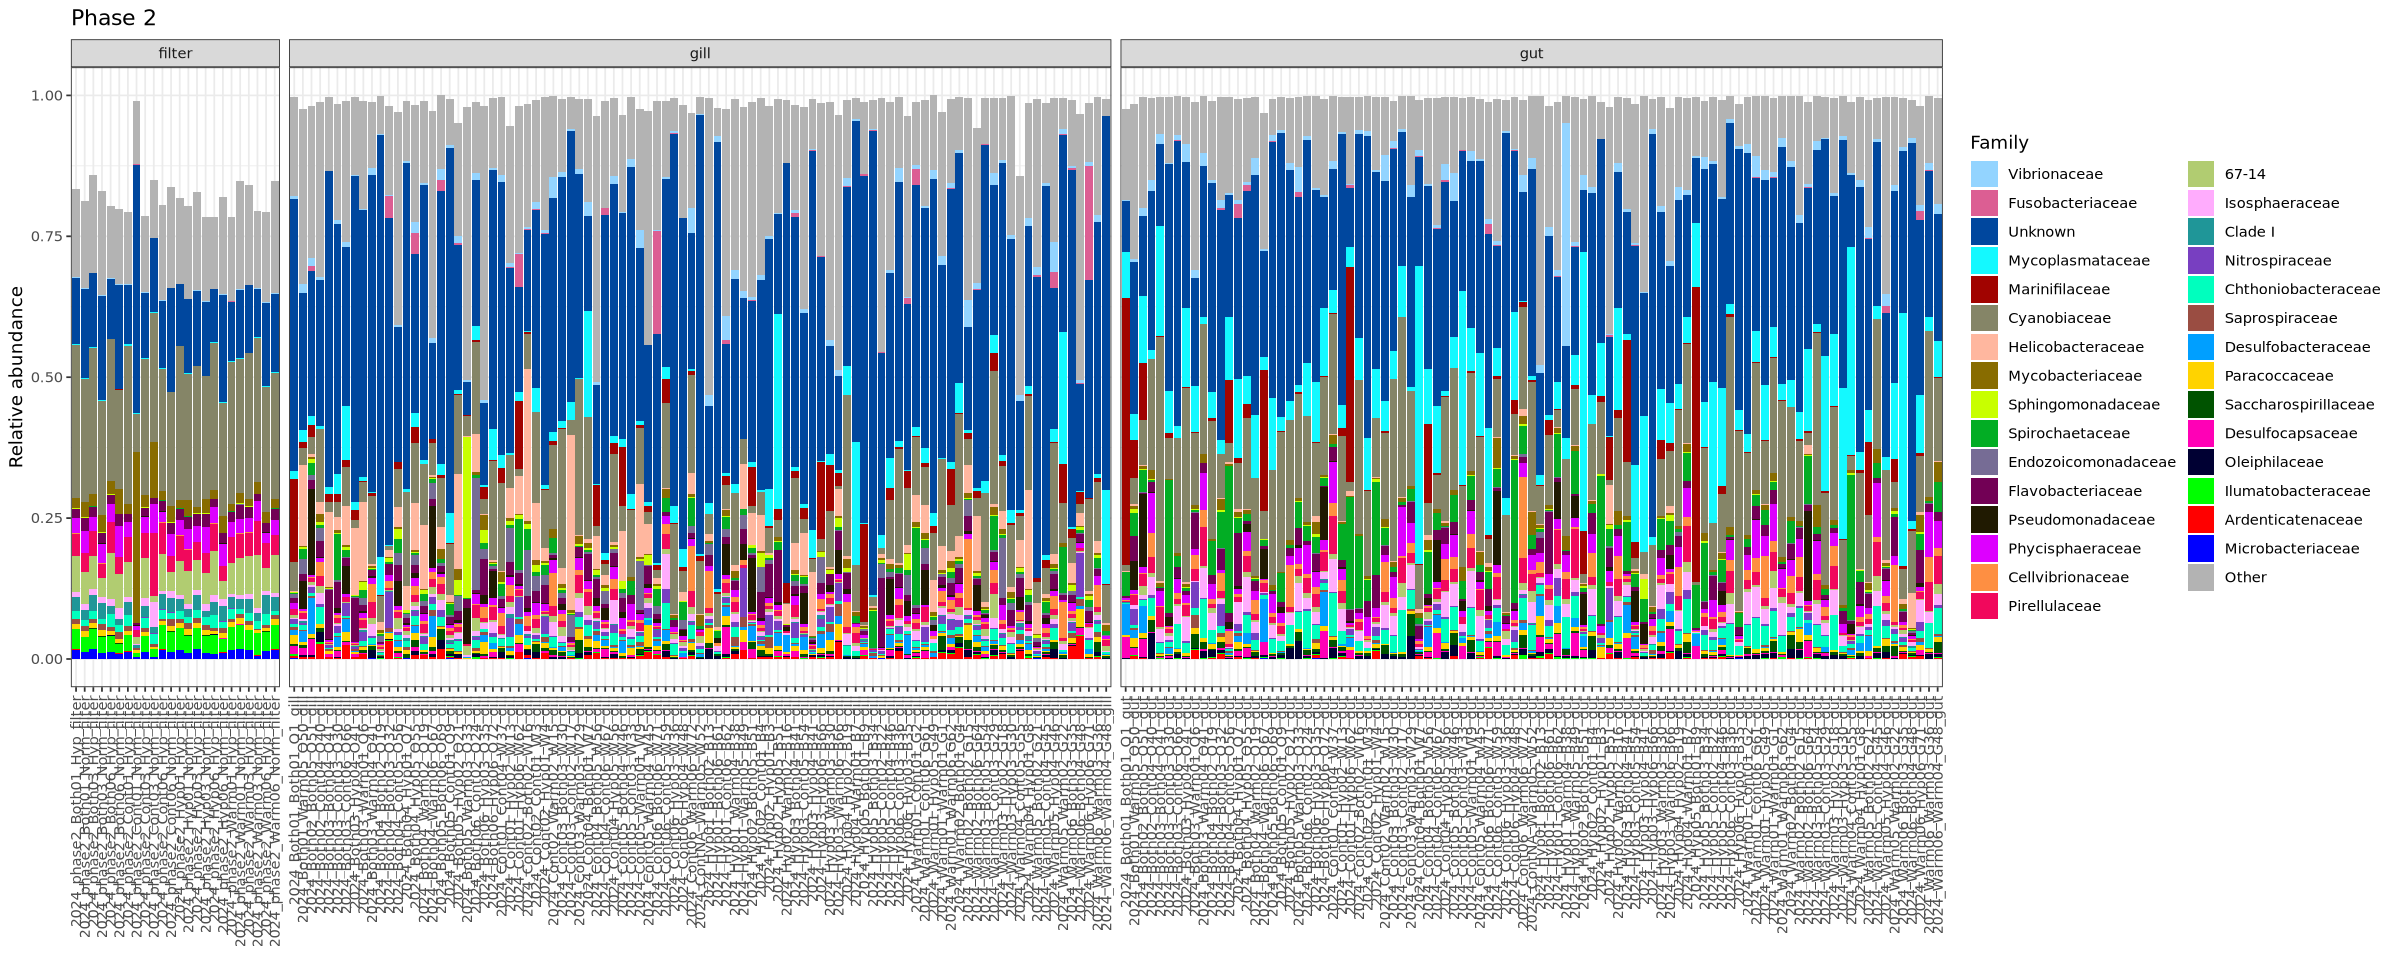

In [22]:
# Plot phase 1 samples bar plot
p_comp_p1 <- family_df %>% filter(Phase == 1) %>% 
  ggplot(aes(x = Sample, y = Abundance, fill = OTU)) +
  geom_col() +
  scale_fill_manual(values = colors, breaks = c(setdiff(levels(family_df$OTU), "Other"), "Other")) +
  labs(x = NULL, y = "Relative abundance", fill = "Family", title="Phase 1") +
  facet_grid(. ~ Tissue, scales = "free_x", space = "free_x") +
  theme_bw() +
  theme(axis.text.x  = element_text(angle = 90, hjust = 1, vjust = 0.5), legend.position = "right")

# Plot phase 2 samples bar plot
p_comp_p2 <- family_df %>% filter(Phase == 2) %>% 
  ggplot(aes(x = Sample, y = Abundance, fill = OTU)) +
  geom_col() +
  scale_fill_manual(values = colors, breaks = c(setdiff(levels(family_df$OTU), "Other"), "Other")) +
  labs(x = NULL, y = "Relative abundance", fill = "Family", title="Phase 2") +
  facet_grid(. ~ Tissue, scales = "free_x", space = "free_x") +
  theme_bw() +
  theme(axis.text.x  = element_text(angle = 90, hjust = 1, vjust = 0.5), legend.position = "right")

p_comp_p1
p_comp_p2

- More ASVs fall into "other" suggesting the presence of more rare ASVs (makes sense since we're getting more taxanomically specific)
- Lots more "unknown" too (again, makes sense if 50% of the ASVs were classified at the family level)

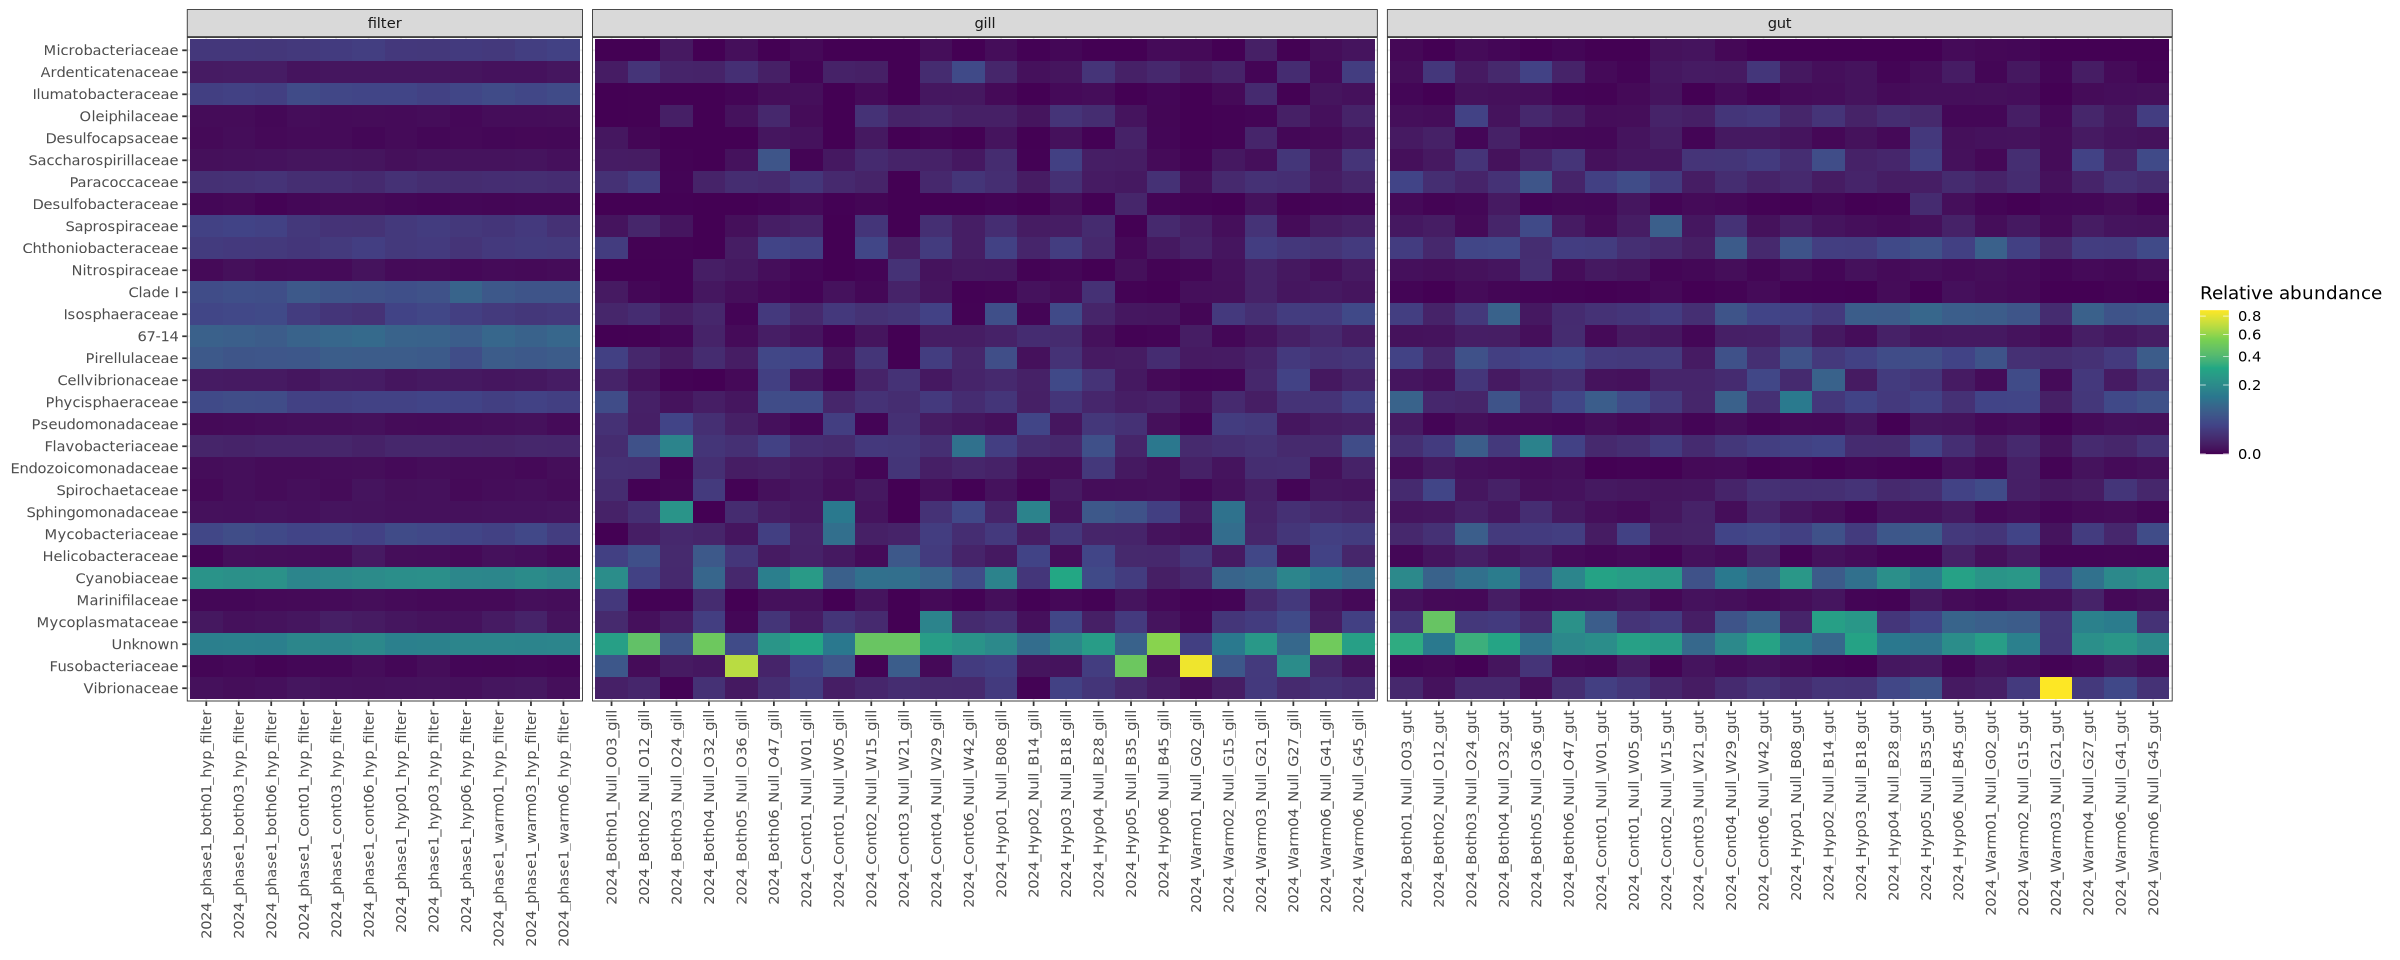

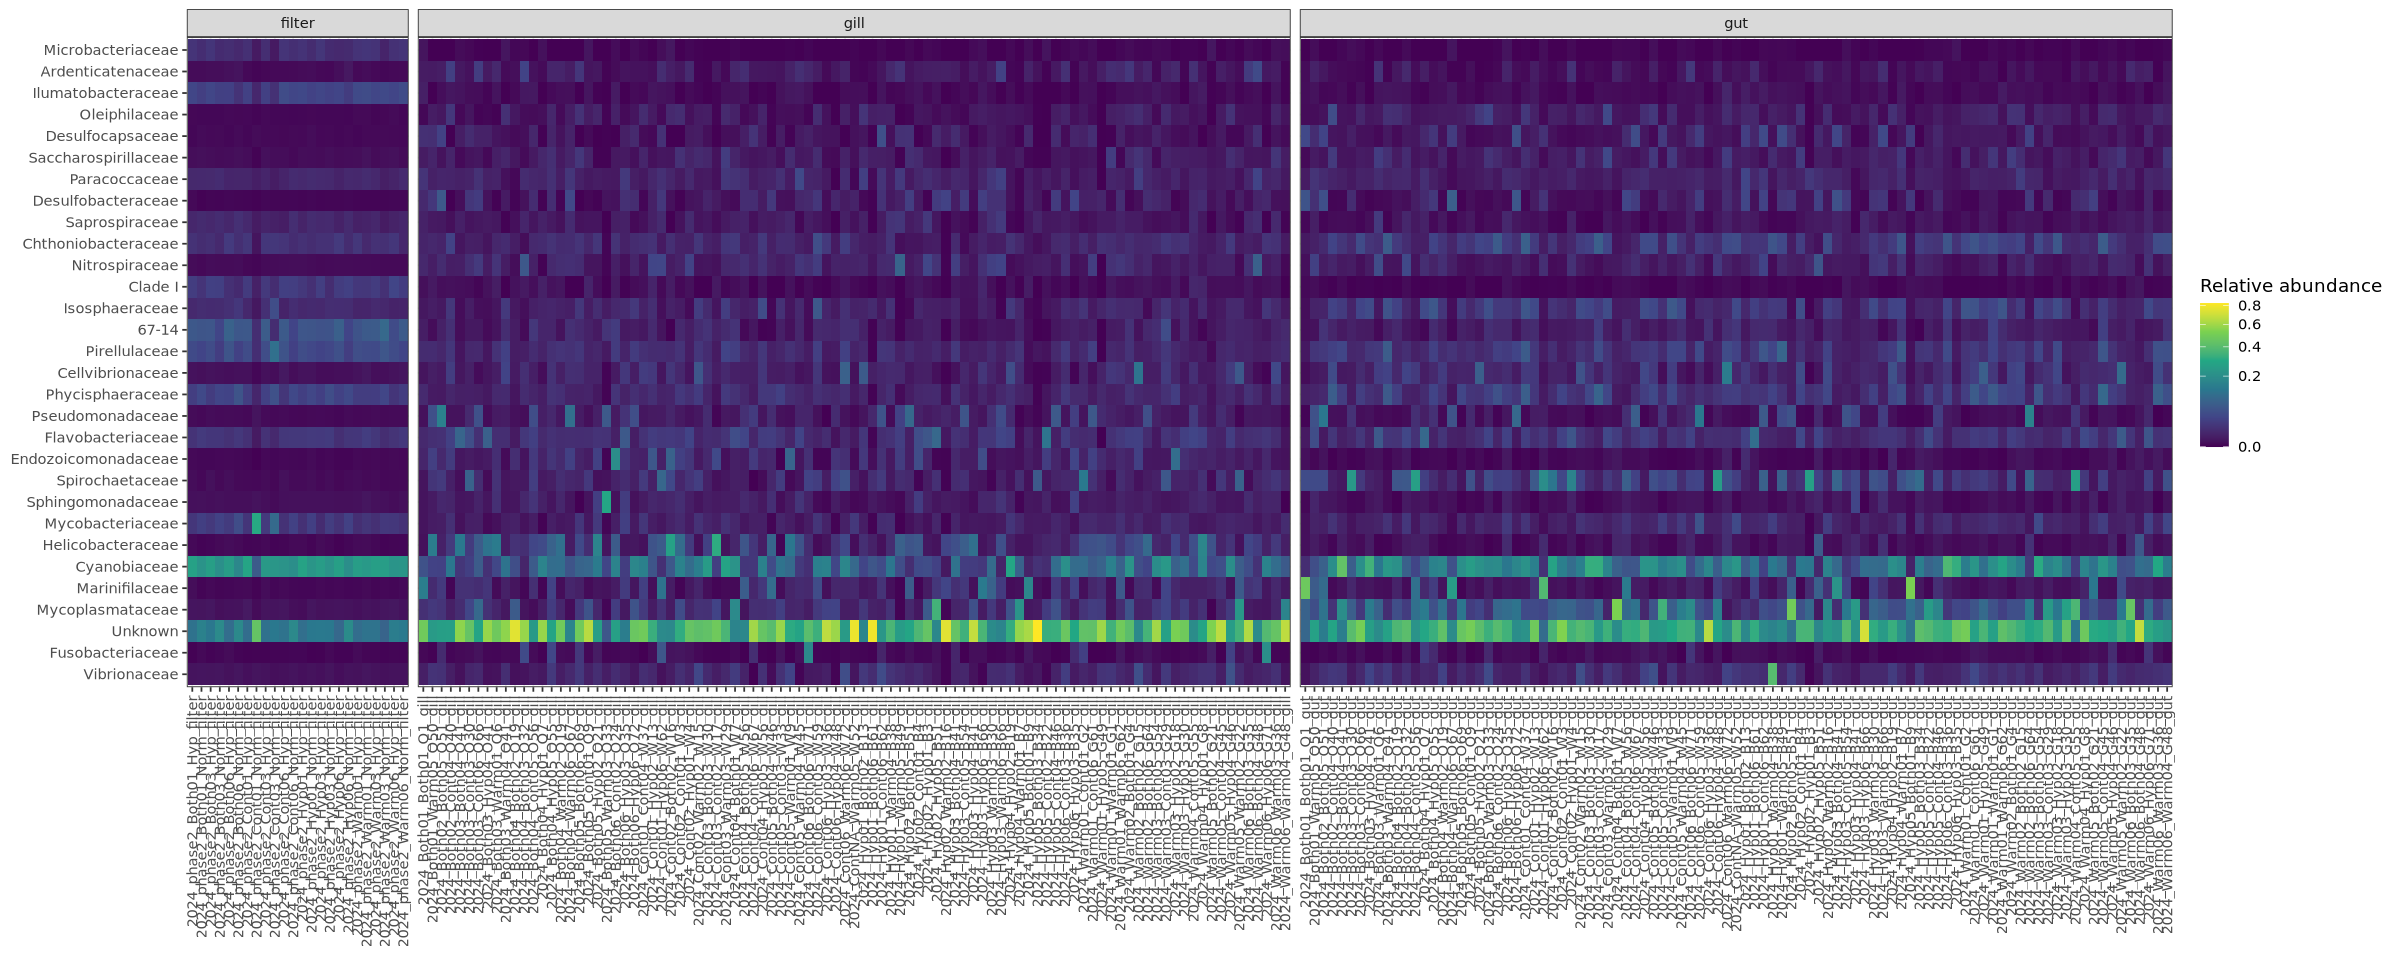

In [23]:
# Plot phase 1 samples heat map
p_heat_p1 <- family_df %>% filter(Phase == 1 & OTU != "Other") %>% 
  ggplot(aes(x = Sample, y = OTU, fill = Abundance)) +
  geom_tile() +
  facet_grid(~ Tissue, scales = "free_x", space = "free_x") +
  scale_fill_viridis_c(trans = "sqrt", name = "Relative abundance") +
  labs(x = NULL, y = NULL) +
  theme_bw() +
  theme(axis.text.x = element_text(angle = 90, hjust = 1, vjust = 0.5))

# Plot phase 2 samples heat map
p_heat_p2 <- family_df %>% filter(Phase == 2 & OTU != "Other") %>% 
  ggplot(aes(x = Sample, y = OTU, fill = Abundance)) +
  geom_tile() +
  facet_grid(~ Tissue, scales = "free_x", space = "free_x") +
  scale_fill_viridis_c(trans = "sqrt", name = "Relative abundance") +
  labs(x = NULL, y = NULL) +
  theme_bw() +
  theme(axis.text.x = element_text(angle = 90, hjust = 1, vjust = 0.5))

p_heat_p1
p_heat_p2

- So many unknown, >50% in most of the gill samples
- Can see in the filter more specifically it is the cyanobiaceae that dominate, even more than the cumulative unknowns
- These cyanobiaceae are also relatively more abundant in the gut than the gill in phase 1 and 2
- The family of mycoplasmataceae are still selectively seen in the gut tissue, a little in the gill, and barely at all in the filter
- Endozoicomonadaceae found only really in the gill tissue

### Genus and species exploration

In [24]:
# Aggregate ASVs to the genus level
ps_genus <- aggregate_taxa(ps_bacteria, level = "Genus")
ps_genus

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 1489 taxa and 281 samples ]
sample_data() Sample Data:       [ 281 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 1489 taxa by 7 taxonomic ranks ]

In [25]:
# Group less rare genuses as "other"
ps_genus_top <- aggregate_rare(ps_genus,level = "Genus",
  detection = 0.01,   # >1% relative abundance
  prevalence = 0.10   # in at least 10% of samples
)

ntaxa(ps_genus_top)
taxa_names(ps_genus_top)

[1] 18

[1] "CL500-29 marine group" "CL500-3"               "Clade Ia"             
 [4] "Cyanobium PCC-6307"    "Fusobacterium"         "LD29"                 
 [7] "Marinifilum"           "Mycobacterium"         "Mycoplasma"           
[10] "Nitrospira"            "Oleiphilus"            "Other"                
[13] "Parendozoicomonas"     "Pseudomonas"           "Synechococcus CC9902" 
[16] "Umboniibacter"         "Unknown"               "Vibrio"

Without even plotting, note that 1489 genuses were identified but only 18 had >1% relative abundance and were present in at least 10% of samples. Some of these are familiar based off of the existing literature as well as the orders/families already identified:
- Mycoplasma
- Pseudomonas
- Vibrio

In [26]:
# Create data frame from phyloseq object
genus_df <- psmelt(ps_genus_top)
head(genus_df)

,OTU,Sample,Abundance,Year,Combined_treat,Phase_1_treat,Phase_1_rep,Phase_2_treat,Phase_2_rep,Tag,⋯,Index_date,Index_volume,Clean_date,Clean_date_2,Gel_extraction,Final_concentration,X25ng,Notes,Genus,unique
,<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>,<int>,<chr>,<int>,<chr>,⋯,<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>
3147,Other,Positive_control_NA,0.9513797,Positive,NANA,NA,NA,NA,NA,NA,⋯,2026-07-31,2,NA,NA,8/4/26,5.50,4.55,,Other,Other
4703,Unknown,2024_Hyp05_Both03_B34_gill,0.9212760,2024,HB,Hyp,5,Both,3,B34,⋯,2026-07-06,1,7/6/26,NA,7/7/26,4.02,6.22,,Unknown,Unknown
4549,Unknown,2024_Warm06_Warm04_G48_gill,0.8799009,2024,WW,Warm,6,Warm,4,G48,⋯,2026-06-26,2,6/30/26,7/1/26,NA,6.44,3.88,,Unknown,Unknown
4792,Vibrio,2024_Warm03_Null_G21_gut,0.8670175,2024,WNA,Warm,3,NA,NA,G21,⋯,2026-06-26,2,6/30/26,7/1/26,NA,4.48,5.58,,Vibrio,Vibrio
4731,Unknown,2024_Cont03_Cont02_W17_gill,0.8664892,2024,CC,Cont,3,Cont,2,W17,⋯,2026-07-06,1,7/6/26,NA,NA,9.20,2.72,Diluted final sample 1:3,Unknown,Unknown
4575,Unknown,2024_Both04_Both02_O19_gill,0.8632166,2024,BB,Both,4,Both,2,O19,⋯,2026-07-03,2,7/3/26,NA,NA,14.70,1.70,,Unknown,Unknown


In [27]:
# Order genuses so that "Other" sits at the bottom of each bar
genus_levels <- c("Other", setdiff(unique(genus_df$OTU), "Other"))
genus_df <- genus_df %>%
  mutate(OTU = factor(OTU, levels = genus_levels)) 

In [31]:
# Set up color palette
colors <- sky.colors(n = 20)
names(colors) <- levels(genus_df$OTU)
colors["Other"] <- "grey70"
options(repr.plot.width=20, repr.plot.height=8)

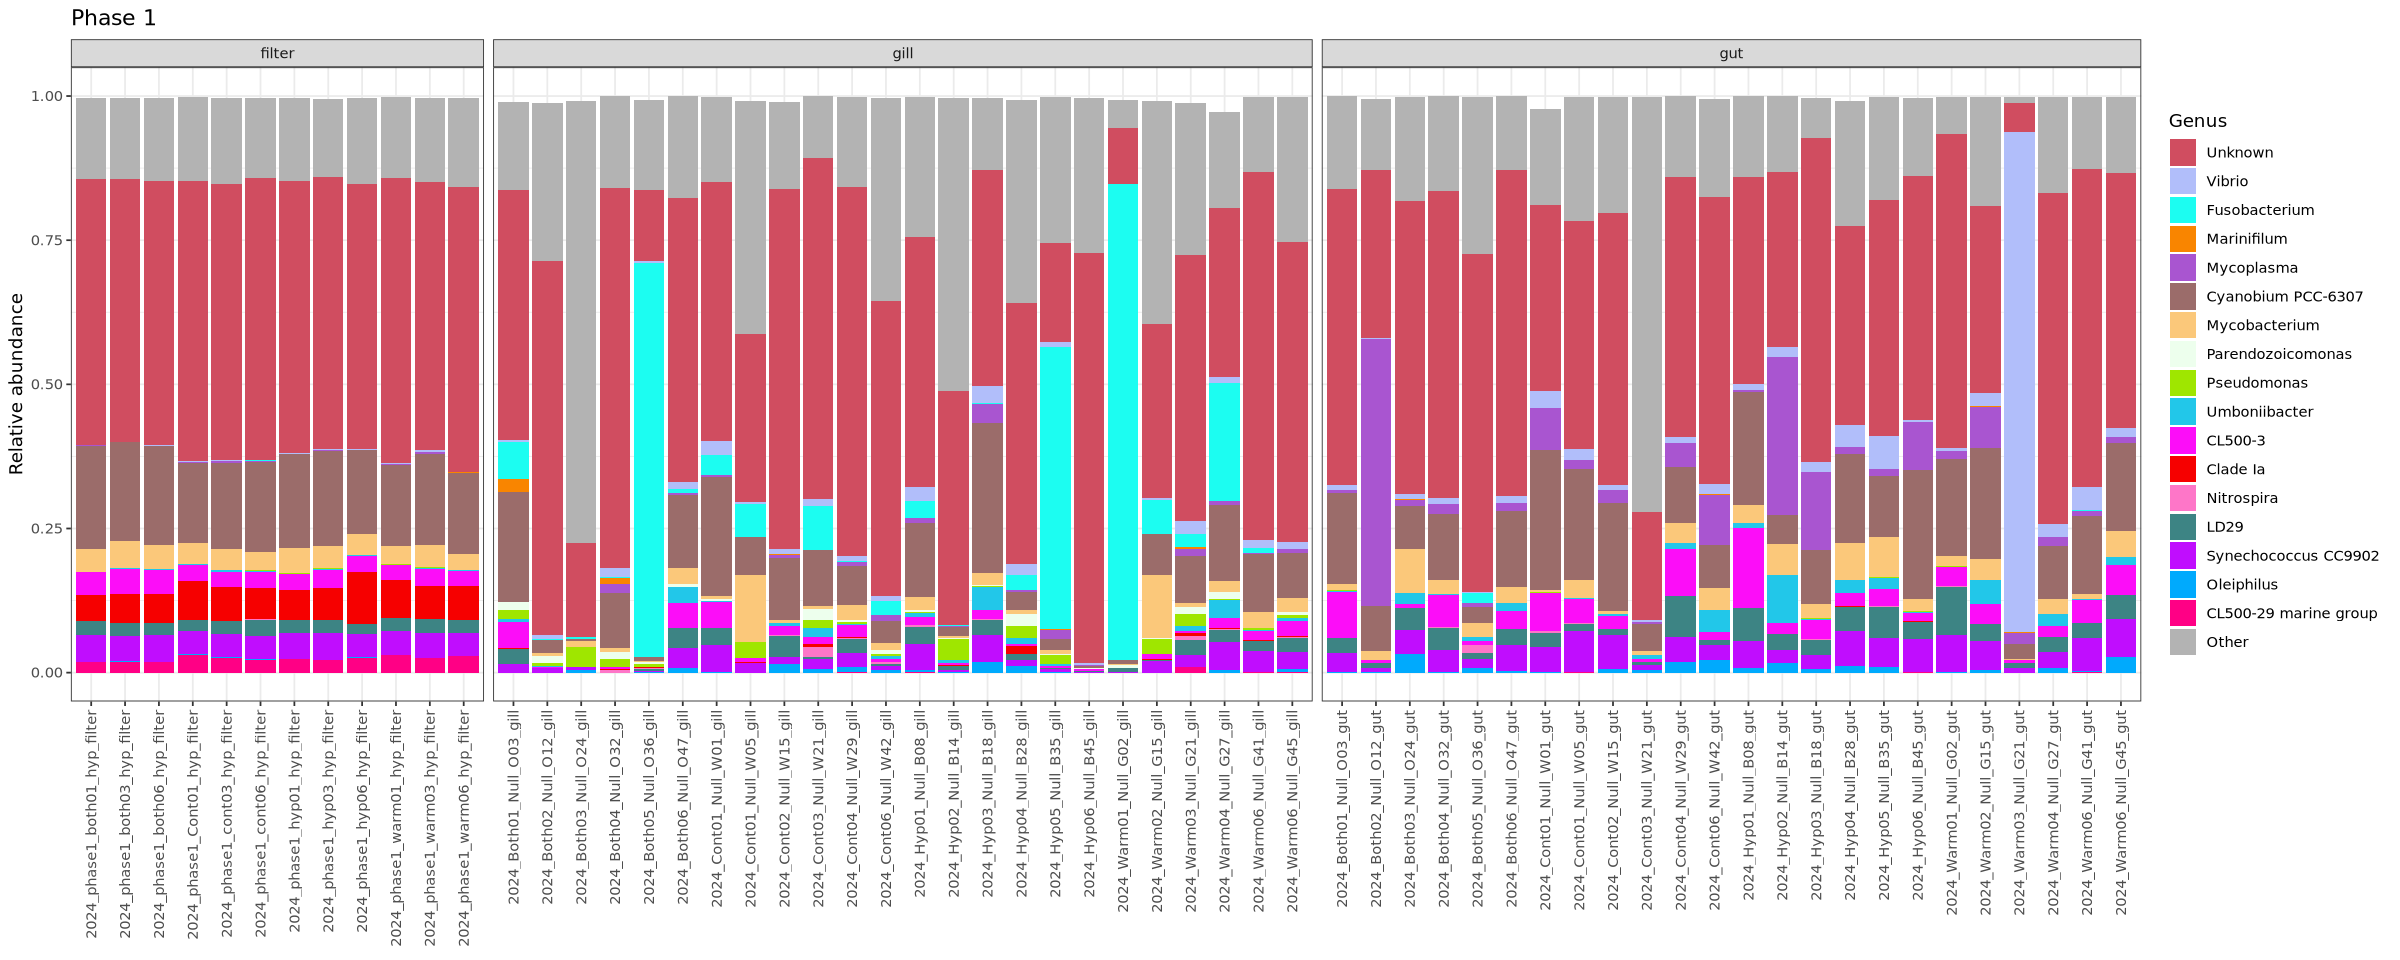

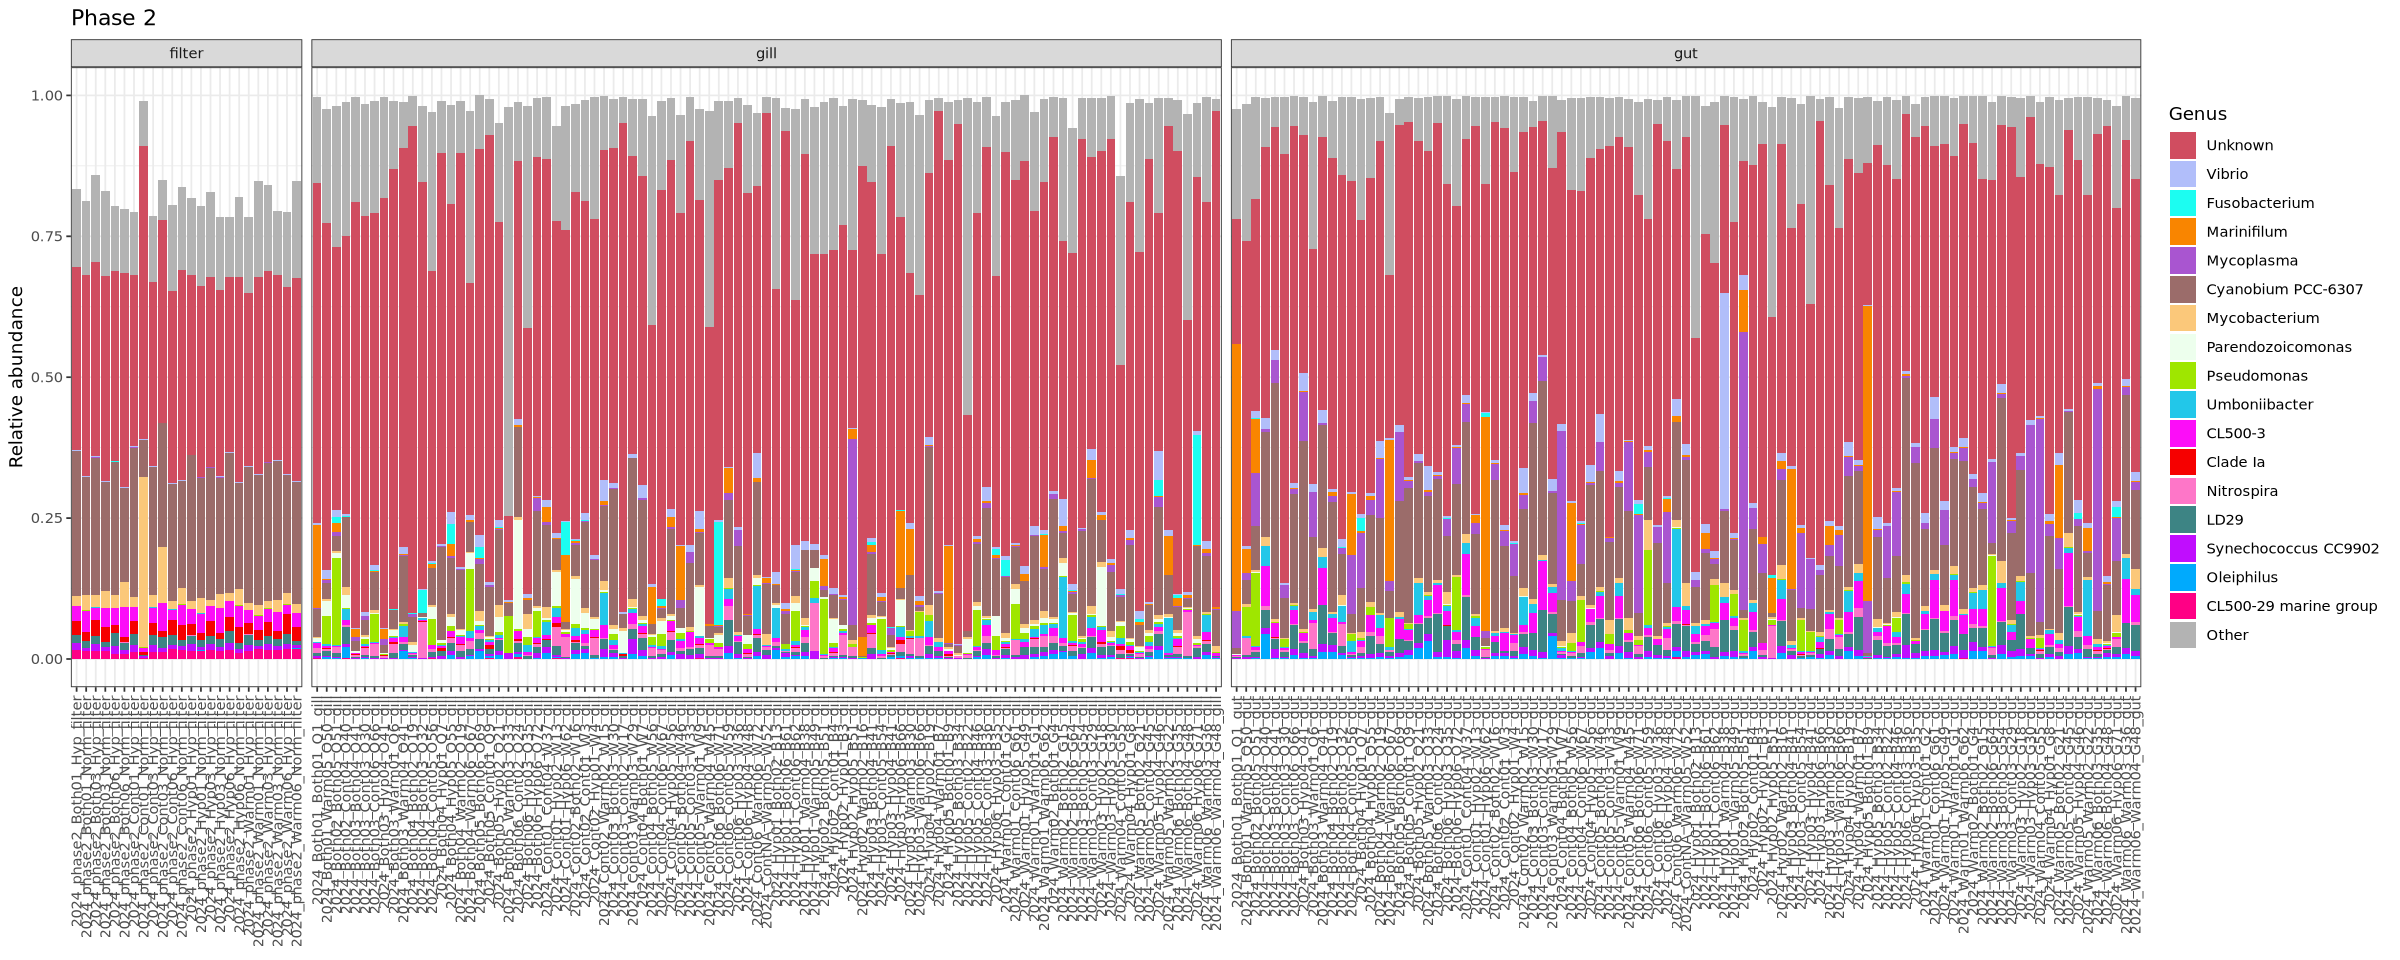

In [32]:
# Plot phase 1 samples bar plot
p_comp_p1 <- genus_df %>% filter(Phase == 1) %>% 
  ggplot(aes(x = Sample, y = Abundance, fill = OTU)) +
  geom_col() +
  scale_fill_manual(values = colors, breaks = c(setdiff(levels(genus_df$OTU), "Other"), "Other")) +
  labs(x = NULL, y = "Relative abundance", fill = "Genus", title="Phase 1") +
  facet_grid(. ~ Tissue, scales = "free_x", space = "free_x") +
  theme_bw() +
  theme(axis.text.x  = element_text(angle = 90, hjust = 1, vjust = 0.5), legend.position = "right")

# Plot phase 2 samples bar plot
p_comp_p2 <- genus_df %>% filter(Phase == 2) %>% 
  ggplot(aes(x = Sample, y = Abundance, fill = OTU)) +
  geom_col() +
  scale_fill_manual(values = colors, breaks = c(setdiff(levels(genus_df$OTU), "Other"), "Other")) +
  labs(x = NULL, y = "Relative abundance", fill = "Genus", title="Phase 2") +
  facet_grid(. ~ Tissue, scales = "free_x", space = "free_x") +
  theme_bw() +
  theme(axis.text.x  = element_text(angle = 90, hjust = 1, vjust = 0.5), legend.position = "right")

p_comp_p1
p_comp_p2

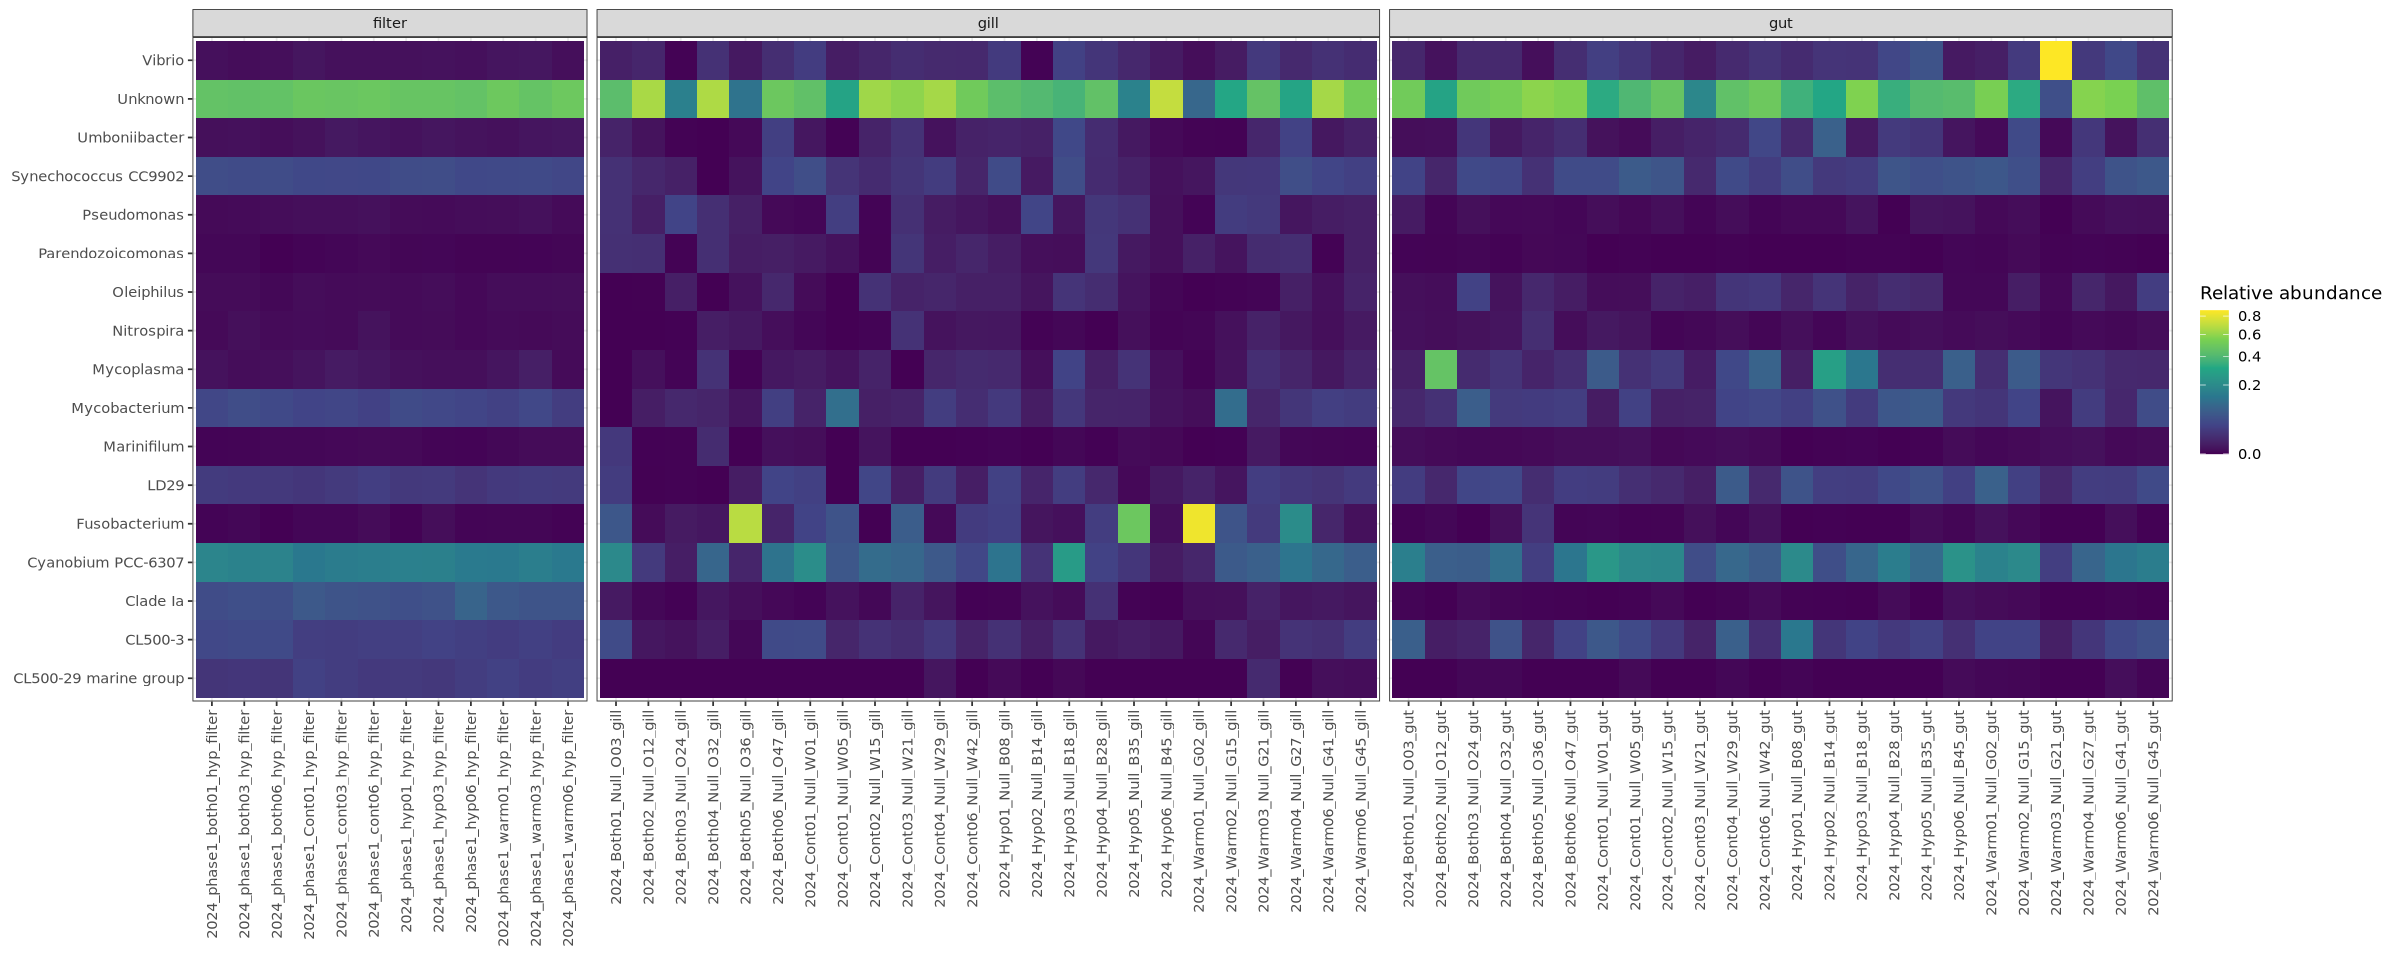

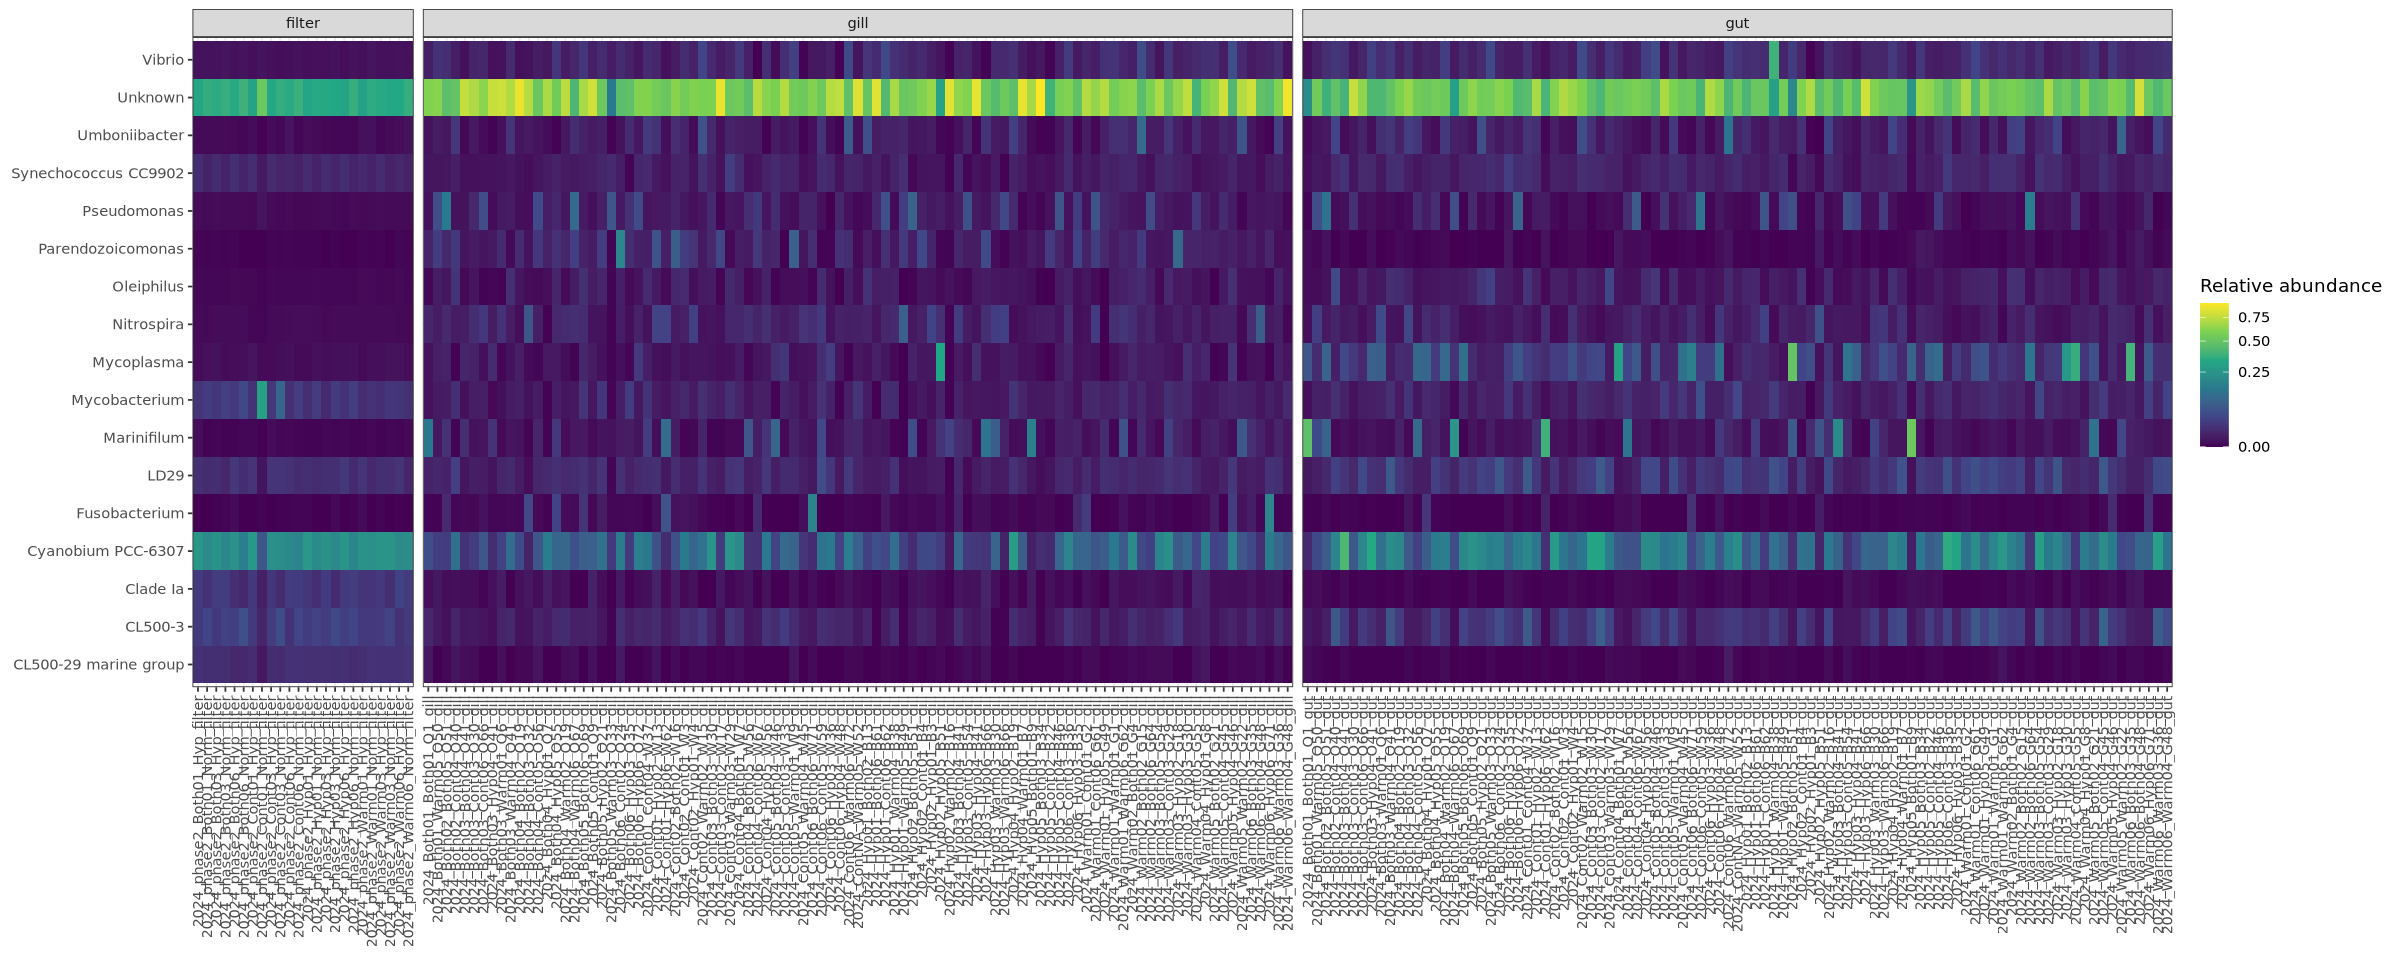

In [128]:
# Plot phase 1 samples heat map
p_heat_p1 <- genus_df %>% filter(Phase == 1 & OTU != "Other") %>% 
  ggplot(aes(x = Sample, y = OTU, fill = Abundance)) +
  geom_tile() +
  facet_grid(~ Tissue, scales = "free_x", space = "free_x") +
  scale_fill_viridis_c(trans = "sqrt", name = "Relative abundance") +
  labs(x = NULL, y = NULL) +
  theme_bw() +
  theme(axis.text.x = element_text(angle = 90, hjust = 1, vjust = 0.5))

# Plot phase 2 samples heat map
p_heat_p2 <- genus_df %>% filter(Phase == 2 & OTU != "Other") %>% 
  ggplot(aes(x = Sample, y = OTU, fill = Abundance)) +
  geom_tile() +
  facet_grid(~ Tissue, scales = "free_x", space = "free_x") +
  scale_fill_viridis_c(trans = "sqrt", name = "Relative abundance") +
  labs(x = NULL, y = NULL) +
  theme_bw() +
  theme(axis.text.x = element_text(angle = 90, hjust = 1, vjust = 0.5))

p_heat_p1
p_heat_p2

In addition to the genuses I already called out, the relatively greater abundance of CL500-3 in gut vs gill is interesting to me (food/digestion related?), as well as the parendozoicomonas which we see in the gill but absent from the filter and just barely present in the gut. 

In [33]:
# Extract taxonomy table
tax <- as.data.frame(tax_table(ps_bacteria))

# Create combined Genus-Species classification
tax$GenusSpecies <- paste(tax$Genus, tax$Species, sep = "_")

# Add combined classification to phyloseq object
tax_table(ps_bacteria) <- tax_table(as.matrix(tax))

In [34]:
# Aggregate ASVs to the species level
ps_species <- aggregate_taxa(ps_bacteria, level = "GenusSpecies")
ps_species

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 2535 taxa and 281 samples ]
sample_data() Sample Data:       [ 281 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 2535 taxa by 9 taxonomic ranks ]

In [35]:
# Group less rare species as "other"
ps_species_top <- aggregate_rare(ps_species,level = "GenusSpecies",
  detection = 0.01,   # >1% relative abundance
  prevalence = 0.10   # in at least 10% of samples
)

ntaxa(ps_species_top)
taxa_names(ps_species_top)

[1] 18

[1] "CL500-29 marine group_NA"  "CL500-3_NA"               
 [3] "Clade Ia_NA"               "Cyanobium PCC-6307_NA"    
 [5] "Fusobacterium_perfoetens"  "LD29_NA"                  
 [7] "Marinifilum_NA"            "Mycobacterium_NA"         
 [9] "Mycoplasma_NA"             "NA_NA"                    
[11] "Nitrospira_NA"             "Oleiphilus_NA"            
[13] "Other"                     "Parendozoicomonas_NA"     
[15] "Pseudomonas_NA"            "Synechococcus CC9902_NA"  
[17] "Umboniibacter_caenipelagi" "Vibrio_NA"

In [36]:
# Create data frame from phyloseq object
species_df <- psmelt(ps_species_top)
head(species_df)

,OTU,Sample,Abundance,Year,Combined_treat,Phase_1_treat,Phase_1_rep,Phase_2_treat,Phase_2_rep,Tag,⋯,Index_date,Index_volume,Clean_date,Clean_date_2,Gel_extraction,Final_concentration,X25ng,Notes,GenusSpecies,unique
,<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>,<int>,<chr>,<int>,<chr>,⋯,<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>
3405,Other,Positive_control_NA,0.9514640,Positive,NANA,NA,NA,NA,NA,NA,⋯,2026-07-31,2,NA,NA,8/4/26,5.50,4.55,,Other,Other
2634,NA_NA,2024_Hyp05_Both03_B34_gill,0.8884872,2024,HB,Hyp,5,Both,3,B34,⋯,2026-07-06,1,7/6/26,NA,7/7/26,4.02,6.22,,NA_NA,NA_NA
3572,Other,2024_Both03_Null_O24_gill,0.8691498,2024,BNA,Both,3,NA,NA,O24,⋯,2026-07-06,1,7/6/26,NA,NA,8.73,2.86,Diluted final sample 1:3,Other,Other
4792,Vibrio_NA,2024_Warm03_Null_G21_gut,0.8670175,2024,WNA,Warm,3,NA,NA,G21,⋯,2026-06-26,2,6/30/26,7/1/26,NA,4.48,5.58,,Vibrio_NA,Vibrio_NA
2680,NA_NA,2024_Warm06_Warm04_G48_gill,0.8576173,2024,WW,Warm,6,Warm,4,G48,⋯,2026-06-26,2,6/30/26,7/1/26,NA,6.44,3.88,,NA_NA,NA_NA
2664,NA_NA,2024_Both04_Both02_O19_gill,0.8406767,2024,BB,Both,4,Both,2,O19,⋯,2026-07-03,2,7/3/26,NA,NA,14.70,1.70,,NA_NA,NA_NA


In [37]:
# Order genuses so that "Other" sits at the bottom of each bar
species_levels <- c("Other", setdiff(unique(species_df$OTU), "Other"))
species_df <- species_df %>%
  mutate(OTU = factor(OTU, levels = species_levels)) 

In [40]:
# Set up color palette
colors <- rev(light.colors(n = 20))
names(colors) <- levels(species_df$OTU)
colors["Other"] <- "grey70"
options(repr.plot.width=20, repr.plot.height=8)

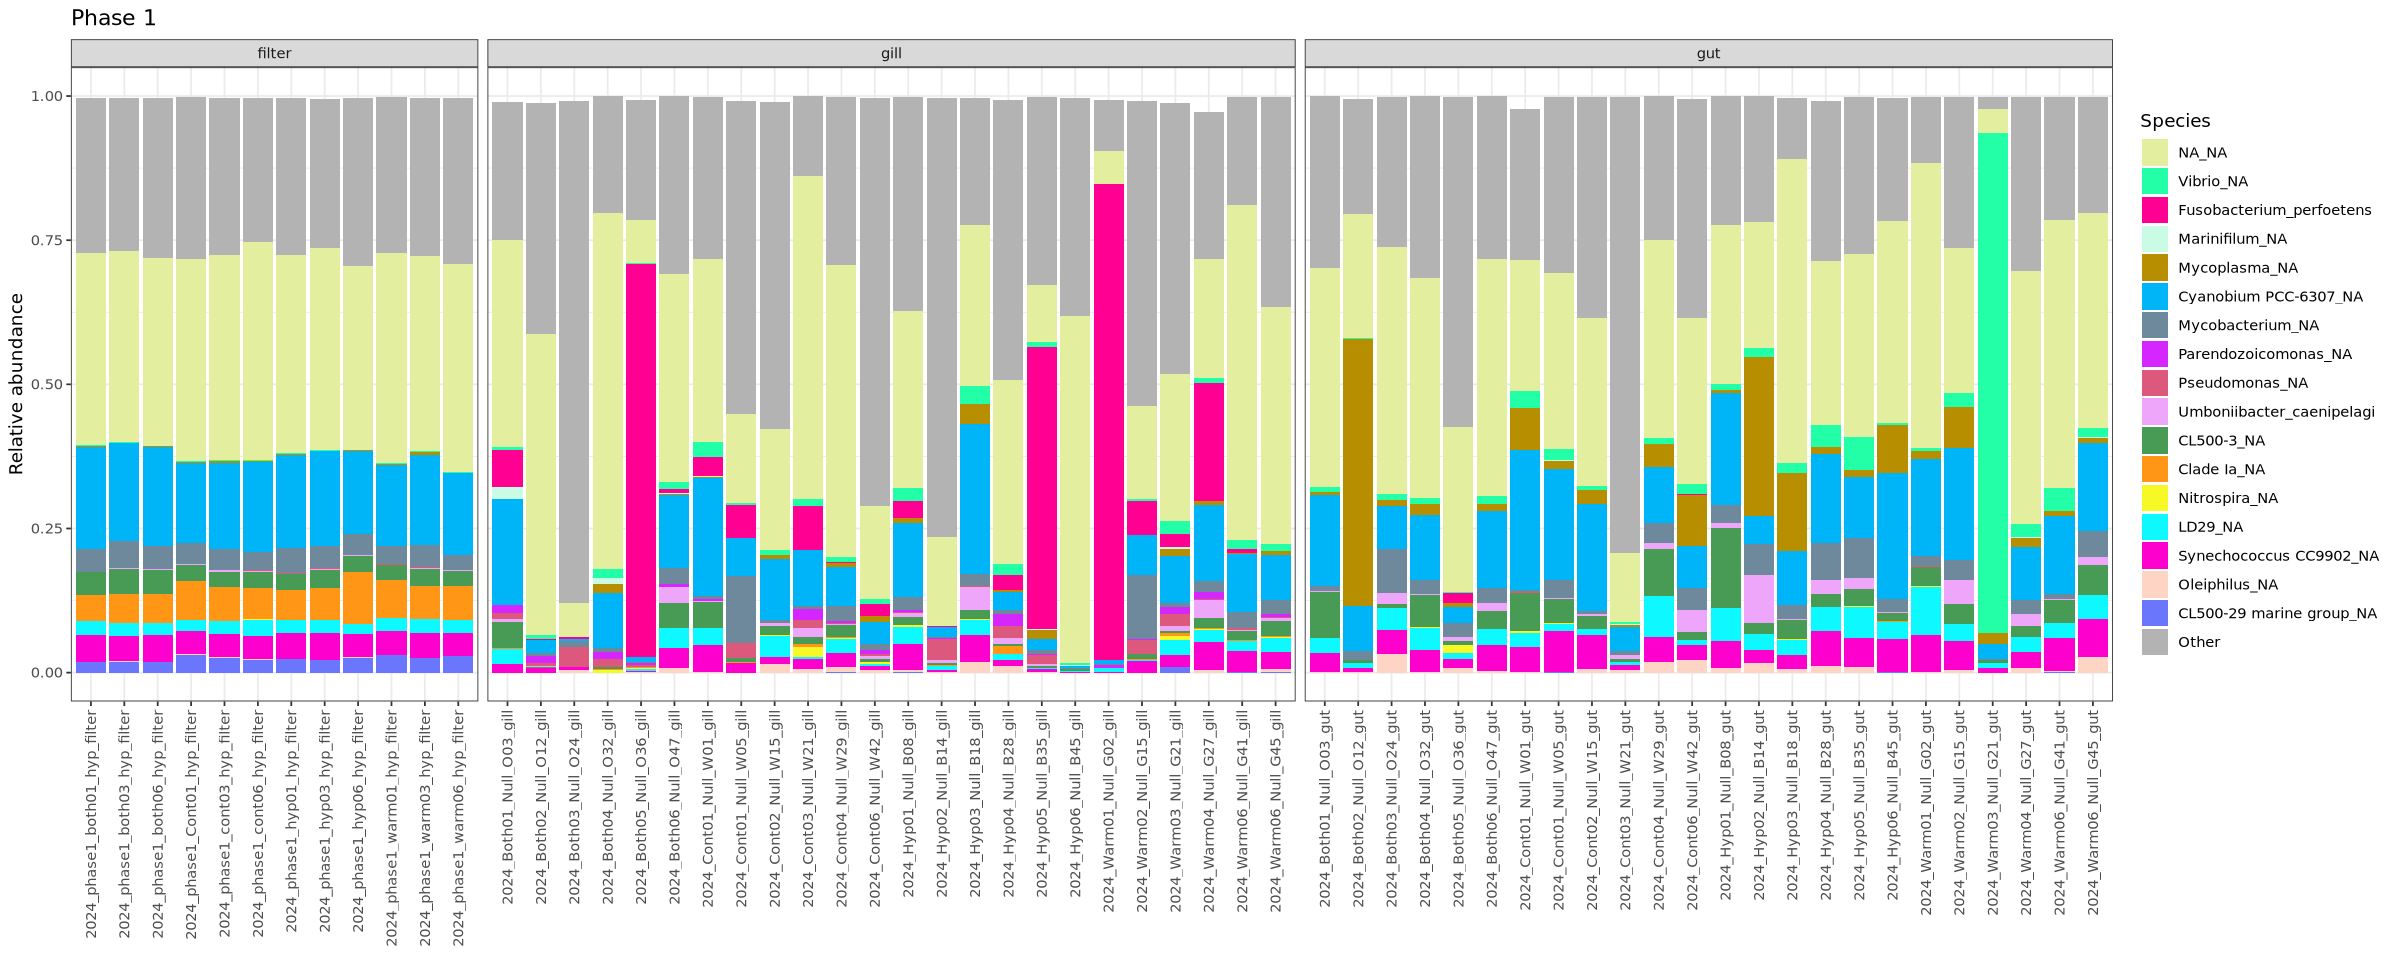

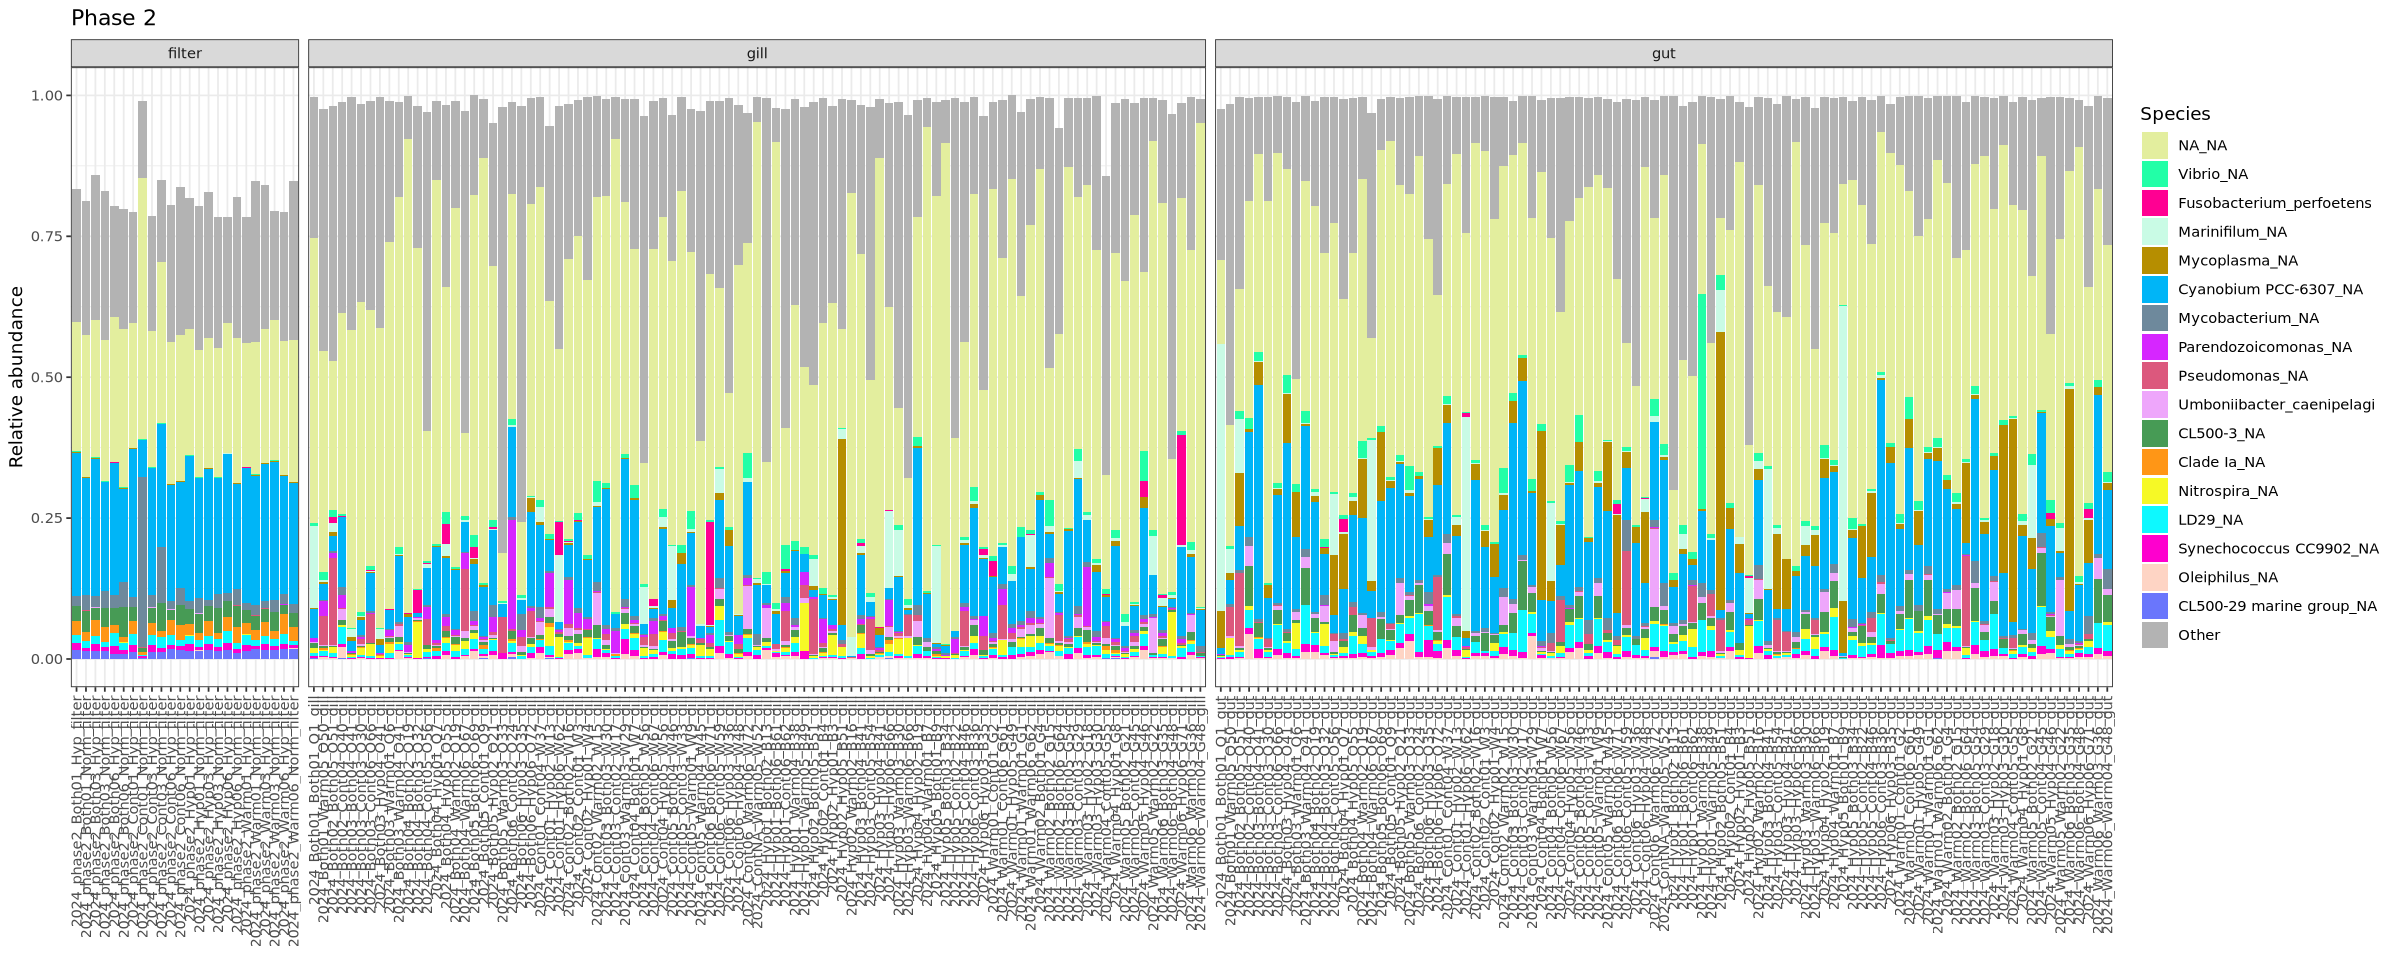

In [41]:
# Plot phase 1 samples bar plot
p_comp_p1 <- species_df %>% filter(Phase == 1) %>% 
  ggplot(aes(x = Sample, y = Abundance, fill = OTU)) +
  geom_col() +
  scale_fill_manual(values = colors, breaks = c(setdiff(levels(species_df$OTU), "Other"), "Other")) +
  labs(x = NULL, y = "Relative abundance", fill = "Species", title="Phase 1") +
  facet_grid(. ~ Tissue, scales = "free_x", space = "free_x") +
  theme_bw() +
  theme(axis.text.x  = element_text(angle = 90, hjust = 1, vjust = 0.5), legend.position = "right")

# Plot phase 2 samples bar plot
p_comp_p2 <- species_df %>% filter(Phase == 2) %>% 
  ggplot(aes(x = Sample, y = Abundance, fill = OTU)) +
  geom_col() +
  scale_fill_manual(values = colors, breaks = c(setdiff(levels(species_df$OTU), "Other"), "Other")) +
  labs(x = NULL, y = "Relative abundance", fill = "Species", title="Phase 2") +
  facet_grid(. ~ Tissue, scales = "free_x", space = "free_x") +
  theme_bw() +
  theme(axis.text.x  = element_text(angle = 90, hjust = 1, vjust = 0.5), legend.position = "right")

p_comp_p1
p_comp_p2

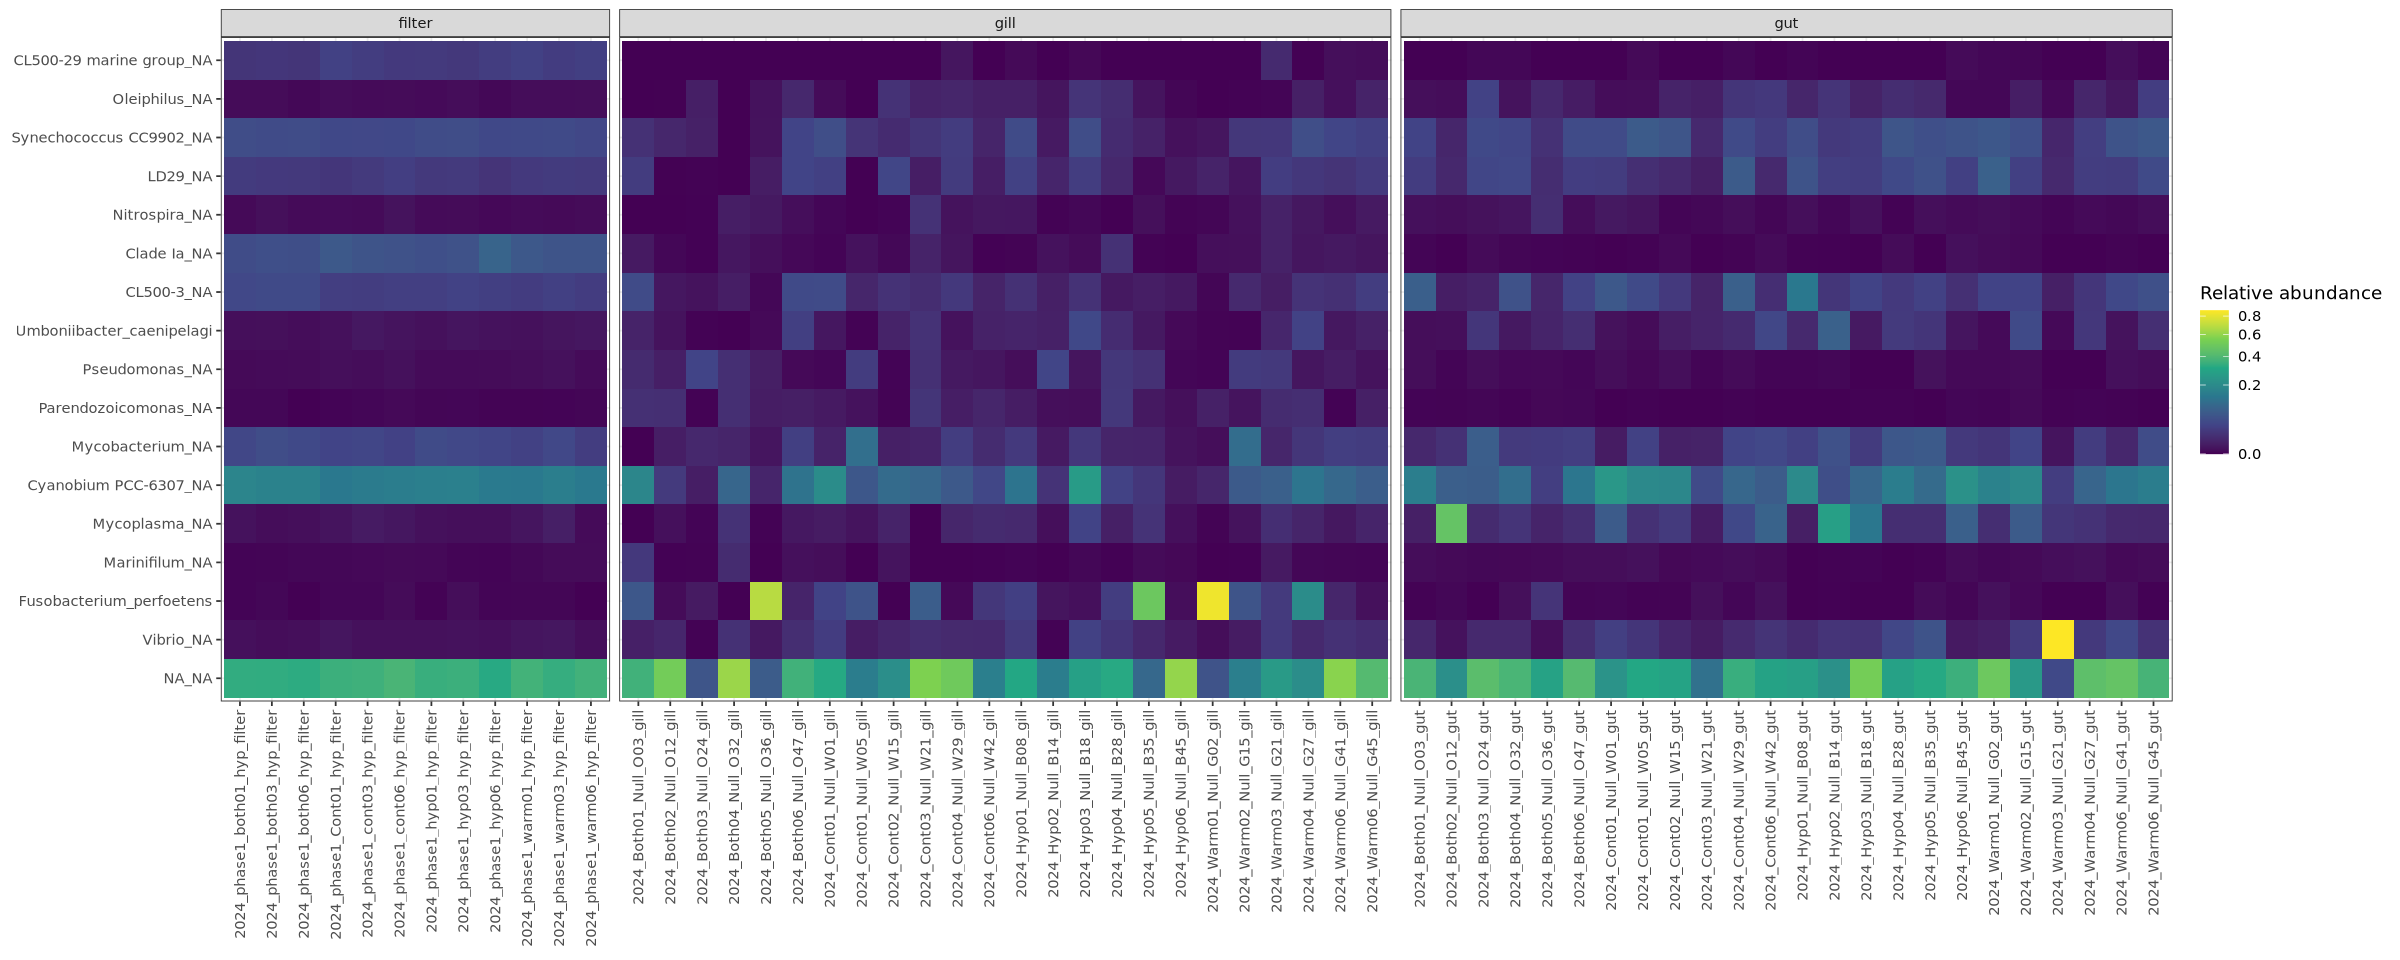

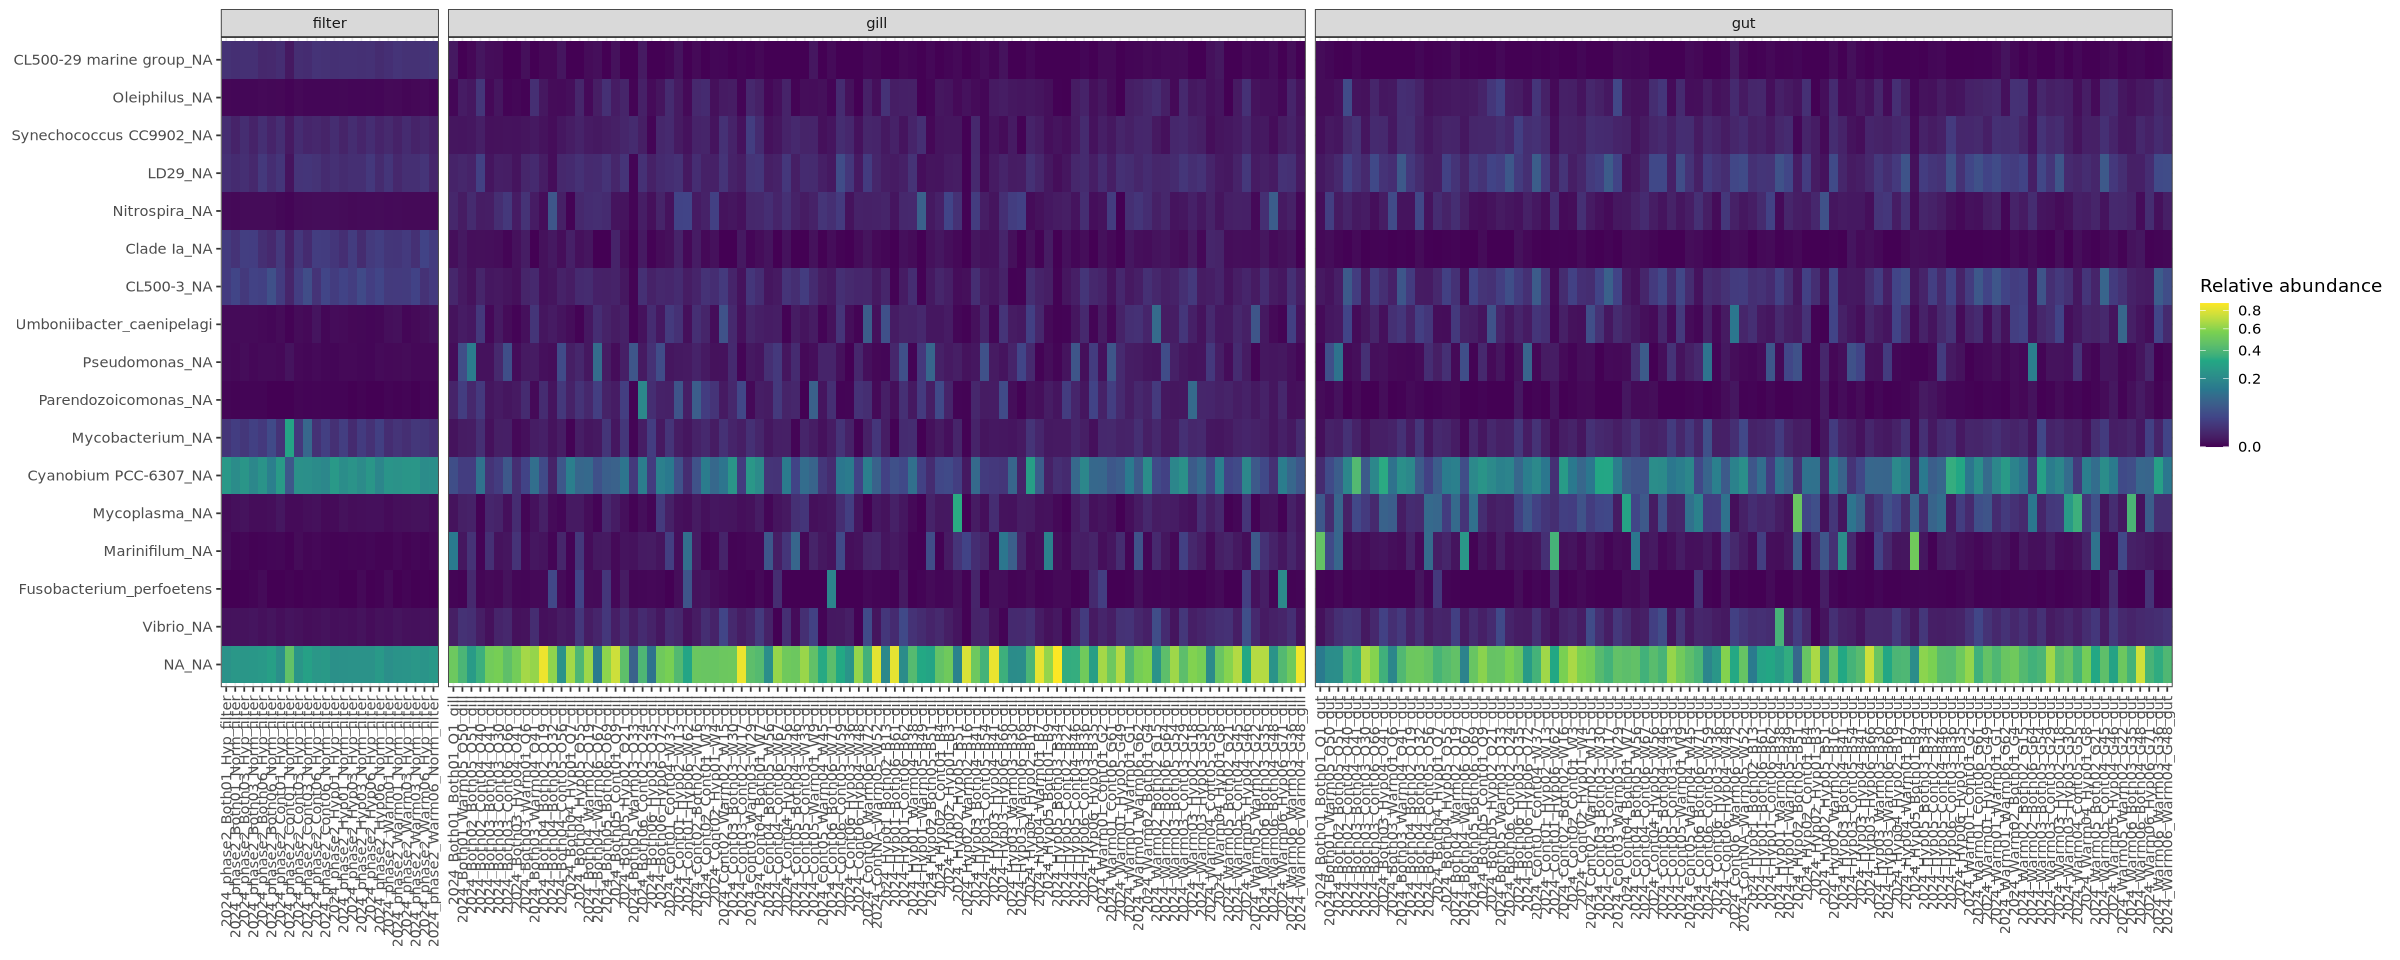

In [42]:
# Plot phase 1 samples heat map
p_heat_p1 <- species_df %>% filter(Phase == 1 & OTU != "Other") %>% 
  ggplot(aes(x = Sample, y = OTU, fill = Abundance)) +
  geom_tile() +
  facet_grid(~ Tissue, scales = "free_x", space = "free_x") +
  scale_fill_viridis_c(trans = "sqrt", name = "Relative abundance") +
  labs(x = NULL, y = NULL) +
  theme_bw() +
  theme(axis.text.x = element_text(angle = 90, hjust = 1, vjust = 0.5))

# Plot phase 2 samples heat map
p_heat_p2 <- species_df %>% filter(Phase == 2 & OTU != "Other") %>% 
  ggplot(aes(x = Sample, y = OTU, fill = Abundance)) +
  geom_tile() +
  facet_grid(~ Tissue, scales = "free_x", space = "free_x") +
  scale_fill_viridis_c(trans = "sqrt", name = "Relative abundance") +
  labs(x = NULL, y = NULL) +
  theme_bw() +
  theme(axis.text.x = element_text(angle = 90, hjust = 1, vjust = 0.5))

p_heat_p1
p_heat_p2

## 11.10.26 | negative controls

In [96]:
# Load packages
suppressPackageStartupMessages({
    library(phyloseq)
    library(tidyverse)
    library(data.table)
    library(Polychrome)
})
    
options(repr.plot.width=15, repr.plot.height=8)

In [47]:
# Read in filtered raw abundance phyloseq object
ps_filt <- readRDS("/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/ps-objects/ps-dada2-filt.rds")

In [55]:
# Prune samples to only include negatives, then prune taxa with zero abundance
ps_neg <- prune_samples(grepl("negative", sample_names(ps_filt), ignore.case = TRUE), ps_filt)
ps_neg <- prune_taxa(taxa_sums(ps_neg) > 0, ps_neg)
ps_neg

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 625 taxa and 6 samples ]
sample_data() Sample Data:       [ 6 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 625 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 625 reference sequences ]

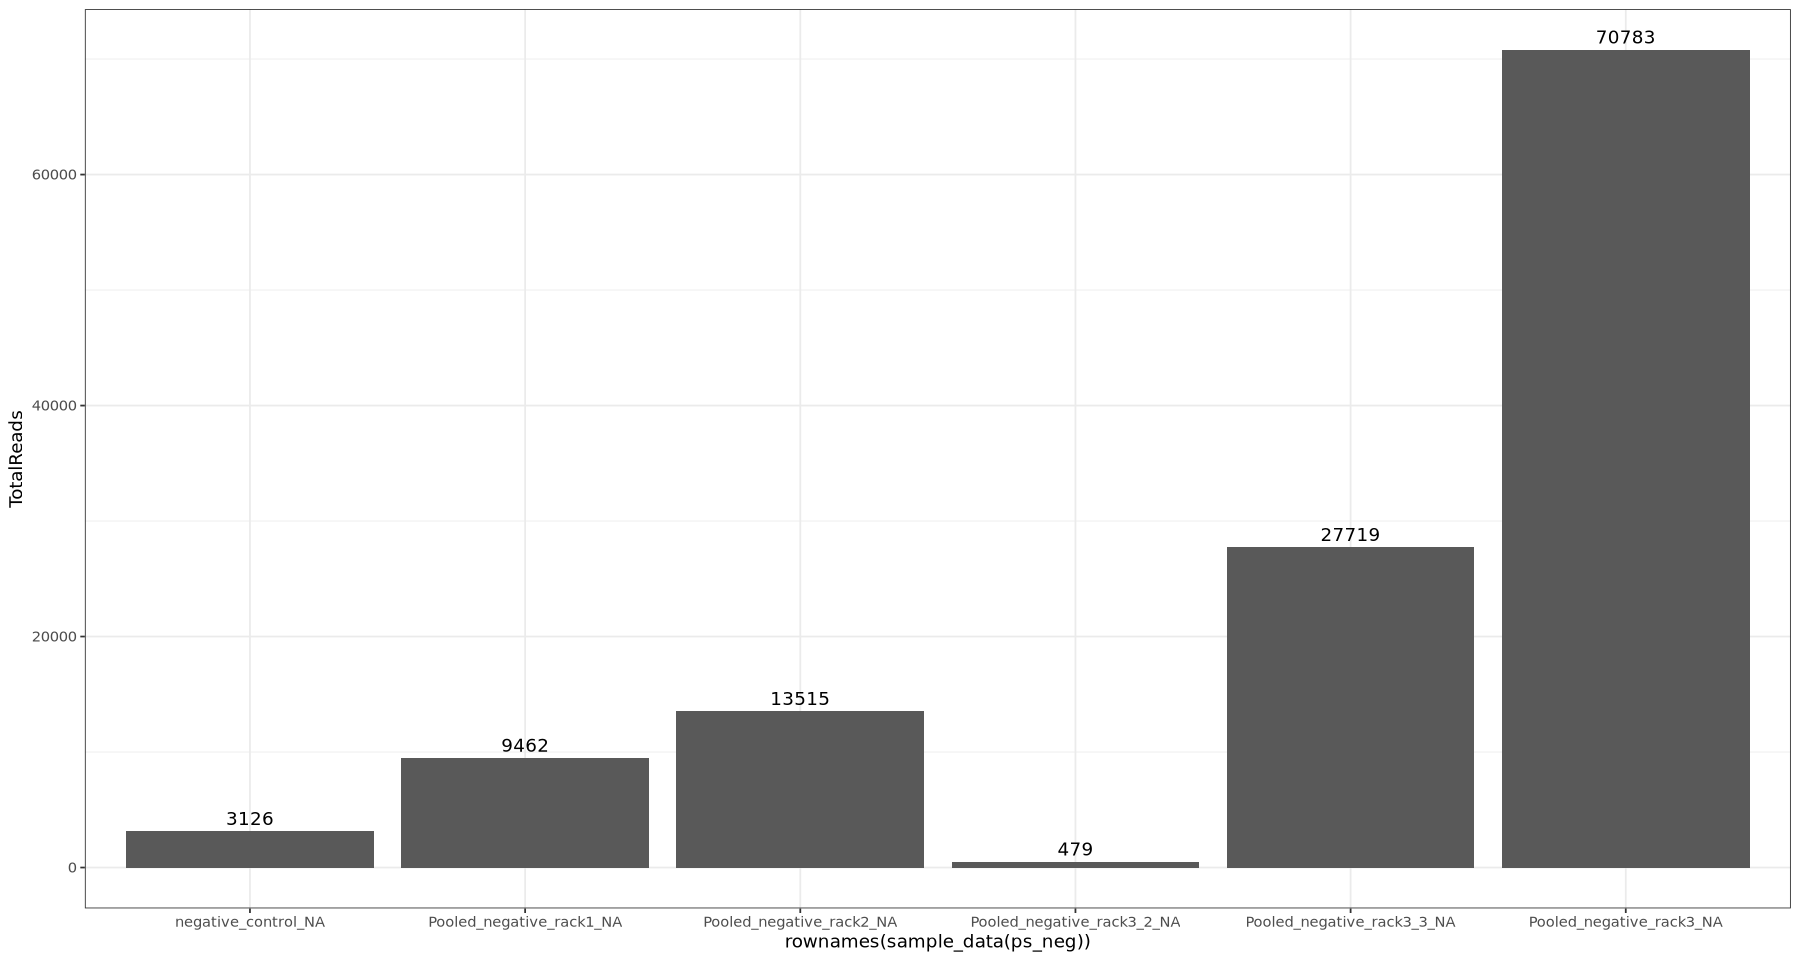

In [56]:
# Check read counts of negatives
readcount_neg <- data.table(as(sample_data(ps_neg), "data.frame"),
                 TotalReads = sample_sums(ps_neg), 
                 keep.rownames = TRUE)
ggplot(readcount_neg, aes(x = rownames(sample_data(ps_neg)), y = TotalReads)) + 
    geom_col() + 
    geom_text(aes(label = TotalReads), vjust = -0.5) +
    theme_bw()

Lower reads than using the decipher taxonomy makes sense since I did a lot more filtering on this phyloseq object

### Composition plots

In [108]:
# Read in relative abundance phyloseq object
ps_rel <- readRDS("/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/ps-objects/ps-dada2-rel.rds")

In [109]:
# Prune samples to only include negatives, then prune taxa with zero abundance
ps_neg_rel <- prune_samples(grepl("negative", sample_names(ps_rel), ignore.case = TRUE), ps_rel)
ps_neg_rel <- prune_taxa(taxa_sums(ps_neg_rel) > 0, ps_neg_rel)
ps_neg_rel

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 625 taxa and 6 samples ]
sample_data() Sample Data:       [ 6 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 625 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 625 reference sequences ]

In [110]:
# Create data frame from phyloseq object
neg_df <- psmelt(ps_neg_rel)
head(neg_df)

,OTU,Sample,Abundance,Year,Combined_treat,Phase_1_treat,Phase_1_rep,Phase_2_treat,Phase_2_rep,Tag,⋯,Final_concentration,X25ng,Notes,Kingdom,Phylum,Class,Order,Family,Genus,Species
,<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>,<int>,<chr>,<int>,<chr>,⋯,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
2605,ASV473,Pooled_negative_rack3_NA,0.4152692,Pooled,NA,NA,NA,rack,3,NA,⋯,1.25,3,Rack 3 negative,Bacteria,Cyanobacteriota,Cyanobacteriia,Eurycoccales,Eurycoccales Incertae Sedis,Synechococcus PCC-7336,NA
392,ASV1332,Pooled_negative_rack3_3_NA,0.2542300,Pooled,NA,NA,NA,rack,3,3,⋯,0.26,3,Rack 3 negative,Bacteria,Verrucomicrobiota,Verrucomicrobiia,Verrucomicrobiales,DEV007,NA,NA
2823,ASV5467,negative_control_NA,0.2191299,negative,NANA,NA,NA,NA,NA,NA,⋯,3.64,3,,Bacteria,Bacillota,Bacilli,Bacillales,Bacillaceae,Weizmannia,NA
3653,ASV96,Pooled_negative_rack3_2_NA,0.2045929,Pooled,NA,NA,NA,rack,3,2,⋯,2.20,3,Rack 3 negative,Bacteria,Bacillota,Bacilli,Lactobacillales,Lactobacillaceae,Limosilactobacillus,NA
1377,ASV2524,negative_control_NA,0.1861804,negative,NANA,NA,NA,NA,NA,NA,⋯,3.64,3,,Bacteria,Bacillota,Bacilli,Bacillales,Planococcaceae,Chungangia,NA
622,ASV153,Pooled_negative_rack3_2_NA,0.1461378,Pooled,NA,NA,NA,rack,3,2,⋯,2.20,3,Rack 3 negative,Bacteria,Bacillota,Bacilli,Bacillales,Bacillaceae,Bacillus,NA


In [116]:
# Set up color palette
colors <- rev(glasbey.colors(n = 30))
names(colors) <- levels(neg_df$Phlyum)
options(repr.plot.width=20, repr.plot.height=8)

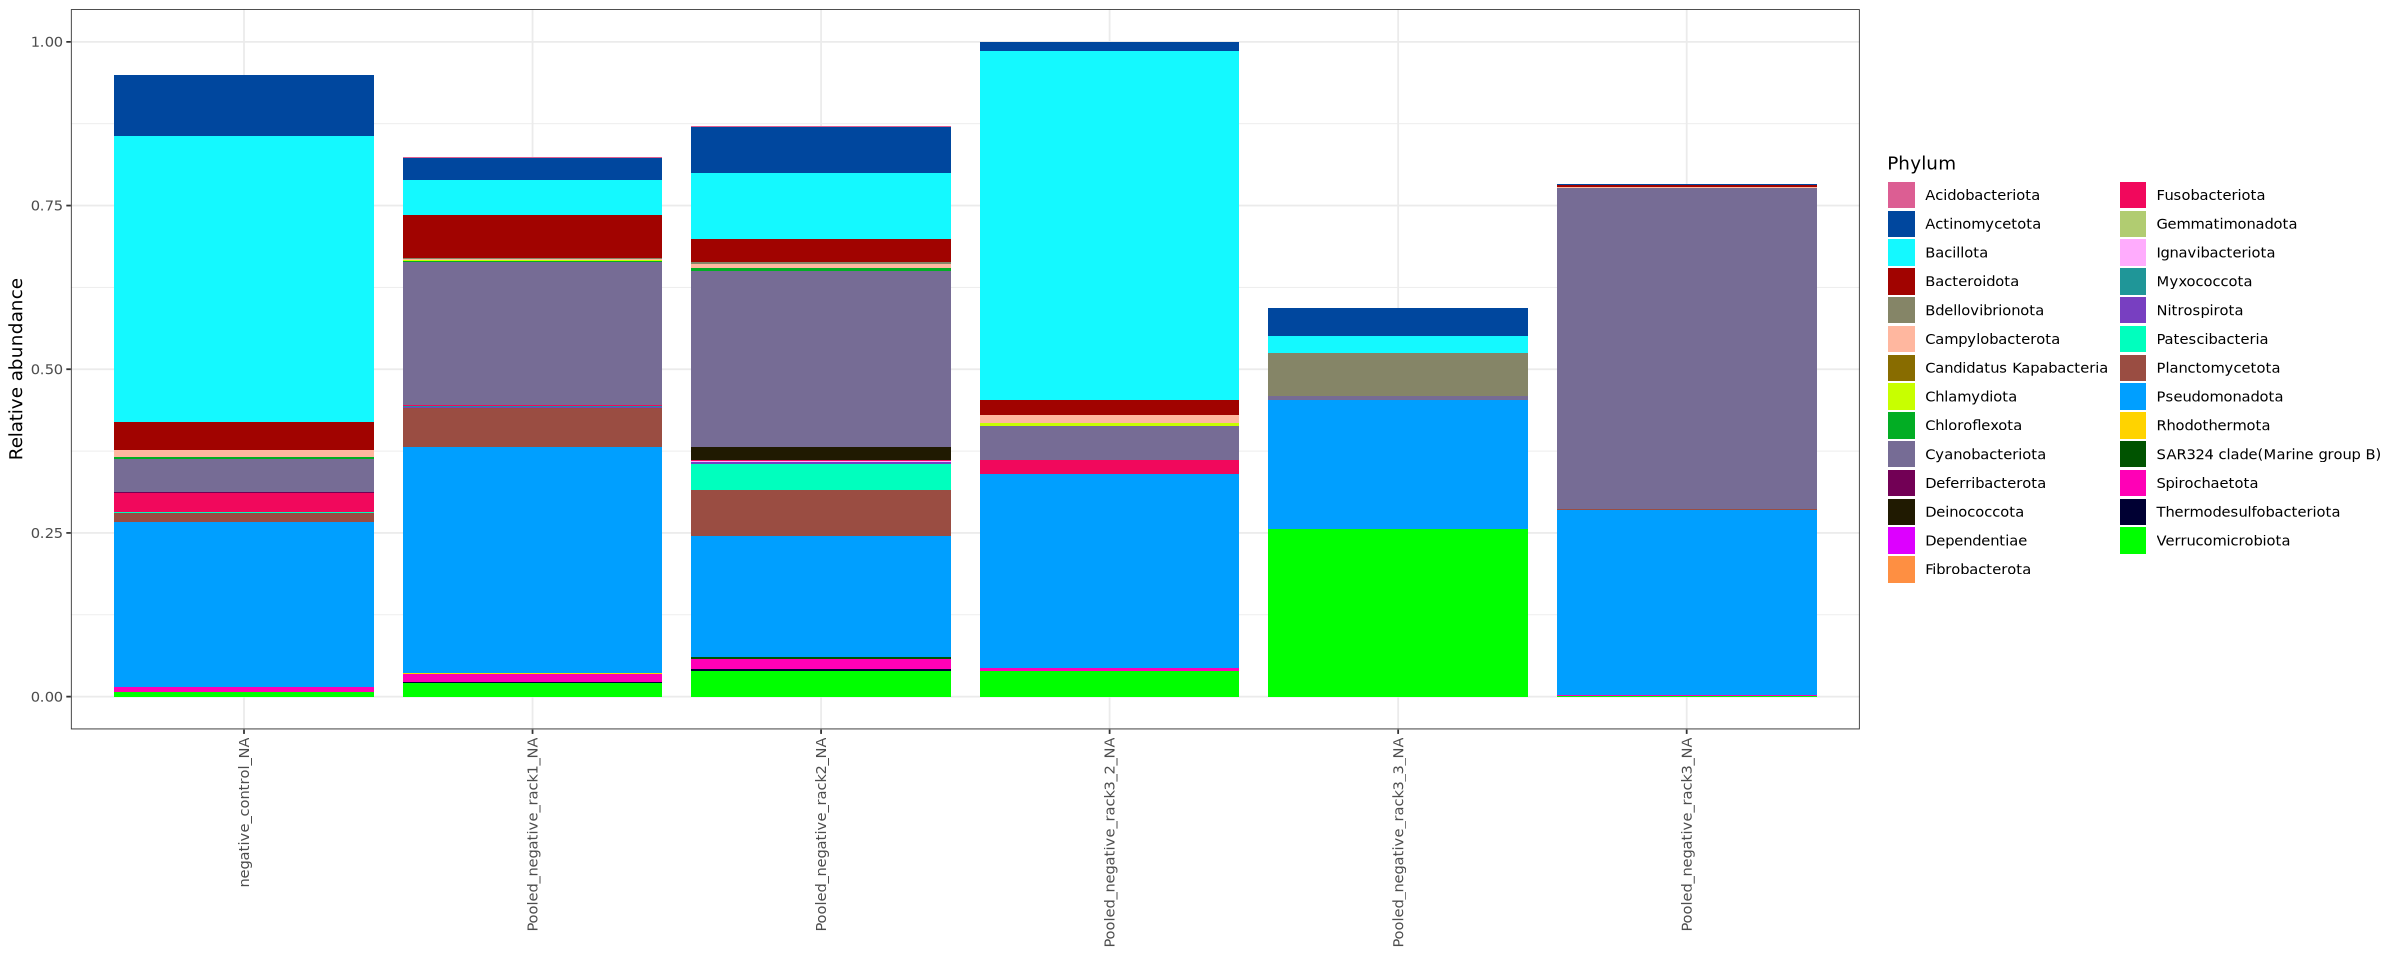

In [117]:
# Plot negatives relative abundance bar plot
p_comp_neg <- neg_df %>% filter(Kingdom == "Bacteria") %>% 
  ggplot(aes(x = Sample, y = Abundance, fill = Phylum)) +
  geom_col() +
  scale_fill_manual(values = colors) +
  labs(x = NULL, y = "Relative abundance", fill = "Phylum") +
  theme_bw() +
  theme(axis.text.x = element_text(angle = 90, hjust = 1, vjust = 0.5), legend.position = "right")  

p_comp_neg

Negative_control was empty sample from Trizol extraction. Pooled_negative are PCR water negatives.

- Negative sample: ~3k reads
- Negative pooled rack 1: ~9.5k reads
- Negative pooled rack 2: ~13.5k reads
- Negative pooled rack 3.2: ~500 reads*
- Negative pooled rack 3.3: ~28k reads
    - Higher relative abundance of verrucomicrobiota, present but not very abundant in the negative sample
    - Also bdellovibrionota presence which I've not really seen before in the literature
    - High proportion of non-bacteria reads (~40%)
- Negative pooled rack 3.1: ~71k reads
    - Predominantly cyanobacteriota and pseudomonadota
    - High proprotion of non-bacteria reads (~25%)

*Negative pooled rack 3.2 is part of the "failed" samples indexed on July 8th (reads < 10k), but odd that this composition so strongly mirrors the negative control

### PCoA

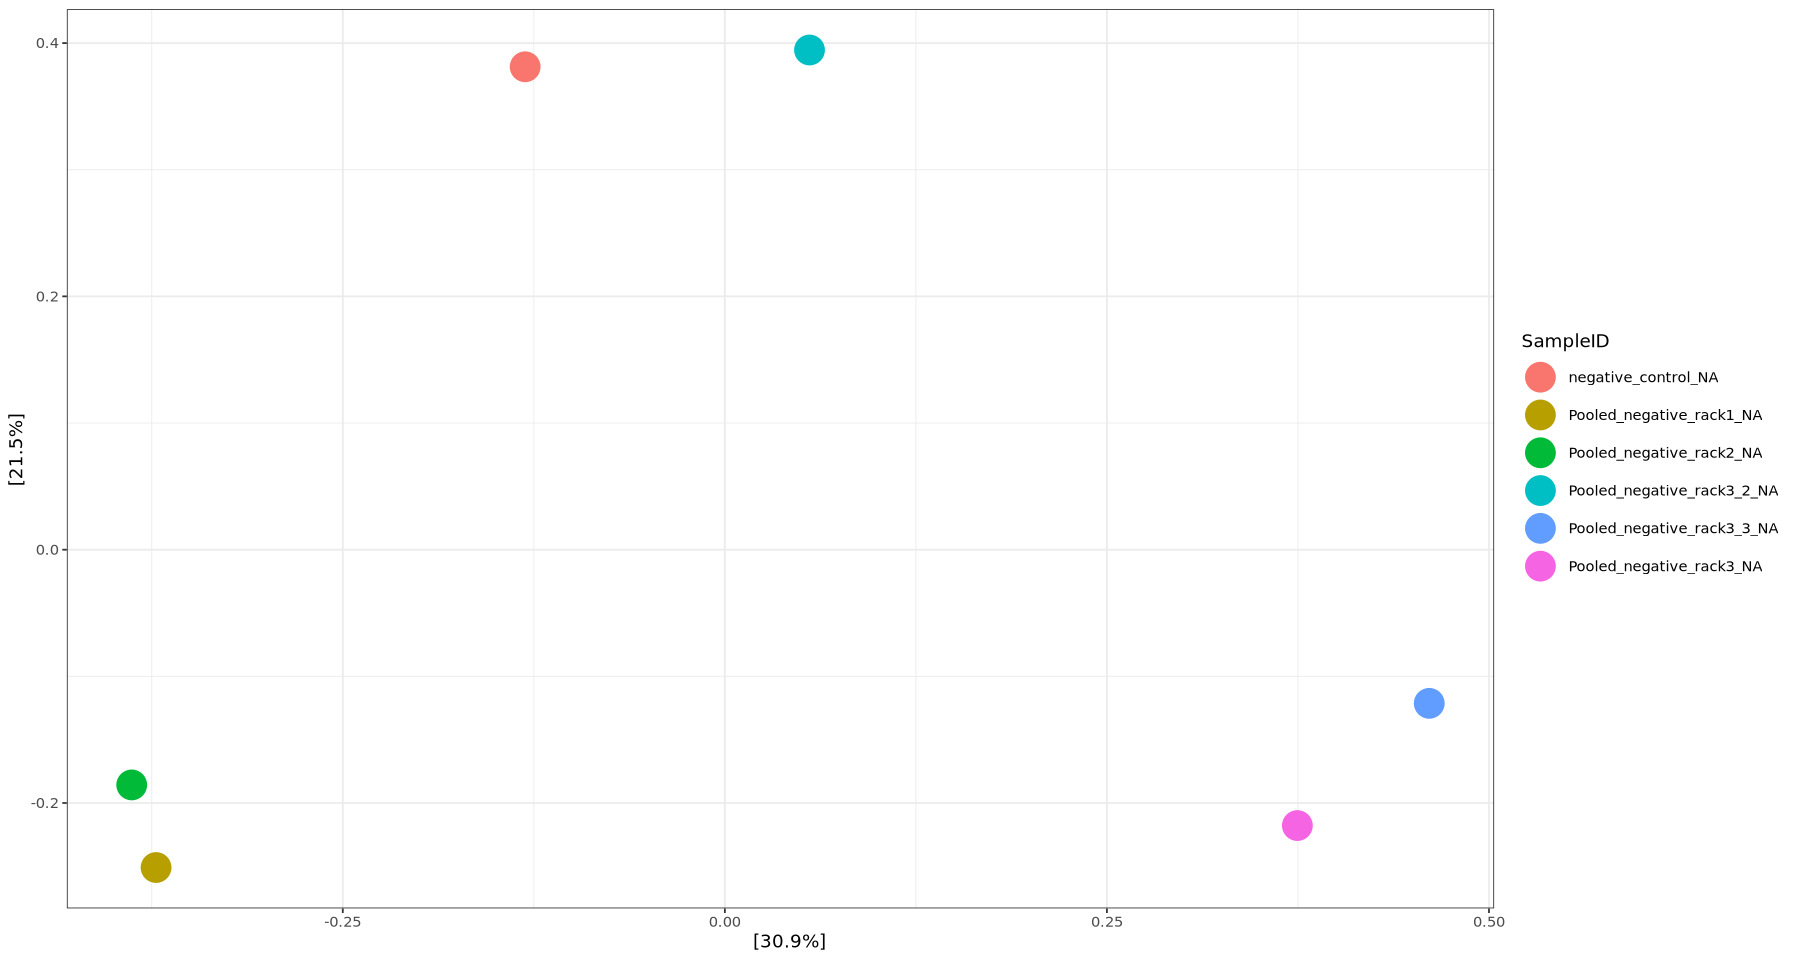

In [60]:
# PCoA ordination of negative controls
neg.ord <- ordinate(ps_neg_rel, "PCoA", "bray")

# Convert row names to a new column and plot PCoA
sample_data(ps_neg_rel)$SampleID <- rownames(sample_data(ps_neg_rel))
plot_ordination(ps_neg_rel, neg.ord, color = "SampleID") +
    geom_point(size=8) +
    theme_bw()

Negative pooled rack 3.1 and 3.2 clustering is more likely due to high number of reads as opposed to composition. On the flipside, it does make sense that the negative sample and the negative pooled rack 3.2 cluster, based on the composition plot.